# Chapter 11 — Decision Trees and Ensembles

*Every model of the previous chapters computes one number from the features by a single formula that is the same everywhere in the input space: a linear function, perhaps of a nonlinear feature map, or a kernel expansion. A decision tree does the opposite. It asks a sequence of yes/no questions about single features ("is the worst perimeter below 112.8?"), and the answer to each question decides which question comes next, so that different regions of the input space are described by different, simple rules. This chapter derives how such a tree is grown and pruned, why a single tree is a fragile model, and how averaging many trees (bagging and random forests) or adding them one after the other (boosting) turns it into one of the strongest general-purpose methods for tabular data.*

## 11.1 Learning objectives

Chapter 4 ended with the observation that the best neighborhood for a point depends on the point, and Chapter 10 with the observation that the useful features depend on the region of the input space as well as on the problem. A decision tree builds both dependencies into the model: it chooses its neighborhoods and its features from the data, region by region. The price is a model with high variance, and the second half of the chapter is about how to remove that variance, or the bias, by combining many trees.

After working through the chapter you will be able to:

1. write a **regression tree** as a piecewise-constant function on a partition of the feature space into boxes, prove that the best constant in each box is the mean of the targets, derive the **gain of a split** and the cost of finding it, and implement the greedy algorithm from scratch;
2. define the **impurity** measures of classification (Gini index, entropy, misclassification rate), prove that every split of a concave impurity can only decrease it, and show that the Gini index is the squared error on one-hot targets;
3. prune a tree by **cost-complexity pruning**, prove that the optimal subtrees form a nested sequence indexed by the penalty, and choose the penalty by cross-validation with the one-standard-error rule of Chapter 5;
4. state the **inductive bias** of trees (invariance to monotone transformations of the features, adaptive neighborhoods, indifference to irrelevant features, axis-aligned boundaries) and measure it against the methods of the earlier chapters;
5. prove that the **variance of an average** of correlated predictors is $\rho\sigma^2 + (1-\rho)\sigma^2/B$, derive **bagging**, the **out-of-bag** estimate of the error and **random forests**, and measure $\rho$, $\sigma^2$ and the effect of the number of trees on real data;
6. compute and interpret feature importances (impurity-based and permutation), and explain why they are biased, why correlated features share the credit, and how selection on importances leaks the labels when it is done outside the cross-validation loop;
7. derive **AdaBoost** as stagewise minimization of the exponential loss and prove its bound on the training error; derive **gradient boosting** as gradient descent in a space of functions, with the Newton (second-order, regularized) leaf values and split gain used by modern implementations;
8. explain why the probabilities of trees and ensembles must be recalibrated, and recalibrate them with Platt scaling (Section 8.7.3), and compare trees, forests and boosting with the linear, margin and kernel methods of the earlier chapters on the same three data sets with the same protocol.

We use the three data sets of Chapters 6 to 10 with the same splits: **Diabetes** ($331/111$ patients, regression), **Breast Cancer** (stratified $426/143$, malignant $=1$, binary classification) and **Digits** (stratified $1347/450$, ten classes). The test sets are touched only in Section 11.11, as in the other chapters; exploratory curves in the earlier sections use the training set or, when they are drawn on the test set to illustrate a point, say so, and when two implementations of the same algorithm are compared on the test inputs only their *agreement* is looked at, not their error.

In [1]:
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer, load_diabetes, load_digits
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.ensemble import (AdaBoostClassifier, BaggingRegressor, GradientBoostingClassifier,
                              GradientBoostingRegressor, HistGradientBoostingClassifier,
                              HistGradientBoostingRegressor, RandomForestClassifier, RandomForestRegressor)
from sklearn.exceptions import ConvergenceWarning
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression, LogisticRegression, RidgeCV
from sklearn.metrics import brier_score_loss, log_loss, make_scorer, zero_one_loss
from sklearn.model_selection import (GridSearchCV, KFold, StratifiedKFold, cross_val_predict, cross_val_score,
                                     train_test_split)
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree

warnings.filterwarnings("ignore", category=ConvergenceWarning)

SEED = 42  # fixed seed: random operations give the same result every time

# Plotting style used throughout the book (Okabe-Ito colors, safe for color-vision deficiencies).
BLUE, ORANGE, GREEN = "#0072B2", "#E69F00", "#009E73"
VERMILION, SKY, PURPLE = "#D55E00", "#56B4E9", "#CC79A7"
plt.rcParams.update({
    "figure.dpi": 110,
    "figure.figsize": (6.4, 4.0),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "font.size": 11,
    "axes.titlesize": 12,
    "axes.labelsize": 11,
})

# The three data sets and the splits of the previous chapters.
diab = load_diabetes()
diab_names = list(diab.feature_names)
Xd_tr, Xd_te, yd_tr, yd_te = train_test_split(diab.data, diab.target, test_size=0.25, random_state=SEED)

bc = load_breast_cancer()
bc_names = list(bc.feature_names)
bc_y_all = 1 - bc.target                                        # malignant = 1, as in Chapter 6
Xb_tr, Xb_te, yb_tr, yb_te = train_test_split(bc.data, bc_y_all, test_size=0.25, random_state=SEED, stratify=bc_y_all)

dg = load_digits()
Xg_tr, Xg_te, yg_tr, yg_te = train_test_split(dg.data, dg.target, test_size=0.25, random_state=SEED, stratify=dg.target)


def rmse(pred, y):
    return float(np.sqrt(np.mean((np.asarray(pred) - np.asarray(y)) ** 2)))


print(f"Diabetes: {Xd_tr.shape[0]}/{Xd_te.shape[0]} patients, {Xd_tr.shape[1]} features;"
      f"  Breast Cancer: {Xb_tr.shape[0]}/{Xb_te.shape[0]}, {Xb_tr.shape[1]} features;"
      f"  Digits: {Xg_tr.shape[0]}/{Xg_te.shape[0]}, {Xg_tr.shape[1]} pixels")

Diabetes: 331/111 patients, 10 features;  Breast Cancer: 426/143, 30 features;  Digits: 1347/450, 64 pixels


## 11.2 Regression trees

### 11.2.1 Partitions and piecewise-constant functions

A decision tree is a way of writing a function that is constant on each box of a partition of the feature space.

:::{admonition} Definition 11.1 (decision tree)
:class: tip
A **binary decision tree** on $\mathbb{R}^p$ is a rooted binary tree in which every *internal node* $t$ carries a **split** $(j_t, s_t)$, a feature index and a threshold, and has a left and a right child; every *leaf* $m$ carries a prediction $c_m$. An input $\mathbf{x}$ is sent from the root to a leaf: at node $t$ it goes left if $x_{j_t}\le s_t$ and right otherwise. The leaves correspond to **boxes** $R_1,\dots,R_M$ (products of intervals) that partition $\mathbb{R}^p$, and the tree computes
$$
f_T(\mathbf{x}) = \sum_{m=1}^{M} c_m\,\mathbb{I}[\mathbf{x}\in R_m].
$$
The **depth** of a leaf is the number of splits on the path from the root, and $\lvert T\rvert = M$ is the number of leaves.
:::

So a tree is a piecewise-constant function, and two things have to be chosen: the partition and the constants. The second choice is trivial.

:::{admonition} Proposition 11.1 (the best constant in a box is the mean)
:class: tip
Given a partition $R_1,\dots,R_M$ and training data $(\mathbf{x}_i,y_i)$, the constants that minimize the training squared error $\sum_i (y_i-f_T(\mathbf{x}_i))^2$ are the means $c_m = \bar y_m = \frac1{n_m}\sum_{i:\mathbf{x}_i\in R_m}y_i$ of the targets that fall in each box (any $c_m$ if the box is empty), and the minimal value is the **residual sum of squares** $\mathrm{RSS}(T)=\sum_m \mathrm{RSS}(R_m)$ with $\mathrm{RSS}(R_m) = \sum_{i\in R_m}(y_i-\bar y_m)^2$.
:::

*Proof.* The sum splits into one sum per box, and in box $m$ the quantity $\sum_{i\in R_m}(y_i-c)^2$ is a parabola in $c$ whose derivative $-2\sum_{i\in R_m}(y_i-c)$ vanishes at $c=\bar y_m$. $\blacksquare$

The prediction at a new point is therefore the **average of the targets of the training points that fall in the same box**: a tree is a local average, exactly like $k$-NN regression in Chapter 4, with one difference that will matter throughout the chapter. The neighbors of $\mathbf{x}$ are not the $k$ nearest points in a fixed distance but the points that share a box with $\mathbf{x}$, and the *boxes are learned from the targets*.

### 11.2.2 Growing a tree: the gain of a split

Choosing the best partition into $M$ boxes is a combinatorial problem that is NP-complete (Hyafil and Rivest, 1976), so every practical algorithm is **greedy**: start with all the data in one box (the root), find the single best split, and apply the same procedure recursively to the two parts. At a node with the data set $D$ of size $n$ a split $(j,s)$ sends $D_L=\{i:x_{ij}\le s\}$ to the left and $D_R$ to the right, and by Proposition 11.1 the best constants in the new boxes are the means of the two parts. How much does the split reduce the residual sum of squares?

:::{admonition} Proposition 11.2 (gain of a split)
:class: tip
Let $D$ be split into $D_L$ and $D_R$ with sizes $n_L,n_R$, $n=n_L+n_R$ and means $\bar y_L,\bar y_R$. Then
$$
\mathrm{RSS}(D) - \mathrm{RSS}(D_L) - \mathrm{RSS}(D_R) \;=\; \frac{n_Ln_R}{n}\,(\bar y_L-\bar y_R)^2 \;\ge\; 0.
$$
:::

*Proof.* The overall mean is $\bar y = (n_L\bar y_L + n_R\bar y_R)/n$. For a part, $\sum_{i\in D_L}(y_i-\bar y)^2 = \mathrm{RSS}(D_L) + n_L(\bar y_L-\bar y)^2$ (add and subtract $\bar y_L$; the cross term has zero sum). The same holds for $D_R$, so the gain is $n_L(\bar y_L-\bar y)^2+n_R(\bar y_R-\bar y)^2$. Now $\bar y_L-\bar y = \frac{n_R}{n}(\bar y_L-\bar y_R)$ and $\bar y_R-\bar y=-\frac{n_L}{n}(\bar y_L-\bar y_R)$, and
$n_L\frac{n_R^2}{n^2}+n_R\frac{n_L^2}{n^2} = \frac{n_Ln_R(n_R+n_L)}{n^2}=\frac{n_Ln_R}{n}$. $\blacksquare$

A split can never hurt the training error, and the gain is the squared difference between the two means weighted by $n_Ln_R/n$: it is large for splits that separate groups with very different means, and the weight $n_Ln_R/n$ (largest when the sizes are equal) prefers balanced splits to ones that cut off a few points. The best split of a node maximizes this gain over all features $j$ and all thresholds $s$. For one feature only the *order* of its values matters: the partition induced by $s$ changes only when $s$ crosses a data value, so it is enough to consider the $n-1$ midpoints between consecutive distinct sorted values.

:::{admonition} Proposition 11.3 (cost of the search)
:class: tip
After sorting the values of one feature at a node of size $n$, the gains of **all** the $n-1$ candidate thresholds are computed in $O(n)$ time from the prefix sums $\sum_{i\le k}y_{(i)}$ and Proposition 11.2. The search over $p$ features costs $O(pn\log n)$ at one node. Since every training point belongs to exactly one node of each depth, the cost of growing a tree up to depth $D$ is $O(Dpn\log n)$.
:::

*Proof.* With the sorted targets $y_{(1)},\dots,y_{(n)}$ and prefix sums $S_k=\sum_{i\le k}y_{(i)}$, a cut after position $k$ has $n_L=k$, $n_R=n-k$, $\bar y_L=S_k/k$, $\bar y_R=(S_n-S_k)/(n-k)$, which Proposition 11.2 turns into the gain in constant time. Sorting costs $O(n\log n)$ per feature, and the sum of the node sizes at one depth is at most $n$. $\blacksquare$

(Implementations avoid most of the sorting by sorting each feature once, or by binning the features into at most 255 bins as the histogram-based algorithms of Section 11.9 do, which makes the cost of a level linear in $n$.) The following code implements the search of Proposition 11.3 and the greedy recursion of this section, and compares them with scikit-learn on Diabetes.

In [2]:
def as_f32(X):
    """scikit-learn casts the features to float32 before growing a tree: values closer than float32 resolution are ties.
    (Diabetes has such near-ties, created by the standardization of the original data, so we do the same.)"""
    return np.asarray(X, dtype=np.float32).astype(np.float64)


def best_split_feature(x, y, min_leaf=1):
    """Best threshold of ONE feature for the squared error (Propositions 11.2 and 11.3).

    Returns (gain, threshold), where gain = RSS(parent) - RSS(left) - RSS(right).
    """
    order = np.argsort(x, kind="stable")
    xs, ys = x[order], y[order]
    n = len(ys)
    prefix = np.cumsum(ys)                      # S_k for k = 1..n
    n_left = np.arange(1, n)                    # a cut after position k puts k points on the left
    n_right = n - n_left
    mean_left = prefix[:-1] / n_left
    mean_right = (prefix[-1] - prefix[:-1]) / n_right
    gain = n_left * n_right / n * (mean_left - mean_right) ** 2
    valid = (xs[:-1] < xs[1:]) & (n_left >= min_leaf) & (n_right >= min_leaf)   # cannot cut between equal values
    if not valid.any():
        return 0.0, None
    k = int(np.argmax(np.where(valid, gain, -np.inf)))
    return float(gain[k]), 0.5 * (xs[k] + xs[k + 1])


def grow(X, y, max_depth, min_leaf=1, depth=0):
    """Greedy recursive binary splitting; a node is a dictionary."""
    node = {"value": float(y.mean()), "n": len(y)}
    if depth == max_depth or len(y) < 2 * min_leaf or np.ptp(y) == 0:
        return node
    best = max((best_split_feature(X[:, j], y, min_leaf) + (j,) for j in range(X.shape[1])), key=lambda g: g[0])
    gain, thr, j = best
    if thr is None or gain <= 0:
        return node
    left = X[:, j] <= thr
    node.update(feature=j, threshold=thr, gain=gain,
                left=grow(X[left], y[left], max_depth, min_leaf, depth + 1),
                right=grow(X[~left], y[~left], max_depth, min_leaf, depth + 1))
    return node


def predict_tree(node, X):
    if "feature" not in node:
        return np.full(len(X), node["value"])
    out = np.empty(len(X))
    left = X[:, node["feature"]] <= node["threshold"]
    out[left] = predict_tree(node["left"], X[left])
    out[~left] = predict_tree(node["right"], X[~left])
    return out


def count_leaves(node):
    return 1 if "feature" not in node else count_leaves(node["left"]) + count_leaves(node["right"])


# 1. the root split of Diabetes: from scratch against scikit-learn
Xd_tr32, Xd_te32 = as_f32(Xd_tr), as_f32(Xd_te)
gains = [(*best_split_feature(Xd_tr32[:, j], yd_tr), diab_names[j]) for j in range(10)]
gains.sort(reverse=True)
print("best split of each feature at the root (gain = reduction of the RSS), best first:")
print(pd.DataFrame(gains, columns=["gain", "threshold", "feature"]).head(4).to_string(index=False, float_format=lambda v: f"{v:.5g}"))
sk1 = DecisionTreeRegressor(max_depth=1, random_state=SEED).fit(Xd_tr, yd_tr)
print(f"scikit-learn root split: feature {diab_names[sk1.tree_.feature[0]]}, threshold {sk1.tree_.threshold[0]:.6f}")
rss_root = float(((yd_tr - yd_tr.mean()) ** 2).sum())
print(f"the best split removes {gains[0][0] / rss_root:.1%} of the residual sum of squares of the root ({rss_root:.4g})")

# 2. whole trees of depth 1..5: predictions of the from-scratch tree and of scikit-learn
rows = []
for depth in range(1, 6):
    mine = grow(Xd_tr32, yd_tr, depth)
    sk = DecisionTreeRegressor(max_depth=depth, random_state=SEED).fit(Xd_tr, yd_tr)
    rows.append({"depth": depth, "leaves (ours)": count_leaves(mine), "leaves (sklearn)": sk.get_n_leaves(),
                 "max |difference| of predictions": float(np.abs(predict_tree(mine, Xd_te32) - sk.predict(Xd_te)).max())})
print()
print(pd.DataFrame(rows).to_string(index=False, float_format=lambda v: f"{v:.2g}"))


def first_differences(node, sk, idx, X, y, path="root"):
    """Walk the two depth-4 trees together and report the nodes where they choose different splits."""
    t = sk.tree_
    if "feature" not in node or t.children_left[idx] == -1:
        return
    if t.feature[idx] != node["feature"] or abs(t.threshold[idx] - node["threshold"]) > 1e-6:
        print(f"  node {path} ({len(y)} patients): ours {diab_names[node['feature']]} (gain {node['gain']:.2f}),"
              f" scikit-learn {diab_names[t.feature[idx]]} (gain {best_split_feature(X[:, t.feature[idx]], y)[0]:.2f})")
        return
    mask = X[:, node["feature"]] <= node["threshold"]
    first_differences(node["left"], sk, t.children_left[idx], X[mask], y[mask], path + "L")
    first_differences(node["right"], sk, t.children_right[idx], X[~mask], y[~mask], path + "R")


print("\nwhere do the depth-4 trees choose different splits?")
first_differences(grow(Xd_tr32, yd_tr, 4), DecisionTreeRegressor(max_depth=4, random_state=SEED).fit(Xd_tr, yd_tr), 0, Xd_tr32, yd_tr)

# 3. the cost of one search, as the number of points doubles (Proposition 11.3): the ratio of the times should be close to 2
rng = np.random.default_rng(SEED)
times = []
for n in [20_000, 40_000, 80_000, 160_000]:
    x, y = rng.standard_normal(n), rng.standard_normal(n)
    t0 = time.perf_counter()
    for _ in range(5):
        best_split_feature(x, y)
    times.append((time.perf_counter() - t0) / 5)
print("\nratio of the time of one search when n doubles:", " ".join(f"{b / a:.1f}" for a, b in zip(times[:-1], times[1:])))

best split of each feature at the root (gain = reduction of the RSS), best first:
      gain   threshold feature
5.8113e+05   0.0051111     bmi
5.3243e+05 -0.00016963      s5
3.9316e+05    0.023594      bp
3.3146e+05  -0.0048063      s4
scikit-learn root split: feature bmi, threshold 0.005111
the best split removes 29.0% of the residual sum of squares of the root (2.001e+06)

 depth  leaves (ours)  leaves (sklearn)  max |difference| of predictions
     1              2                 2                                0
     2              4                 4                                0
     3              8                 8                                0
     4             16                16                               89
     5             31                31                          1.4e+02

where do the depth-4 trees choose different splits?
  node rootLRR (3 patients): ours age (gain 1908.17), scikit-learn s1 (gain 1908.17)
  node rootRRR (8 patients): ours bp (gain 11

The code shows three things. First, the best split of each feature (the rows of the first table) and the winner agree with scikit-learn: the root of the Diabetes tree splits on the body mass index (`bmi`) at a threshold of $0.0051$ (the features are in the standardized units of the data set), which removes $29.0\%$ of the residual sum of squares of the root in one step; the next best features are `s5` and `bp`. Second, our recursion and scikit-learn produce the same predictions for depths $1$, $2$ and $3$ (differences of $0$). At depth $4$ the two trees differ, and the last printed lines show why: in two small nodes (of $3$ and $8$ patients) two *different* splits have *exactly the same gain*, so that the greedy rule does not determine the tree; scikit-learn breaks such ties by a random permutation of the features (hence the argument `random_state`), our code takes the first. Both trees are legitimate outputs of the same greedy algorithm, and this will matter later: **when several splits are equally good, the choice is arbitrary, and nearly equal splits make the tree unstable** (Section 11.5). (A technical remark: scikit-learn converts the features to single precision before growing a tree, which turns the near-ties created by the standardization of Diabetes into exact ties; `as_f32` does the same.) Third, the time of one search grows by a factor of about $2$ to $2.5$ when $n$ doubles (the exact ratios depend on the machine), as the $O(n\log n)$ of Proposition 11.3 predicts.

### 11.2.3 A worked example by hand

:::{admonition} Worked example 11.1 (the first split of a six-point data set)
:class: tip
*(Constructed data, to be checked by hand.)* One feature, six points: $x=(1,2,3,4,5,6)$ and $y=(1,2,1,7,8,9)$. The sum of squares around the mean $\bar y=28/6$ is $\mathrm{RSS}=\sum y_i^2 - 6\bar y^2 = 200-130.67 = 69.33$. The five candidate thresholds $1.5,\dots,5.5$ have $n_L=1,\dots,5$ and, by Proposition 11.2, gains $\frac{n_Ln_R}{6}(\bar y_L-\bar y_R)^2$.
:::

In [3]:
x_ex = np.array([1., 2., 3., 4., 5., 6.])
y_ex = np.array([1., 2., 1., 7., 8., 9.])
rss_total = float(((y_ex - y_ex.mean()) ** 2).sum())
rows = []
for k in range(1, 6):
    yl, yr = y_ex[:k], y_ex[k:]
    gain = k * (6 - k) / 6 * (yl.mean() - yr.mean()) ** 2
    direct = rss_total - ((yl - yl.mean()) ** 2).sum() - ((yr - yr.mean()) ** 2).sum()
    rows.append({"threshold": x_ex[k - 1] + 0.5, "n_L": k, "mean left": yl.mean(), "mean right": yr.mean(),
                 "gain (Prop. 11.2)": gain, "gain (direct RSS)": direct})
print(f"RSS of the root = {rss_total:.2f}")
print(pd.DataFrame(rows).to_string(index=False, float_format=lambda v: f"{v:.2f}"))
print("best threshold from the scan:", best_split_feature(x_ex, y_ex))

RSS of the root = 69.33
 threshold  n_L  mean left  mean right  gain (Prop. 11.2)  gain (direct RSS)
      1.50    1       1.00        5.40              16.13              16.13
      2.50    2       1.50        6.25              30.08              30.08
      3.50    3       1.33        8.00              66.67              66.67
      4.50    4       2.75        8.50              44.08              44.08
      5.50    5       3.80        9.00              22.53              22.53
best threshold from the scan: (66.66666666666667, np.float64(3.5))


The scan finds the threshold $3.5$, which separates $(1,2,1)$ from $(7,8,9)$, and the gain of $66.67$ removes $96\%$ of the root's $69.33$; the other thresholds gain less, and the first one, which cuts off the single point $x=1$, gains only $16.13$ even though its left mean is far from its right mean, because the weight $n_Ln_R/n=5/6$ is small. The two columns of gains (Proposition 11.2 and the direct computation of the three residual sums of squares) agree to all printed digits. After this split each child is a node of its own, and the recursion would continue with $(1,2,1)$ and $(7,8,9)$ separately.

### 11.2.4 What a tree looks like

Figure 11.1 shows regression trees on Diabetes. Panel (a) uses the single feature `bmi`: the fit is a staircase, with one step more for every extra split, and the full tree ends with one leaf per distinct value, interpolating the training points. Panel (b) uses two features, `bmi` and `s5`, and draws the partition of the plane into boxes made by a tree with $8$ leaves: the lines are all horizontal or vertical, and each box carries one constant. The table printed before the figure gives the training and test error of trees of increasing depth (all features).

max depth  leaves  train RMSE  test RMSE
        1       2        65.5       65.9
        2       4        58.3       59.5
        3       8        54.5       59.3
        4      16        50.2       59.7
        6      54        37.4       66.7
        8     123        26.1       71.7
     none     324         0.0       77.1

reference (Chapter 6): constant prediction 74.88, least squares 53.37 (test RMSE)


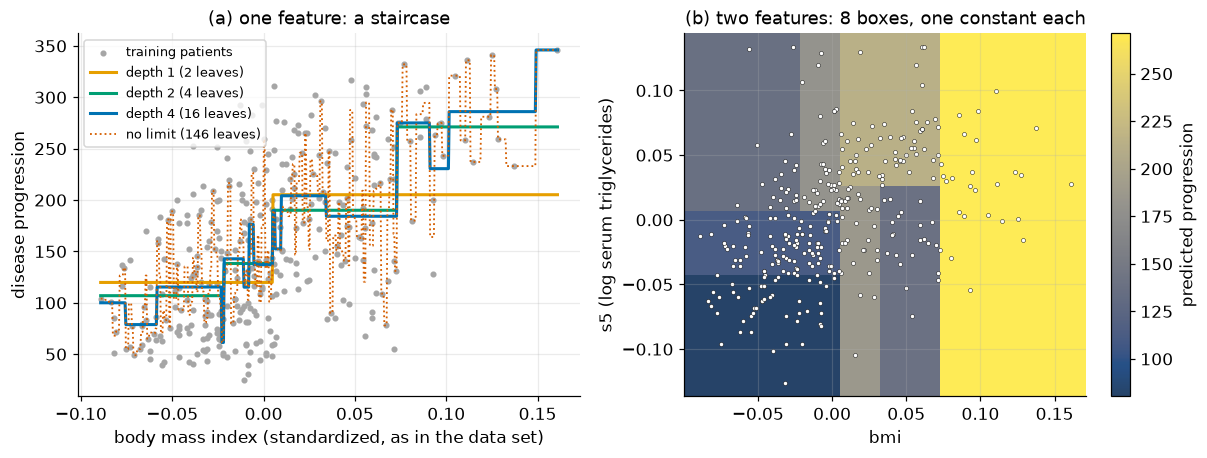

In [4]:
rows = []
for depth in [1, 2, 3, 4, 6, 8, None]:
    t = DecisionTreeRegressor(max_depth=depth, random_state=SEED).fit(Xd_tr, yd_tr)
    rows.append({"max depth": "none" if depth is None else depth, "leaves": t.get_n_leaves(),
                 "train RMSE": rmse(t.predict(Xd_tr), yd_tr), "test RMSE": rmse(t.predict(Xd_te), yd_te)})
tree_table = pd.DataFrame(rows)
print(tree_table.to_string(index=False, float_format=lambda v: f"{v:.1f}"))
ols_d = LinearRegression().fit(Xd_tr, yd_tr)
print(f"\nreference (Chapter 6): constant prediction {rmse(np.full(len(yd_te), yd_tr.mean()), yd_te):.2f},"
      f" least squares {rmse(ols_d.predict(Xd_te), yd_te):.2f} (test RMSE)")


def figure_11_1():
    fig, axes = plt.subplots(1, 2, figsize=(11.2, 4.3))
    ax = axes[0]
    j = diab_names.index("bmi")
    xg = np.linspace(Xd_tr[:, j].min(), Xd_tr[:, j].max(), 600)
    ax.scatter(Xd_tr[:, j], yd_tr, s=9, color="0.65", label="training patients")
    for depth, color, ls in [(1, ORANGE, "-"), (2, GREEN, "-"), (4, BLUE, "-"), (None, VERMILION, ":")]:
        t = DecisionTreeRegressor(max_depth=depth, random_state=SEED).fit(Xd_tr[:, [j]], yd_tr)
        lab = "no limit" if depth is None else f"depth {depth}"
        ax.plot(xg, t.predict(xg[:, None]), color=color, ls=ls, lw=2 if depth else 1.2, label=f"{lab} ({t.get_n_leaves()} leaves)")
    ax.set_xlabel("body mass index (standardized, as in the data set)")
    ax.set_ylabel("disease progression")
    ax.set_title("(a) one feature: a staircase")
    ax.legend(fontsize=8.5, loc="upper left")

    ax = axes[1]
    ja, jb = diab_names.index("bmi"), diab_names.index("s5")
    t = DecisionTreeRegressor(max_leaf_nodes=8, random_state=SEED).fit(Xd_tr[:, [ja, jb]], yd_tr)
    g1 = np.linspace(Xd_tr[:, ja].min() - 0.01, Xd_tr[:, ja].max() + 0.01, 300)
    g2 = np.linspace(Xd_tr[:, jb].min() - 0.01, Xd_tr[:, jb].max() + 0.01, 300)
    G1, G2 = np.meshgrid(g1, g2)
    P = t.predict(np.c_[G1.ravel(), G2.ravel()]).reshape(G1.shape)
    im = ax.pcolormesh(G1, G2, P, cmap="cividis", shading="auto", alpha=0.85)
    ax.scatter(Xd_tr[:, ja], Xd_tr[:, jb], c="white", s=7, edgecolor="k", linewidth=0.3)
    ax.set_xlabel("bmi")
    ax.set_ylabel("s5 (log serum triglycerides)")
    ax.set_title(f"(b) two features: {t.get_n_leaves()} boxes, one constant each")
    fig.colorbar(im, ax=ax, label="predicted progression")
    fig.tight_layout()
    return fig


figure_11_1()
plt.show()

The table of the depth shows the pattern of this chapter. The training error falls steadily, from $65.5$ with a single split to $0$ for the tree with no limit, which has $324$ leaves for $331$ patients (almost one leaf per patient: the tree interpolates the data). The test error does not follow: it falls from $65.9$ to $59.5$ and $59.3$ for depths $2$ and $3$, and then rises, to $66.7$ at depth $6$ and to $77.1$ for the full tree, **worse than the constant prediction of the mean ($74.88$) that ignores all the features**. A tree that is too deep is a lookup table of the training set, with the high variance of a $1$-nearest-neighbor rule, and the shallow tree that does best has a test RMSE of $59.3$, against $53.37$ for least squares (Chapter 6): on Diabetes a handful of boxes cannot match a linear model. (The numbers of the test set are used here to show the shape of the curve; choosing the depth by looking at them would be the mistake of Chapter 5, and Section 11.4 chooses the size of the tree by cross-validation.) In Figure 11.1(a) the same thing is visible as a staircase: depth $1$ gives two levels, depth $2$ gives four, depth $4$ follows the cloud with sixteen steps, and the tree without limit jumps from one patient to the next. Panel (b) shows the partition that a tree with $8$ leaves makes of the plane of two features: every boundary is parallel to an axis, and the prediction increases with both the body mass index and the triglycerides.

## 11.3 Classification trees and impurity

### 11.3.1 Node impurity

For a classification problem with $K$ classes the leaf $m$ holds the **class proportions** $\hat p_{mk}=\frac1{n_m}\#\{i\in R_m:y_i=k\}$, predicts the majority class, and may report $\hat p_{mk}$ as its estimate of $\mathbb{P}(y=k\mid\mathbf{x}\in R_m)$ (we shall see in Section 11.10 that this estimate is poor). The squared error of the regression tree is replaced by a measure of how *mixed* a node is.

:::{admonition} Definition 11.2 (impurity)
:class: tip
An **impurity** is a function $\varphi$ of the class proportions $\hat{\mathbf{p}}=(\hat p_1,\dots,\hat p_K)$, concave on the simplex, symmetric in its arguments and zero at the vertices (a pure node). The three standard ones are
$$
\text{misclassification rate: }\ 1-\max_k\hat p_k,\qquad
\text{Gini index: }\ G=\sum_{k}\hat p_k(1-\hat p_k)=1-\sum_k\hat p_k^2,\qquad
\text{entropy: }\ H=-\sum_k\hat p_k\ln\hat p_k .
$$
The **gain** of a split of a node $D$ into $D_L,D_R$ is $\Delta\varphi=\varphi(\hat{\mathbf{p}}_D)-\frac{n_L}{n}\varphi(\hat{\mathbf{p}}_L)-\frac{n_R}{n}\varphi(\hat{\mathbf{p}}_R)$, and the tree is grown by maximizing it, exactly as in the regression case.
:::

:::{admonition} Proposition 11.4 (a split never increases a concave impurity)
:class: tip
For every concave $\varphi$ and every split, $\Delta\varphi\ge 0$. If $\varphi$ is strictly concave, $\Delta\varphi=0$ only if $\hat{\mathbf{p}}_L=\hat{\mathbf{p}}_R$, that is, only if the split does not change the class proportions.
:::

*Proof.* The proportions of the parent are the weighted average $\hat{\mathbf{p}}_D=\frac{n_L}{n}\hat{\mathbf{p}}_L+\frac{n_R}{n}\hat{\mathbf{p}}_R$ of those of the children, so Jensen's inequality for the concave $\varphi$ gives $\varphi(\hat{\mathbf{p}}_D)\ge\frac{n_L}{n}\varphi(\hat{\mathbf{p}}_L)+\frac{n_R}{n}\varphi(\hat{\mathbf{p}}_R)$, with equality for strictly concave $\varphi$ only if the two points coincide. $\blacksquare$

The Gini index and the entropy are strictly concave, but the misclassification rate is only *piecewise linear*: it is not strictly concave, and it can give a gain of exactly zero to a split that has made the node visibly purer. The standard example has $400$ examples of each of two classes. Split A produces two children with $(300,100)$ and $(100,300)$ examples of the two classes; split B produces $(200,400)$ and $(200,0)$. Both misclassify $200$ of the $800$ examples, so the misclassification rate cannot tell them apart, although B has isolated a pure node and A has not.

In [5]:
def impurities(counts):
    """Misclassification rate, Gini index and entropy (nats) from a vector of class counts."""
    p = np.asarray(counts, float) / np.sum(counts)
    nz = p[p > 0]
    return 1 - p.max(), 1 - np.sum(p ** 2), -np.sum(nz * np.log(nz))


def split_gain(parent, left, right):
    n, nl, nr = np.sum(parent), np.sum(left), np.sum(right)
    return [impurities(parent)[i] - nl / n * impurities(left)[i] - nr / n * impurities(right)[i] for i in range(3)]


parent = (400, 400)
rows = []
for name, (left, right) in {"A: (300,100) + (100,300)": ((300, 100), (100, 300)),
                            "B: (200,400) + (200,0)": ((200, 400), (200, 0))}.items():
    g = split_gain(parent, left, right)
    rows.append({"split": name, "misclassification": g[0], "Gini": g[1], "entropy": g[2]})
print("gain of the two splits of a node with (400, 400) examples:")
print(pd.DataFrame(rows).to_string(index=False, float_format=lambda v: f"{v:.4f}"))

gain of the two splits of a node with (400, 400) examples:
                   split  misclassification   Gini  entropy
A: (300,100) + (100,300)             0.2500 0.1250   0.1308
  B: (200,400) + (200,0)             0.2500 0.1667   0.2158


The two splits have the same misclassification gain ($0.25$), because both leave $200$ of the $800$ examples misclassified, but B has the larger gain in the Gini index ($0.1667$ against $0.1250$) and in the entropy ($0.2158$ against $0.1308$), as it should: the pure node of B can be left alone, and the other node has only one more split to make. The strictly concave impurities reward progress that is *not yet visible in the error rate*, and this is why trees are grown with the Gini index or the entropy and not with the misclassification rate, which is nevertheless often the criterion used to *prune* (Section 11.4).

### 11.3.2 Gini is a squared error

The Gini index has a second interpretation that links this section to the previous one. Code the class of the $i$-th example as the one-hot vector $\mathbf{e}_{y_i}\in\{0,1\}^K$.

:::{admonition} Proposition 11.5 (Gini = squared error on one-hot targets)
:class: tip
For a node with $n$ examples and class proportions $\hat{\mathbf{p}}$, the residual sum of squares of the one-hot targets around their mean $\hat{\mathbf{p}}$ is $\sum_i\lVert\mathbf{e}_{y_i}-\hat{\mathbf{p}}\rVert^2=n\,G(\hat{\mathbf{p}})$. Hence the gain of a split in the **Gini index**, multiplied by $n$, is the gain of Proposition 11.2 summed over the $K$ coordinates of the one-hot target: *a classification tree grown with the Gini index is a regression tree for the one-hot targets*, and a leaf's class proportions are the means of the targets in the box (Proposition 11.1).
:::

*Proof.* $\lVert\mathbf{e}_{y_i}-\hat{\mathbf{p}}\rVert^2 = 1-2\hat p_{y_i}+\sum_k\hat p_k^2$, and summing over $i$, $\sum_i\hat p_{y_i}=\sum_k n\hat p_k\hat p_k = n\sum_k\hat p_k^2$, so the total is $n-2n\sum\hat p_k^2+n\sum\hat p_k^2 = n(1-\sum_k\hat p_k^2)$. The statement on the gain follows because Proposition 11.2 holds coordinate by coordinate. $\blacksquare$

This is why the regression tree of Section 11.2 and the classification tree of this section are one algorithm, and why the probability estimates of a leaf are means (and carry the problems of means of few numbers, Section 11.10). The next cell checks the proposition on the root of the Breast Cancer tree, and shows how the three criteria rank the thresholds of the feature that the tree uses at the root.

In [6]:
def best_split_gini(x, y, K=2):
    """Best threshold of one feature for the Gini index, from the class counts to the left of each cut."""
    order = np.argsort(x, kind="stable")
    xs, ys = x[order], y[order]
    n = len(ys)
    onehot = np.eye(K)[ys]
    left = np.cumsum(onehot, axis=0)[:-1]                       # class counts on the left, for each cut
    right = onehot.sum(axis=0) - left
    nl, nr = left.sum(axis=1), right.sum(axis=1)
    g_left = 1 - ((left / nl[:, None]) ** 2).sum(axis=1)
    g_right = 1 - ((right / nr[:, None]) ** 2).sum(axis=1)
    g_parent = 1 - ((onehot.sum(axis=0) / n) ** 2).sum()
    gain = g_parent - (nl * g_left + nr * g_right) / n
    gain = np.where(xs[:-1] < xs[1:], gain, -np.inf)
    k = int(np.argmax(gain))
    return float(gain[k]), 0.5 * (xs[k] + xs[k + 1]), xs, gain


# the root split of the Breast Cancer tree, found by three routes
res = [(bc_names[j], *best_split_gini(Xb_tr[:, j], yb_tr)[:2]) for j in range(30)]
res.sort(key=lambda r: -r[1])
print("best Gini gain per feature (top 3):")
print(pd.DataFrame(res[:3], columns=["feature", "Gini gain", "threshold"]).to_string(index=False, float_format=lambda v: f"{v:.4f}"))
sk_c = DecisionTreeClassifier(max_depth=1, random_state=SEED).fit(Xb_tr, yb_tr)
print(f"scikit-learn root: {bc_names[sk_c.tree_.feature[0]]} <= {sk_c.tree_.threshold[0]:.4f}")

# Proposition 11.5: n * (Gini gain) equals the sum over the two coordinates of the one-hot target of the RSS gain of Proposition 11.2
j_root = bc_names.index(res[0][0])
n_b = len(yb_tr)
onehot_b = np.eye(2)[yb_tr]
rss_gain = sum(best_split_feature(Xb_tr[:, j_root], onehot_b[:, c])[0] for c in range(2))   # the split is the same for both coordinates
print(f"n x Gini gain = {n_b * res[0][1]:.6f},  sum of the RSS gains on the one-hot targets = {rss_gain:.6f}")

best Gini gain per feature (top 3):
        feature  Gini gain  threshold
worst perimeter     0.3369   112.8000
   worst radius     0.3330    16.7950
     worst area     0.3254   874.8500
scikit-learn root: worst perimeter <= 112.8000
n x Gini gain = 143.540228,  sum of the RSS gains on the one-hot targets = 143.540228


The three routes agree: the root of the Breast Cancer tree splits on the worst perimeter at $112.8$ (a Gini gain of $0.3369$), and $n$ times the Gini gain, $143.540228$, equals the sum of the two squared-error gains on the one-hot targets to all printed digits, as Proposition 11.5 says. Note how close the runners-up are: the worst radius and the worst area, which measure the size of the nuclei like the perimeter, reach $0.3330$ and $0.3254$. The three features are strongly correlated (Section 6.2.4), and a split on any of them is nearly as good; a different sample could easily choose another one.

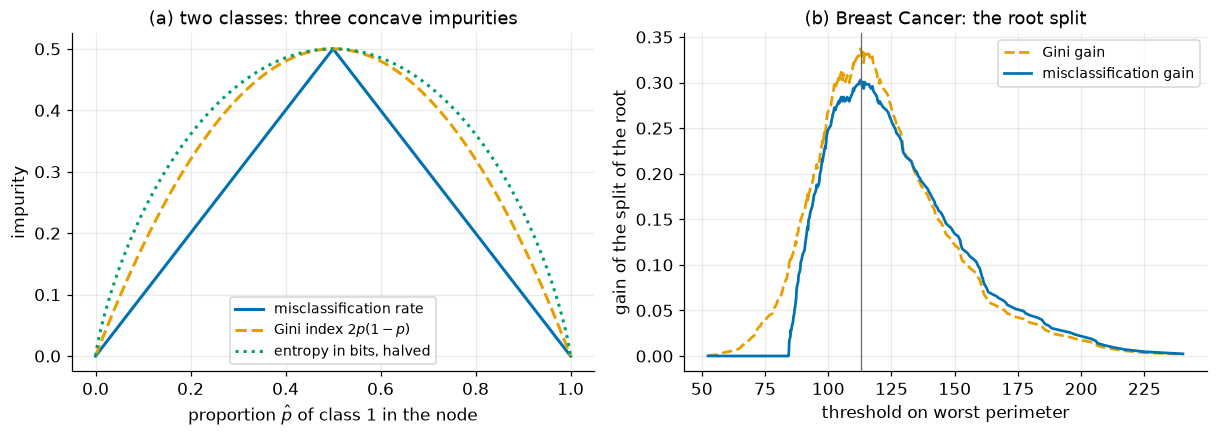

In [7]:
def figure_11_2():
    fig, axes = plt.subplots(1, 2, figsize=(11.2, 4.1))
    ax = axes[0]
    p = np.linspace(0, 1, 401)
    ax.plot(p, np.minimum(p, 1 - p), color=BLUE, lw=2, label="misclassification rate")
    ax.plot(p, 2 * p * (1 - p), color=ORANGE, lw=2, ls="--", label=r"Gini index $2p(1-p)$")
    with np.errstate(divide="ignore", invalid="ignore"):
        ent = -(p * np.log2(p) + (1 - p) * np.log2(1 - p)) / 2
    ax.plot(p, np.nan_to_num(ent), color=GREEN, lw=2, ls=":", label="entropy in bits, halved")
    ax.set_xlabel(r"proportion $\hat p$ of class 1 in the node")
    ax.set_ylabel("impurity")
    ax.set_title("(a) two classes: three concave impurities")
    ax.legend(fontsize=9)

    ax = axes[1]
    j = bc_names.index("worst perimeter")
    order = np.argsort(Xb_tr[:, j])
    xs, ys = Xb_tr[order, j], yb_tr[order]
    n = len(ys)
    cum1 = np.cumsum(ys)[:-1]
    nl = np.arange(1, n)
    nr = n - nl
    p1_l, p1_r = cum1 / nl, (ys.sum() - cum1) / nr
    p1 = ys.mean()
    g = lambda q: 2 * q * (1 - q)
    m = lambda q: np.minimum(q, 1 - q)
    gain_gini = g(p1) - (nl * g(p1_l) + nr * g(p1_r)) / n
    gain_mis = m(p1) - (nl * m(p1_l) + nr * m(p1_r)) / n
    mid = 0.5 * (xs[:-1] + xs[1:])
    ok = xs[:-1] < xs[1:]
    ax.plot(mid[ok], gain_gini[ok], color=ORANGE, lw=1.8, ls="--", label="Gini gain")
    ax.plot(mid[ok], gain_mis[ok], color=BLUE, lw=1.8, label="misclassification gain")
    ax.axvline(mid[ok][np.argmax(gain_gini[ok])], color="0.4", lw=0.8)
    ax.set_xlabel("threshold on worst perimeter")
    ax.set_ylabel("gain of the split of the root")
    ax.set_title("(b) Breast Cancer: the root split")
    ax.legend(fontsize=9)
    fig.tight_layout()
    return fig


figure_11_2()
plt.show()

Figure 11.2 summarizes the section. Panel (a) shows the three impurities for two classes: the Gini index and the entropy are smooth and strictly concave, the misclassification rate is a tent. Panel (b) shows the criteria as functions of the threshold for the root split of Breast Cancer. All have their maximum at $112.8$, but the misclassification gain is **exactly zero for the first $107$ of the $398$ candidate thresholds**, up to $84.4$: for all of them the left child is pure (benign) and the right child still has a benign majority, so that the predictions are those of the root and the error rate does not move, while the Gini gain has already reached $0.095$. A greedy algorithm driven by the error rate would see nothing to gain from isolating a pure node.

## 11.4 Controlling the size of a tree: cost-complexity pruning

### 11.4.1 Stopping early or growing and pruning

Section 11.2 showed that a tree grown to purity memorizes the training set. The simplest remedy is to stop growing early: a maximum depth, a minimum number of examples in a leaf (`min_samples_leaf`), or a minimum gain for a split. These rules are easy to state but short-sighted: a split with a small gain may open the way to a split with a large gain (the exclusive-or pattern is the standard example: no single split of $x_1$ or $x_2$ reduces the impurity, and the two together separate the classes perfectly). The method of Breiman, Friedman, Olshen and Stone (1984), called **CART**, therefore grows a deliberately *large* tree and then removes the splits that are not worth their cost.

### 11.4.2 The pruning criterion and the nested sequence of optimal subtrees

Let $T_0$ be the large tree. A **pruned subtree** $T\preceq T_0$ is obtained by collapsing some internal nodes into leaves (together with everything below them). Write $R(m)$ for the *cost* of the node $m$ when it is a leaf: its residual sum of squares divided by $n$ in regression, its weighted impurity in classification (the impurity of the node times the fraction of the training set that reaches it), and $R(T)=\sum_{m\in\text{leaves}(T)}R(m)$ for the training cost of the tree. A pruned subtree has a larger cost than $T_0$ (Propositions 11.2 and 11.4), and it has fewer leaves. The **cost-complexity criterion** puts a price $\alpha\ge0$ on every leaf:
$$
R_\alpha(T)=R(T)+\alpha\,\lvert T\rvert .
\tag{11.1}$$
For $\alpha=0$ the best subtree is the full tree, for large $\alpha$ it is the root alone. Among the exponentially many subtrees, how should we find the best one for each $\alpha$, and how do these best subtrees depend on $\alpha$? The answer is as clean as one could hope.

:::{admonition} Proposition 11.6 (the optimal subtrees are nested)
:class: tip
For every $\alpha\ge0$ the criterion (11.1) has a unique *smallest* minimizer $T(\alpha)\preceq T_0$ (smallest in the number of leaves). The tree $T(\alpha)$ can be computed by a single bottom-up pass, and
$$
\alpha<\alpha'\ \Longrightarrow\ T(\alpha')\preceq T(\alpha).
$$
Consequently there are at most $\lvert T_0\rvert-1$ distinct optimal subtrees, with break points $0=\alpha_0<\alpha_1<\dots$; the next subtree is obtained from the current one by collapsing the **weakest link**, the internal node $t$ that minimizes $g(t)=\dfrac{R(t)-R(T_t)}{\lvert T_t\rvert-1}$, where $T_t$ is the part of the current tree below $t$.
:::

*Proof.* For a node $t$ of $T_0$ with children $l,r$, let $C_\alpha(t)$ be the minimum of $R_\alpha$ over the pruned subtrees of the tree $T_t$ rooted at $t$. A pruned subtree of $T_t$ is either the single leaf $t$, with cost $R(t)+\alpha$, or the node $t$ with a pruned subtree on each side, so that $C_\alpha(t)=\min\{R(t)+\alpha,\ C_\alpha(l)+C_\alpha(r)\}$, and $C_\alpha(t)=R(t)+\alpha$ at a leaf. This recursion computes the optimum from the leaves up; collapsing at $t$ is optimal exactly when the function
$$
\Phi_t(\alpha)=C_\alpha(l)+C_\alpha(r)-R(t)-\alpha
$$
is $\ge0$. Each $C_\alpha(u)$ is a minimum of functions $R(T')+\alpha\lvert T'\rvert$, so $\Phi_t(\alpha)=\min_{T_l',T_r'}\big[R(T_l')+R(T_r')-R(t)\big]+\alpha\big(\lvert T_l'\rvert+\lvert T_r'\rvert-1\big)$ is a minimum of affine functions of $\alpha$ whose slopes are all $\ge1$: it is strictly increasing. At $\alpha=0$ the minimum is attained by the unpruned subtrees, and $\Phi_t(0)=R(T_l)+R(T_r)-R(t)\le0$ by the monotonicity of the cost. So $\Phi_t$ has exactly one zero $\alpha_t\ge0$, and collapsing $t$ is optimal (we collapse at ties, to get the smallest tree) if and only if $\alpha\ge\alpha_t$. Going down from the root, $T(\alpha)$ keeps the split at $t$ as long as $\alpha<\alpha_{t'}$ for every node $t'$ on the path from the root to $t$, and collapses at the first node where $\alpha\ge\alpha_{t'}$: an internal node of $T(\alpha)$ must satisfy $\alpha<\alpha_{t'}$ for all its ancestors and itself, which becomes harder as $\alpha$ grows, so the set of internal nodes can only shrink. Finally, at the break point of $t$ the cost of collapsing it equals the cost of the current optimal subtree below it, $R(t)+\alpha=R(T_t)+\alpha\lvert T_t\rvert$, and solving for $\alpha$ gives $g(t)$. $\blacksquare$

The proof used only the fact that splitting does not increase the cost, so it holds for any node cost that satisfies Propositions 11.2 or 11.4 (squared error, Gini, entropy, misclassification count); scikit-learn uses the node impurity of the criterion with which the tree was grown. The weakest-link formula is also the algorithm: compute $g(t)$ for every internal node, collapse the node with the smallest value (all the ties together), record it as the next break point, and repeat. The next cell implements it and compares the break points and the sizes of the subtrees with `cost_complexity_pruning_path` and `ccp_alpha` of scikit-learn, on the full Diabetes tree.

In [8]:
def weakest_link_path(fitted_tree):
    """Cost-complexity pruning from scratch (Proposition 11.6): break points alpha_k and numbers of leaves of T(alpha_k)."""
    T = fitted_tree.tree_
    left, right = T.children_left, T.children_right
    R = T.impurity * T.weighted_n_node_samples / T.weighted_n_node_samples[0]      # R(m): impurity of the node times its share of the data
    is_leaf = left == -1                                                            # collapsed nodes are turned into leaves below

    def subtree_stats():
        R_sub, n_sub = np.zeros(T.node_count), np.zeros(T.node_count)
        for t in range(T.node_count - 1, -1, -1):                                   # children have larger indices than parents
            if is_leaf[t]:
                R_sub[t], n_sub[t] = R[t], 1
            else:
                R_sub[t], n_sub[t] = R_sub[left[t]] + R_sub[right[t]], n_sub[left[t]] + n_sub[right[t]]
        return R_sub, n_sub

    def reachable_internal():
        stack, out = [0], []
        while stack:
            t = stack.pop()
            if not is_leaf[t]:
                out.append(t)
                stack += [left[t], right[t]]
        return out

    alphas, leaves = [0.0], [int(subtree_stats()[1][0])]
    while not is_leaf[0]:
        R_sub, n_sub = subtree_stats()
        internal = reachable_internal()
        g = {t: (R[t] - R_sub[t]) / (n_sub[t] - 1) for t in internal}
        g_min = min(g.values())
        for t in internal:
            if g[t] <= g_min * (1 + 1e-9) + 1e-300:
                is_leaf[t] = True                                                   # collapse the weakest link (and ties)
        alphas.append(max(g_min, alphas[-1]))
        leaves.append(int(subtree_stats()[1][0]))
    return np.array(alphas), np.array(leaves)


def distinct(a, rtol=1e-9):
    """Sorted values, merging those that differ only by rounding errors."""
    a = np.sort(np.asarray(a, float))
    keep = [a[0]]
    for v in a[1:]:
        if v - keep[-1] > rtol * max(1.0, abs(v)):
            keep.append(v)
    return np.array(keep)


full_d = DecisionTreeRegressor(random_state=SEED).fit(Xd_tr, yd_tr)
a_mine, leaves_mine = weakest_link_path(full_d)
a_sk = distinct(full_d.cost_complexity_pruning_path(Xd_tr, yd_tr).ccp_alphas)
a_mine_u = distinct(a_mine)
print(f"full tree: {full_d.get_n_leaves()} leaves.  Distinct break points: ours {len(a_mine_u)}, scikit-learn {len(a_sk)};"
      f"  largest difference {np.abs(a_mine_u - a_sk).max():.1e}")
leaves_sk = [DecisionTreeRegressor(ccp_alpha=a * (1 + 1e-9), random_state=SEED).fit(Xd_tr, yd_tr).get_n_leaves() for a in a_mine]   # a node is pruned when its g(t) <= alpha
print(f"number of leaves of the optimal subtree at each break point: identical to scikit-learn in "
      f"{int(np.sum(np.array(leaves_sk) == leaves_mine))} of {len(a_mine)} cases")
show = [0, 50, 100, 150, 200, len(a_mine) - 3, len(a_mine) - 1]
print(pd.DataFrame({"break point alpha": a_mine[show], "leaves of T(alpha)": leaves_mine[show]}).to_string(index=False, float_format=lambda v: f"{v:.4g}"))

full tree: 324 leaves.  Distinct break points: ours 225, scikit-learn 225;  largest difference 1.8e-12


number of leaves of the optimal subtree at each break point: identical to scikit-learn in 225 of 225 cases
 break point alpha  leaves of T(alpha)
                 0                 324
            0.3506                 203
             2.068                 144
             7.535                  94
             36.98                  31
             404.1                   3
              1756                   1


The break points computed from the weakest-link formula agree with those of scikit-learn (the largest difference is $1.8\times10^{-12}$, rounding error), and so do the sizes of the optimal subtrees, in all $225$ cases. The table shows how little most of the tree is worth. The unpruned tree has $324$ leaves; a price of $\alpha=0.34$ per leaf (the unit of $\alpha$ is that of $R$, here the mean squared error in squared units of the target) already removes $120$ of them, and $\alpha=36$ leaves $32$; the $3$-leaf tree is optimal up to $\alpha=404$ and the root alone for $\alpha\ge1756$. A single pass over the *nested* sequence gives all the candidates, so cross-validating $\alpha$ costs one tree fit per fold and per value, not a search over subtrees.

### 11.4.3 Choosing $\alpha$ by cross-validation

The parameter $\alpha$ is the one hyperparameter of the pruned tree, and it is chosen like all the others, by $K$-fold cross-validation (Chapter 5): for each value of $\alpha$ a tree is grown on the training part of each fold and pruned with that $\alpha$, and the error is measured on the validation part. We use the break points of the full tree as the grid (a different value between two break points gives the same subtree) and the one-standard-error rule of Section 5.4.1 and Section 10.7.1: take the *smallest* tree whose cross-validated error is within one standard error of the minimum. The grid for Diabetes has $224$ values and each is evaluated with $10$ folds, $2{,}240$ tree fits in all (the last break point, which leaves only the root, is left out, and we compare with the constant prediction instead).

In [9]:
def cv_over_alphas(make_tree, X, y, alphas, cv, scoring):
    """Cross-validated error for a grid of ccp_alpha values: mean and standard error over the folds."""
    rows = []
    for a in alphas:
        s = -cross_val_score(make_tree(a), X, y, cv=cv, scoring=scoring)
        rows.append((a, s.mean(), s.std(ddof=1) / np.sqrt(len(s))))
    return np.array(rows)


def one_se_choice(cv_table):
    """Index of the CV minimum and of the largest alpha (smallest tree) within one SE of it."""
    i_min = int(np.argmin(cv_table[:, 1]))
    ok = np.where(cv_table[:, 1] <= cv_table[i_min, 1] + cv_table[i_min, 2])[0]
    return i_min, int(ok.max())


kf10 = KFold(10, shuffle=True, random_state=SEED)
skf10 = StratifiedKFold(10, shuffle=True, random_state=SEED)

# Diabetes: regression tree, squared error
a_grid = a_sk[:-1]                                  # scikit-learn's own break points (no rounding mismatch), without the last one, which leaves the root alone
cv_d = cv_over_alphas(lambda a: DecisionTreeRegressor(ccp_alpha=a, random_state=SEED), Xd_tr, yd_tr, a_grid, kf10, "neg_mean_squared_error")
leaves_d = np.array([DecisionTreeRegressor(ccp_alpha=a, random_state=SEED).fit(Xd_tr, yd_tr).get_n_leaves() for a in a_grid])
train_rmse_d = np.array([rmse(DecisionTreeRegressor(ccp_alpha=a, random_state=SEED).fit(Xd_tr, yd_tr).predict(Xd_tr), yd_tr) for a in a_grid])
i_min_d, i_1se_d = one_se_choice(cv_d)
print(f"Diabetes: {len(a_grid)} values of alpha, {len(a_grid) * 10} tree fits")
print(f"  CV minimum:  alpha = {a_grid[i_min_d]:.1f}, {leaves_d[i_min_d]} leaves, CV RMSE {np.sqrt(cv_d[i_min_d, 1]):.2f}")
print(f"  one-SE rule: alpha = {a_grid[i_1se_d]:.1f}, {leaves_d[i_1se_d]} leaves, CV RMSE {np.sqrt(cv_d[i_1se_d, 1]):.2f}")
const_d = float(np.sqrt(-cross_val_score(DummyRegressor(), Xd_tr, yd_tr, cv=kf10, scoring="neg_mean_squared_error").mean()))
print(f"  full tree (alpha = 0): {leaves_d[0]} leaves, CV RMSE {np.sqrt(cv_d[0, 1]):.2f};  constant prediction (the mean): CV RMSE {const_d:.2f}")

# Breast Cancer: classification tree, Gini
full_b = DecisionTreeClassifier(random_state=SEED).fit(Xb_tr, yb_tr)
a_b = distinct(full_b.cost_complexity_pruning_path(Xb_tr, yb_tr).ccp_alphas)[:-1]       # without the break point that leaves the root alone
cv_b = cv_over_alphas(lambda a: DecisionTreeClassifier(ccp_alpha=a, random_state=SEED), Xb_tr, yb_tr, a_b, skf10, make_scorer(zero_one_loss, greater_is_better=False))
leaves_b = np.array([DecisionTreeClassifier(ccp_alpha=a, random_state=SEED).fit(Xb_tr, yb_tr).get_n_leaves() for a in a_b])
train_err_b = np.array([1 - DecisionTreeClassifier(ccp_alpha=a, random_state=SEED).fit(Xb_tr, yb_tr).score(Xb_tr, yb_tr) for a in a_b])
i_min_b, i_1se_b = one_se_choice(cv_b)
print(f"\nBreast Cancer: {len(a_b)} values of alpha")
print(pd.DataFrame({"alpha": a_b, "leaves": leaves_b, "training error": train_err_b, "CV error": cv_b[:, 1], "SE": cv_b[:, 2]}).to_string(index=False, float_format=lambda v: f"{v:.4f}"))
print(f"  CV minimum:  alpha = {a_b[i_min_b]:.4f}, {leaves_b[i_min_b]} leaves, CV error {cv_b[i_min_b, 1]:.4f}")
print(f"  one-SE rule: alpha = {a_b[i_1se_b]:.4f}, {leaves_b[i_1se_b]} leaves, CV error {cv_b[i_1se_b, 1]:.4f}")
const_b = float(1 - cross_val_score(DummyClassifier(strategy="most_frequent"), Xb_tr, yb_tr, cv=skf10).mean())
print(f"  constant prediction (benign): CV error {const_b:.4f}")

Diabetes: 224 values of alpha, 2240 tree fits
  CV minimum:  alpha = 188.1, 4 leaves, CV RMSE 65.31
  one-SE rule: alpha = 488.1, 2 leaves, CV RMSE 67.04
  full tree (alpha = 0): 324 leaves, CV RMSE 80.58;  constant prediction (the mean): CV RMSE 78.16



Breast Cancer: 13 values of alpha
 alpha  leaves  training error  CV error     SE
0.0000      21          0.0000    0.0705 0.0165
0.0023      15          0.0070    0.0705 0.0165
0.0023      13          0.0094    0.0705 0.0165
0.0044      12          0.0117    0.0751 0.0178
0.0046      11          0.0141    0.0727 0.0166
0.0056      10          0.0188    0.0633 0.0144
0.0063       9          0.0235    0.0633 0.0144
0.0067       8          0.0282    0.0633 0.0121
0.0078       7          0.0305    0.0680 0.0149
0.0091       5          0.0399    0.0728 0.0137
0.0111       4          0.0446    0.0728 0.0141
0.0144       3          0.0516    0.0752 0.0147
0.0333       2          0.0704    0.0941 0.0154
  CV minimum:  alpha = 0.0056, 10 leaves, CV error 0.0633
  one-SE rule: alpha = 0.0144, 3 leaves, CV error 0.0752
  constant prediction (benign): CV error 0.3733


**Diabetes.** The tree with no pruning has a cross-validated RMSE of $80.58$, *worse than the constant prediction* ($78.16$), a fact that Section 11.2.4 had shown on the test set. The minimum of the curve is at $4$ leaves, with an RMSE of $65.31$, and the one-standard-error rule chooses a tree with only $2$ leaves ($67.04$), a single split of the body mass index. Even the best tree is far from the linear models: the leave-one-out RMSE of ridge regression and of kernel ridge regression on the same $331$ patients was about $55.5$ (Section 9.5.2). **Breast Cancer.** The CV error of the full tree ($21$ leaves) is $0.0705$ and the minimum is $0.0633$ at $10$ leaves (a plateau from $8$ to $10$ leaves); the improvement of $0.007$ is smaller than one standard error ($0.0144$), so cross-validation cannot really tell the pruned tree from the full one, while the constant prediction has an error of $0.373$, the prevalence of malignant tumors. The one-standard-error rule chooses the tree with $3$ leaves ($0.0752$).

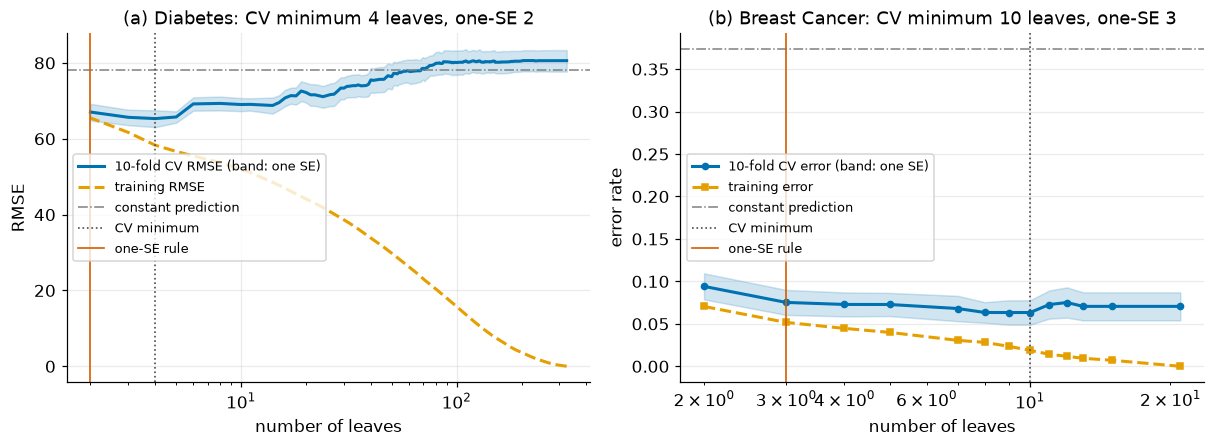

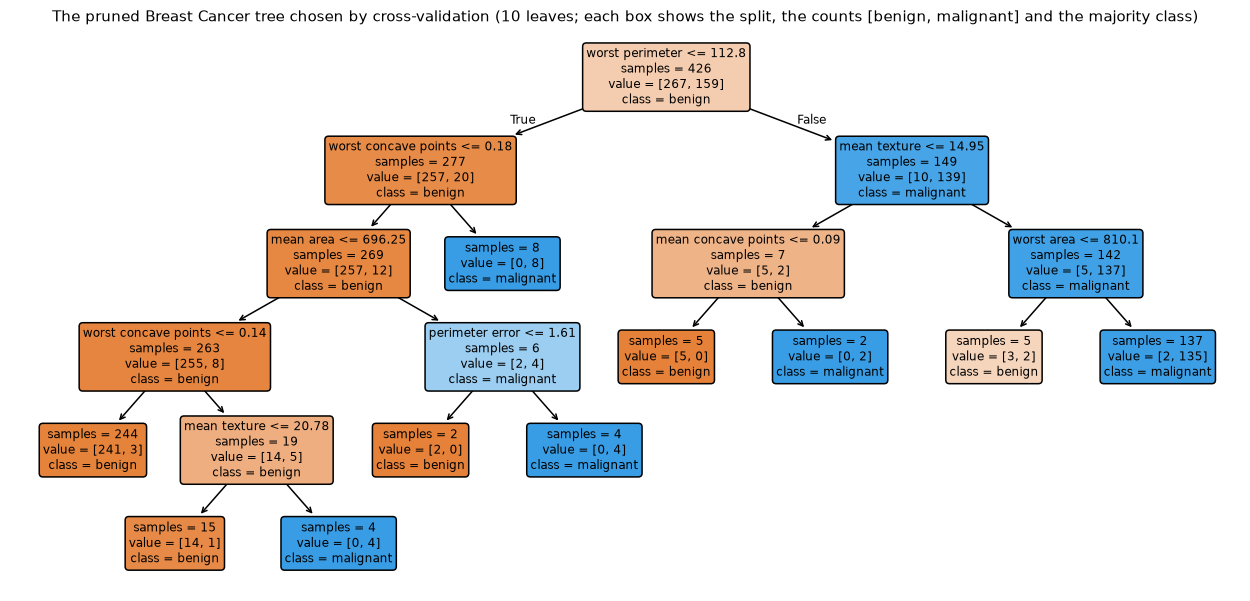

In [10]:
def figure_11_3():
    fig, axes = plt.subplots(1, 2, figsize=(11.2, 4.2))
    ax = axes[0]
    rm = np.sqrt(cv_d[:, 1])
    ax.fill_between(leaves_d, np.sqrt(np.maximum(cv_d[:, 1] - cv_d[:, 2], 0)), np.sqrt(cv_d[:, 1] + cv_d[:, 2]), color=BLUE, alpha=0.18)
    ax.plot(leaves_d, rm, color=BLUE, lw=2, label="10-fold CV RMSE (band: one SE)")
    ax.plot(leaves_d, train_rmse_d, color=ORANGE, lw=2, ls="--", label="training RMSE")
    ax.axhline(const_d, color="0.5", lw=1.0, ls="-.", label="constant prediction")
    ax.axvline(leaves_d[i_min_d], color="0.3", lw=1.1, ls=":", label="CV minimum")
    ax.axvline(leaves_d[i_1se_d], color=VERMILION, lw=1.1, label="one-SE rule")
    ax.set_xscale("log")
    ax.set_xlabel("number of leaves")
    ax.set_ylabel("RMSE")
    ax.set_title(f"(a) Diabetes: CV minimum {leaves_d[i_min_d]} leaves, one-SE {leaves_d[i_1se_d]}")
    ax.legend(fontsize=8.5, loc="center left")

    ax = axes[1]
    order = np.argsort(leaves_b)
    lb, eb, sb = leaves_b[order], cv_b[order, 1], cv_b[order, 2]
    ax.fill_between(lb, np.maximum(eb - sb, 0), eb + sb, color=BLUE, alpha=0.18)
    ax.plot(lb, eb, color=BLUE, lw=2, marker="o", ms=4, label="10-fold CV error (band: one SE)")
    ax.plot(lb, train_err_b[order], color=ORANGE, lw=2, ls="--", marker="s", ms=4, label="training error")
    ax.axhline(const_b, color="0.5", lw=1.0, ls="-.", label="constant prediction")
    ax.axvline(leaves_b[i_min_b], color="0.3", lw=1.1, ls=":", label="CV minimum")
    ax.axvline(leaves_b[i_1se_b], color=VERMILION, lw=1.1, label="one-SE rule")
    ax.set_xscale("log")
    ax.set_xlabel("number of leaves")
    ax.set_ylabel("error rate")
    ax.set_title(f"(b) Breast Cancer: CV minimum {leaves_b[i_min_b]} leaves, one-SE {leaves_b[i_1se_b]}")
    ax.legend(fontsize=8.5, loc="center left")
    fig.tight_layout()
    return fig


figure_11_3()
plt.show()


def figure_11_4():
    t = DecisionTreeClassifier(ccp_alpha=a_b[i_min_b], random_state=SEED).fit(Xb_tr, yb_tr)
    fig, ax = plt.subplots(figsize=(11.5, 5.6))
    plot_tree(t, feature_names=bc_names, class_names=["benign", "malignant"], filled=True, impurity=False, proportion=False,
              rounded=True, fontsize=8, ax=ax, precision=2)
    ax.set_title(f"The pruned Breast Cancer tree chosen by cross-validation ({t.get_n_leaves()} leaves; each box shows the split, the counts [benign, malignant] and the majority class)", fontsize=9.5)
    fig.tight_layout()
    return fig


figure_11_4()
plt.show()

Figure 11.3 draws the two curves against the number of leaves, with the training error that decreases monotonically all the way down to zero while the cross-validated error has a shallow minimum. Figure 11.4 shows the pruned tree for Breast Cancer, which can be read as a short list of rules: tumors with a worst perimeter of at most $112.8$ are benign unless the worst concave points exceed $0.18$ (all $8$ such tumors are malignant); among the $149$ tumors with a larger perimeter, $139$ are malignant, and so on. The tree has $9$ splits and uses $7$ of the $30$ features, each one a threshold on a single measurement, and **readability is the main reason trees are used at all**: a clinician can follow it without a computer. Its weak point is also visible: several leaves hold a handful of patients ($2$, $4$, $5$), and the label of a leaf with $5$ patients is a statistic of $5$ numbers.

## 11.5 What a tree assumes: the inductive bias

Chapter 3 introduced the **inductive bias** of a learning method: the assumptions that make it work on some problems and fail on others, and the table at the end of Chapter 3 listed for trees "the label depends on a few features through simple threshold rules". This section turns that sentence into five measurable statements.

### 11.5.1 Invariance to monotone transformations of the features

Every split of a tree compares one feature with a threshold, and the gain of Section 11.2 depends only on *which* training points go to the left. The set of such partitions for the feature $x_j$ depends only on the *order* of its values.

:::{admonition} Proposition 11.7 (invariance)
:class: tip
Let $g_1,\dots,g_p$ be strictly increasing functions and let the tree be grown on the transformed features $g_j(x_{ij})$ instead of $x_{ij}$. Then the greedy algorithm finds the same sequence of partitions of the training points (the same gains, the same leaves, the same predictions on the training points), up to the tie-breaking of Section 11.2.2. On new points the two trees can differ only for points that fall *between two consecutive training values* of the feature of a split, because the threshold is the midpoint of the two values in the coordinates in which the tree is grown, and $g_j$ does not map midpoints to midpoints.
:::

*Proof.* A strictly increasing $g_j$ preserves the order and the ties of the values of feature $j$, so the family of sets $\{i: g_j(x_{ij})\le s\}$, $s\in\mathbb{R}$, is the same family of subsets of the training points as $\{i:x_{ij}\le s\}$. The gain of a split depends only on the subset, so the best split at each node is the same, and so is the recursion. For a new point $\mathbf{x}$, the decisions of the two trees at a node can differ only if $x_j$ lies between the two consecutive training values that define the threshold, since for $x_j$ outside that interval the comparison with the threshold is decided by the order. $\blacksquare$

This is the fulfilment of a promise made in Section 2.7.1 and again in Section 9.6.4 and Exercise 9.8: **a tree needs no standardization and no transformation of the features**, and a skewed feature (an area, a concentration) can be given to it as it is. The next cell checks the statement on Breast Cancer, where the features have scales that differ by a factor of $10^4$, and contrasts it with a nearest-neighbor rule and a logistic regression, which depend on the scale.

In [11]:
sc_b = StandardScaler().fit(Xb_tr)
variants = {"raw": (Xb_tr, Xb_te),
            "standardized": (sc_b.transform(Xb_tr), sc_b.transform(Xb_te)),
            "logarithm of 1 + x": (np.log1p(Xb_tr), np.log1p(Xb_te))}

# (i) the tree grown with the same gains: the splitting features, the impurities and the predictions
trees = {k: DecisionTreeClassifier(random_state=SEED).fit(a, yb_tr) for k, (a, _) in variants.items()}
ref = trees["raw"]
for k, t in trees.items():
    same_struct = np.array_equal(t.tree_.feature, ref.tree_.feature) and np.allclose(t.tree_.impurity, ref.tree_.impurity)
    diff_test = int((t.predict(variants[k][1]) != ref.predict(Xb_te)).sum())
    print(f"{k:20s} same splitting features and impurities as the raw tree: {same_struct};  test predictions that differ: {diff_test} of {len(yb_te)}")

# (ii) 10-fold cross-validated accuracy on the training set of three methods under the three transformations
rows = []
for name, make in [("decision tree", lambda: DecisionTreeClassifier(random_state=SEED)),
                   ("5-NN (no scaler)", lambda: KNeighborsClassifier(5)),
                   ("logistic regression, C=1 (no scaler)", lambda: LogisticRegression(C=1, max_iter=5000))]:
    row = {"method": name}
    for k, (a, _) in variants.items():
        row[k] = cross_val_score(make(), a, yb_tr, cv=skf10).mean()
    rows.append(row)
print()
print(pd.DataFrame(rows).to_string(index=False, float_format=lambda v: f"{v:.4f}"))

raw                  same splitting features and impurities as the raw tree: True;  test predictions that differ: 0 of 143
standardized         same splitting features and impurities as the raw tree: True;  test predictions that differ: 0 of 143
logarithm of 1 + x   same splitting features and impurities as the raw tree: True;  test predictions that differ: 0 of 143



                              method    raw  standardized  logarithm of 1 + x
                       decision tree 0.9295        0.9295              0.9271
                    5-NN (no scaler) 0.9341        0.9553              0.9485
logistic regression, C=1 (no scaler) 0.9483        0.9789              0.9460


The three trees have the same splitting features and the same impurities, and none of the $143$ test predictions differs, as Proposition 11.7 says: a feature in the units of the data, standardized, or compressed by a logarithm gives the same tree. The cross-validated accuracy of the tree is the same for the raw and the standardized features ($0.9295$) and differs slightly for the logarithm ($0.9271$): the proposition allows a difference for validation points that fall between two consecutive training values, and here a few of them do. The two other methods, in contrast, depend on the transformation: for $5$-NN the cross-validated accuracy goes from $0.934$ (raw) to $0.955$ (standardized), and for the logistic regression, whose penalty acts unevenly on features of different scales, from $0.948$ to $0.979$. Invariance is a convenience, not a measure of quality: on this data the tree is less accurate than both of them ($0.93$ against $0.955$ and $0.979$ with standardized features).

### 11.5.2 Adaptive neighborhoods: a tree is a $k$-NN rule whose $k$ depends on the point

Section 11.2.1 observed that a tree predicts by averaging the targets of the training points in the same box, as $k$-NN does, but with neighborhoods learned from the targets. The consequence is easy to see on two *constructed* regression problems with one feature, $x\sim\mathrm{U}[0,1]$, $n=100$ and noise $\sigma=0.3$ as in Chapter 4: a step, $f(x)=\mathbb{I}[x>0.5]$, and a smooth function, $f(x)=\sin(2\pi x)$. For each draw of the data we choose $k$ for $k$-NN and $\alpha$ for the tree by $5$-fold cross-validation, and we measure the mean squared error against the true function $f$ on a grid. Near the jump a good neighborhood is *narrow* and on each side of it *wide*; a smooth function wants neighborhoods of similar size everywhere.

In [12]:
def one_world(f, rep, n=100, sigma=0.3):
    rng = np.random.default_rng(1000 + rep)
    x = rng.uniform(0, 1, n)
    y = f(x) + sigma * rng.standard_normal(n)
    grid = np.linspace(0.005, 0.995, 200)
    kf = KFold(5, shuffle=True, random_state=rep)
    ks = [1, 2, 3, 5, 7, 10, 15, 20, 30, 40]
    cv_k = [-cross_val_score(KNeighborsRegressor(k), x[:, None], y, cv=kf, scoring="neg_mean_squared_error").mean() for k in ks]
    k_best = ks[int(np.argmin(cv_k))]
    knn = KNeighborsRegressor(k_best).fit(x[:, None], y)
    path = distinct(DecisionTreeRegressor(random_state=0).fit(x[:, None], y).cost_complexity_pruning_path(x[:, None], y).ccp_alphas)
    alphas = np.concatenate([[0.0], np.geomspace(1e-4 * path.max(), path.max(), 20)])
    cv_a = [-cross_val_score(DecisionTreeRegressor(ccp_alpha=a, random_state=0), x[:, None], y, cv=kf, scoring="neg_mean_squared_error").mean() for a in alphas]
    tree = DecisionTreeRegressor(ccp_alpha=alphas[int(np.argmin(cv_a))], random_state=0).fit(x[:, None], y)
    return {"x": x, "y": y, "grid": grid, "knn": knn.predict(grid[:, None]), "tree": tree.predict(grid[:, None]),
            "mse_knn": float(np.mean((knn.predict(grid[:, None]) - f(grid)) ** 2)),
            "mse_tree": float(np.mean((tree.predict(grid[:, None]) - f(grid)) ** 2)), "k": k_best, "leaves": tree.get_n_leaves()}


worlds = {"step": lambda x: (x > 0.5) * 1.0, "sine": lambda x: np.sin(2 * np.pi * x)}
sim, rows = {}, []
for name, f in worlds.items():
    runs = [one_world(f, r) for r in range(40)]
    sim[name] = runs
    d = np.array([r["mse_tree"] - r["mse_knn"] for r in runs])
    rows.append({"true function": name, "k-NN MSE": np.mean([r["mse_knn"] for r in runs]), "tree MSE": np.mean([r["mse_tree"] for r in runs]),
                 "tree - kNN (mean)": d.mean(), "SE": d.std(ddof=1) / np.sqrt(len(d)),
                 "mean k": np.mean([r["k"] for r in runs]), "mean leaves": np.mean([r["leaves"] for r in runs])})
print("40 constructed data sets of n = 100 per world; k-NN and the tree are tuned by 5-fold CV on each")
print(pd.DataFrame(rows).to_string(index=False, float_format=lambda v: f"{v:.4f}"))

40 constructed data sets of n = 100 per world; k-NN and the tree are tuned by 5-fold CV on each
true function  k-NN MSE  tree MSE  tree - kNN (mean)     SE  mean k  mean leaves
         step    0.0226    0.0101            -0.0126 0.0023 10.3000       2.2000
         sine    0.0175    0.0408             0.0233 0.0014  7.6500       7.8000


On the step the tree is far better: its mean squared error is $0.0101$ against $0.0226$ for $k$-NN, and the difference of $-0.0126$ is more than five standard errors ($0.0023$). Cross-validation chooses on average $2.2$ leaves for the tree (the true function has two pieces) and $k\approx10$ for $k$-NN, a compromise that smooths the jump (Figure 11.5(a), where the $k$-NN curve rounds the corner and wobbles on the flat parts while the tree has one split). On the smooth function the order is reversed: the tree has an error of $0.0408$ against $0.0175$, a difference of $+0.0233$ (more than ten standard errors), because a staircase with about $8$ steps approximates a sine less well than a local average of $7$ neighbors (Figure 11.5(b)). This is the inductive bias of Chapter 3 in its simplest form: *piecewise constant* is the right assumption for the first function and the wrong one for the second, and no method is better for both. (Smoothing the staircase is one of the things that averaging many trees does, Section 11.6.)

### 11.5.3 Irrelevant features

Section 4.7.2 appended columns of Gaussian noise to the Breast Cancer features and measured how the accuracy of $k$-NN collapses, and Chapter 10 how the lasso copes. A tree handles irrelevant features in a different way: a feature is used only if it gives the best split at some node, and a noise column has a good chance of doing so only where few examples remain. The next cell repeats the experiment of Section 4.7.2 (15 random stratified splits of the whole data set, $m=0$, $100$ and $1000$ added noise columns) for a single tree, $5$-NN and logistic regression, both standardized.

In [13]:
def noise_experiment(models, ms=(0, 100, 1000), reps=15):
    """Mean test accuracy over random stratified 75/25 splits of the whole Breast Cancer data, with m appended noise columns."""
    out = {name: {m: [] for m in ms} for name in models}
    for r in range(reps):
        rng = np.random.default_rng(r)
        noise = rng.standard_normal((bc.data.shape[0], max(ms)))
        for m in ms:
            X = np.hstack([bc.data, noise[:, :m]])
            a, b, c, d = train_test_split(X, bc_y_all, test_size=0.25, random_state=r, stratify=bc_y_all)
            for name, make in models.items():
                out[name][m].append(make().fit(a, c).score(b, d))
    return out


models_noise = {"tree": lambda: DecisionTreeClassifier(random_state=SEED),
                "5-NN": lambda: make_pipeline(StandardScaler(), KNeighborsClassifier(5)),
                "logistic": lambda: make_pipeline(StandardScaler(), LogisticRegression(C=1, max_iter=3000))}
t0 = time.perf_counter()
noise_res = noise_experiment(models_noise)
print(pd.DataFrame({name: {f"m = {m}": np.mean(v) for m, v in res.items()} for name, res in noise_res.items()}).to_string(float_format=lambda v: f"{v:.3f}"))
print(f"(15 splits; standard error of each mean about {np.mean([np.std(v, ddof=1) / np.sqrt(15) for res in noise_res.values() for v in res.values()]):.3f})")
print(f"[{time.perf_counter() - t0:.1f} s]")

          tree  5-NN  logistic
m = 0    0.925 0.961     0.974
m = 100  0.912 0.902     0.945
m = 1000 0.906 0.819     0.915
(15 splits; standard error of each mean about 0.005)
[2.1 s]


Without noise columns the tree is the weakest of the three ($0.925$, against $0.961$ for $5$-NN and $0.974$ for the logistic regression). With $1000$ noise columns the tree has lost $0.019$ of accuracy, the logistic regression $0.059$ and $5$-NN $0.142$, and the order of $5$-NN and the tree is reversed: $0.906$ against $0.819$ (the standard error of each mean is about $0.005$). This is the observation of Section 4.7.2 turned into a method: a tree chooses where to look, so a thousand irrelevant columns are a thousand extra candidates for each split but do not enter the distances. The comparison is also a caution: **the tree is not the best of the three at any $m$**. On Breast Cancer the classes are almost linearly separable in a few correlated features, which is exactly the case for which linear models are built (and Chapter 10 showed that a sparse linear model deals with the noise columns as well).

### 11.5.4 Axis-aligned boundaries

The price of the threshold rules is that every boundary of a tree is made of pieces parallel to the axes. A boundary that is not parallel to an axis must be approximated by a staircase with as many steps as the accuracy requires, while a linear model represents it with one weight vector. The effect is easy to isolate on a *constructed* problem with a diagonal boundary: $\mathbf{x}\sim\mathrm{U}[-1,1]^2$, $y=\mathbb{I}[x_1+x_2>0]$, with $5\%$ of the labels flipped, $n=200$ training and $20{,}000$ test points; and the same problem rotated by $45^\circ$, in which the boundary is $x_1'=0$. On real data the effect depends on how the signal lies relative to the axes: the last lines of the cell rotate the plane of the two best Breast Cancer features and measure the cross-validated accuracy on the training set.

In [14]:
def oblique_data(n, rng, rotate=False):
    X = rng.uniform(-1, 1, (n, 2))
    y = (X[:, 0] + X[:, 1] > 0).astype(int)
    flip = rng.random(n) < 0.05
    y = np.where(flip, 1 - y, y)
    if rotate:                                   # rotate the plane by 45 degrees: the boundary becomes x_1' = 0
        c = np.cos(np.pi / 4)
        X = X @ np.array([[c, -c], [c, c]])
    return X, y


rng = np.random.default_rng(SEED)
res_obl = {}
for rotate in [False, True]:
    Xo, yo = oblique_data(200, rng, rotate)
    Xo_te, yo_te = oblique_data(20000, rng, rotate)
    accs = {f"tree, depth {d}": DecisionTreeClassifier(max_depth=d, random_state=SEED).fit(Xo, yo).score(Xo_te, yo_te) for d in [1, 2, 4, 8]}
    accs["tree, pruned by CV"] = GridSearchCV(DecisionTreeClassifier(random_state=SEED), {"ccp_alpha": np.linspace(0, 0.03, 16)}, cv=5).fit(Xo, yo).score(Xo_te, yo_te)
    accs["logistic regression"] = LogisticRegression().fit(Xo, yo).score(Xo_te, yo_te)
    res_obl[rotate] = accs
print("test accuracy on 20,000 constructed points (the Bayes rate is 0.95 for both)")
print(pd.DataFrame({"diagonal boundary": res_obl[False], "boundary parallel to an axis": res_obl[True]}).to_string(float_format=lambda v: f"{v:.3f}"))

# the same experiment on two real features
two = [bc_names.index("worst perimeter"), bc_names.index("worst concave points")]
Z2 = StandardScaler().fit_transform(Xb_tr[:, two])
rcv = StratifiedKFold(5, shuffle=True, random_state=SEED)
rows = []
for theta in [0, 15, 30, 45, 60, 75, 90]:
    c, s = np.cos(np.radians(theta)), np.sin(np.radians(theta))
    Zr = Z2 @ np.array([[c, -s], [s, c]])
    rows.append({"rotation (degrees)": theta,
                 "tree, 8 leaves": cross_val_score(DecisionTreeClassifier(max_leaf_nodes=8, random_state=SEED), Zr, yb_tr, cv=rcv).mean(),
                 "logistic": cross_val_score(LogisticRegression(), Zr, yb_tr, cv=rcv).mean()})
print("\nBreast Cancer, the plane of worst perimeter and worst concave points rotated; 5-fold CV accuracy on the training set")
print(pd.DataFrame(rows).to_string(index=False, float_format=lambda v: f"{v:.3f}"))

test accuracy on 20,000 constructed points (the Bayes rate is 0.95 for both)
                     diagonal boundary  boundary parallel to an axis
tree, depth 1                    0.706                         0.948
tree, depth 2                    0.804                         0.948
tree, depth 4                    0.885                         0.941
tree, depth 8                    0.828                         0.939
tree, pruned by CV               0.881                         0.948
logistic regression              0.933                         0.946

Breast Cancer, the plane of worst perimeter and worst concave points rotated; 5-fold CV accuracy on the training set
 rotation (degrees)  tree, 8 leaves  logistic
                  0           0.930     0.937
                 15           0.948     0.937
                 30           0.946     0.937
                 45           0.925     0.937
                 60           0.929     0.937
                 75           0.930     0.937


On the diagonal boundary the tree needs depth to approximate the line and still does not reach it: its accuracy is $0.706$ for a single split, $0.804$ with two, $0.885$ with four, and *falls* to $0.828$ with eight levels, where the staircase starts to follow the flipped labels; the tree pruned by cross-validation reaches $0.881$. The logistic regression, which represents the boundary exactly, reaches $0.933$ (the Bayes rate of $0.95$ is the ceiling). When the same problem is rotated by $45^\circ$ the boundary is $x_1'=0$, a single split suffices ($0.948$ at depth $1$), and the tree and the logistic regression ($0.946$) are equal. The bias is therefore a statement about the *coordinates*: a tree is good when the signal is aligned with the features. On the real data the effect is not visible: for the plane of two Breast Cancer features the tree is between $0.925$ and $0.948$ at all angles, with no pattern, while the logistic regression, which is invariant to rotations, has $0.937$ throughout; differences of $0.02$ are of the order of the binomial standard error of an accuracy near $0.93$ on $426$ patients ($0.012$). The staircase of Figure 11.6(b) is the price, and it is paid only when the true boundary is oblique, which is common in problems where the features are sums or ratios of the quantities that matter (one can add such combinations, or rotate the features by a PCA, as Chapter 13 will teach).

### 11.5.5 Instability

The last property is the one that motivates the rest of the chapter. The root split of the Breast Cancer tree was the worst perimeter at $112.8$, with two runners-up almost as good (Section 11.3.2), and the split of Diabetes at depth $4$ was a coin toss between equal gains (Section 11.2.2). If the best split is a near-tie, a small change of the data changes it, and everything below it. The cell draws $200$ bootstrap samples of the training set ($n$ examples drawn with replacement, as in the bootstrap of Section 6.2.4), grows a depth-one tree on each, and counts the feature of the root split; and it measures how often two full trees grown on different bootstrap samples classify a test patient differently.

In [15]:
rng = np.random.default_rng(SEED)
n_tr = len(yb_tr)
root_counts, boot_trees = {}, []
for b in range(200):
    idx = rng.integers(0, n_tr, n_tr)
    stump = DecisionTreeClassifier(max_depth=1, random_state=SEED).fit(Xb_tr[idx], yb_tr[idx])
    name = bc_names[stump.tree_.feature[0]]
    root_counts[name] = root_counts.get(name, 0) + 1
    if b < 40:
        boot_trees.append(DecisionTreeClassifier(random_state=SEED).fit(Xb_tr[idx], yb_tr[idx]))
root_tab = pd.Series(root_counts).sort_values(ascending=False)
print("feature of the root split over 200 bootstrap samples of the training set:")
print(root_tab.to_string())

preds = np.array([t.predict(Xb_te) for t in boot_trees])                  # 40 full trees on the 143 test patients
pairs = [(i, j) for i in range(40) for j in range(i + 1, 40)]
disagree = np.mean([np.mean(preds[i] != preds[j]) for i, j in pairs])
unstable = np.mean(preds.min(axis=0) != preds.max(axis=0))
print(f"\nTwo full trees grown on different bootstrap samples disagree on {disagree:.1%} of the test patients on average;")
print(f"among the 40 trees, {unstable:.1%} of the test patients receive different predictions from different trees")
acc_trees = np.array([np.mean(p == yb_te) for p in preds])
print(f"test accuracy of the 40 trees: mean {acc_trees.mean():.3f}, standard deviation {acc_trees.std(ddof=1):.3f}, range {acc_trees.min():.3f} to {acc_trees.max():.3f}")

feature of the root split over 200 bootstrap samples of the training set:
worst perimeter         115
worst radius             28
mean concave points      24
worst concave points     18
worst area               14
mean concavity            1

Two full trees grown on different bootstrap samples disagree on 9.7% of the test patients on average;
among the 40 trees, 39.2% of the test patients receive different predictions from different trees
test accuracy of the 40 trees: mean 0.919, standard deviation 0.021, range 0.874 to 0.965


The root split is the worst perimeter in $115$ of the $200$ samples ($57.5\%$), but $85$ samples choose another feature, five different ones in all (Figure 11.7(a)): the near-ties of Section 11.3.2 are real. Two full trees grown on different bootstrap samples disagree on $9.7\%$ of the test patients on average, and among $40$ such trees $39.2\%$ of the test patients receive different predictions from different trees. The test accuracy of the $40$ trees averages $0.919$, with a standard deviation of $0.021$ and a range from $0.874$ to $0.965$: **the same algorithm on slightly different data gives models whose accuracies differ by about nine points**, which is the high variance of a $1$-NN-like model. On the one-feature Diabetes problem (Figure 11.7(b)) the $25$ bootstrap trees of depth $4$ are all staircases, each with its own steps, and their *average*, the thick curve, is a much smoother function that follows the trend of the data. Averaging a high-variance, low-bias predictor reduces the variance and keeps the bias; the next section makes this precise.

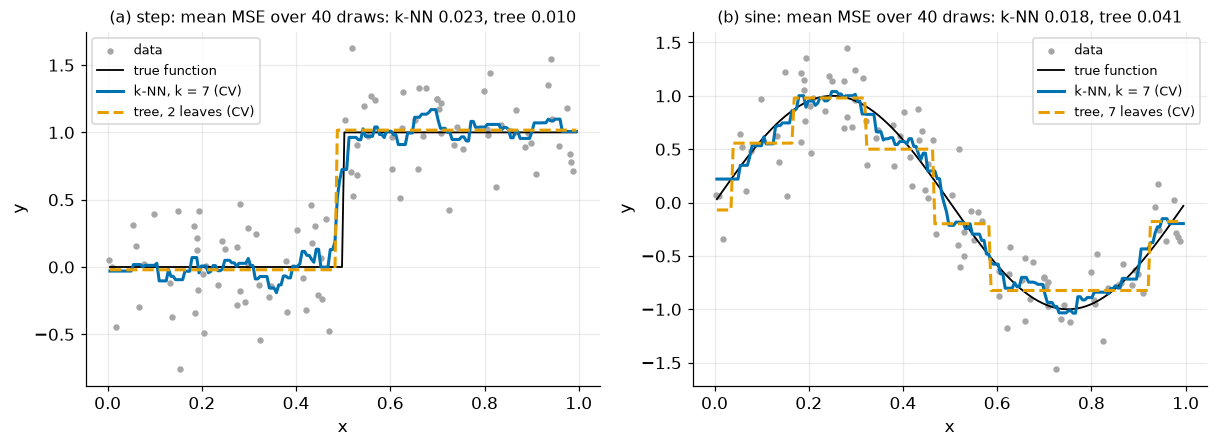

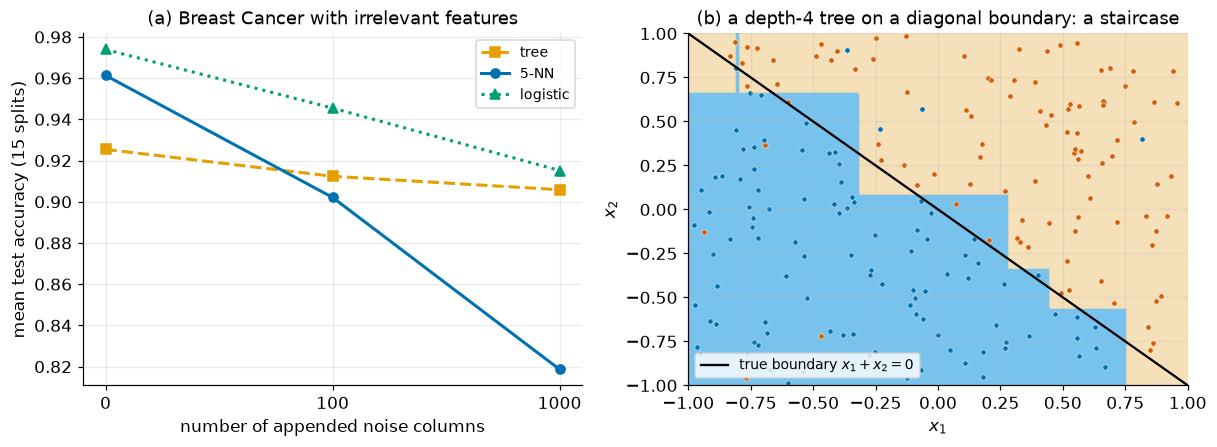

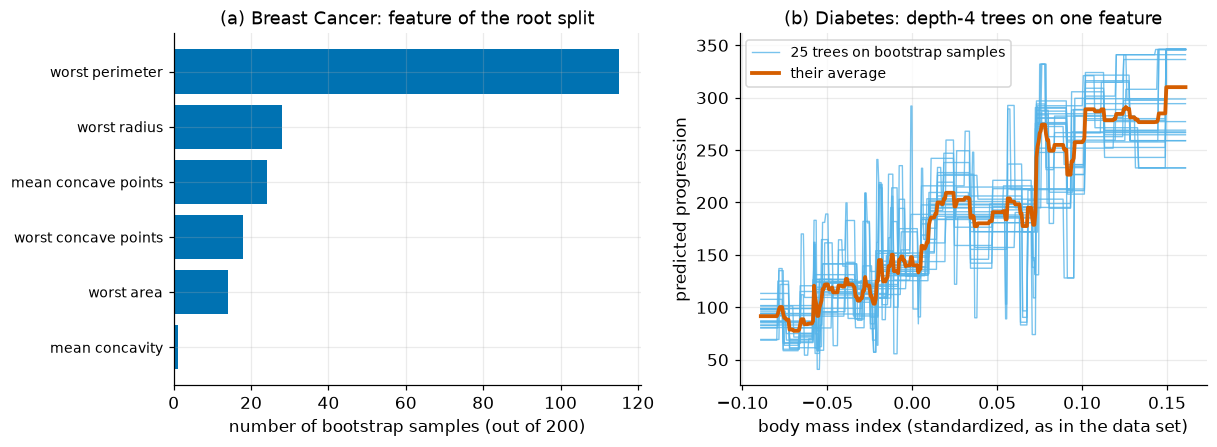

In [16]:
def figure_11_5():
    fig, axes = plt.subplots(1, 2, figsize=(11.2, 4.2))
    for ax, (name, f) in zip(axes, worlds.items()):
        run = sim[name][0]
        ax.scatter(run["x"], run["y"], s=10, color="0.65", label="data")
        ax.plot(run["grid"], f(run["grid"]), color="k", lw=1.2, label="true function")
        ax.plot(run["grid"], run["knn"], color=BLUE, lw=2, label=f"k-NN, k = {run['k']} (CV)")
        ax.plot(run["grid"], run["tree"], color=ORANGE, lw=2, ls="--", label=f"tree, {run['leaves']} leaves (CV)")
        ms = (np.mean([r["mse_knn"] for r in sim[name]]), np.mean([r["mse_tree"] for r in sim[name]]))
        ax.set_title(f"({'a' if name == 'step' else 'b'}) {name}: mean MSE over 40 draws: k-NN {ms[0]:.3f}, tree {ms[1]:.3f}", fontsize=10.5)
        ax.set_xlabel("x")
        ax.set_ylabel("y")
        ax.legend(fontsize=8.5)
    fig.tight_layout()
    return fig


figure_11_5()
plt.show()


def figure_11_6():
    fig, axes = plt.subplots(1, 2, figsize=(11.2, 4.2))
    ax = axes[0]
    ms = [0, 100, 1000]
    for name, color, marker, ls in [("tree", ORANGE, "s", "--"), ("5-NN", BLUE, "o", "-"), ("logistic", GREEN, "^", ":")]:
        ax.plot(range(3), [np.mean(noise_res[name][m]) for m in ms], color=color, marker=marker, ls=ls, lw=2, label=name)
    ax.set_xticks(range(3))
    ax.set_xticklabels([f"{m}" for m in ms])
    ax.set_xlabel("number of appended noise columns")
    ax.set_ylabel("mean test accuracy (15 splits)")
    ax.set_title("(a) Breast Cancer with irrelevant features")
    ax.legend(fontsize=9)

    ax = axes[1]
    rng = np.random.default_rng(SEED)
    Xo, yo = oblique_data(200, rng)
    t = DecisionTreeClassifier(max_depth=4, random_state=SEED).fit(Xo, yo)
    g = np.linspace(-1, 1, 300)
    G1, G2 = np.meshgrid(g, g)
    P = t.predict(np.c_[G1.ravel(), G2.ravel()]).reshape(G1.shape)
    ax.contourf(G1, G2, P, levels=[-0.5, 0.5, 1.5], colors=[SKY, "#F4D9A8"], alpha=0.8)
    ax.plot(g, -g, color="k", lw=1.5, label=r"true boundary $x_1+x_2=0$")
    ax.scatter(Xo[yo == 0, 0], Xo[yo == 0, 1], s=12, color=BLUE, edgecolor="white", linewidth=0.3)
    ax.scatter(Xo[yo == 1, 0], Xo[yo == 1, 1], s=12, color=VERMILION, edgecolor="white", linewidth=0.3)
    ax.set_xlabel(r"$x_1$")
    ax.set_ylabel(r"$x_2$")
    ax.set_title("(b) a depth-4 tree on a diagonal boundary: a staircase")
    ax.legend(fontsize=9, loc="lower left")
    fig.tight_layout()
    return fig


figure_11_6()
plt.show()


def figure_11_7():
    fig, axes = plt.subplots(1, 2, figsize=(11.2, 4.2))
    ax = axes[0]
    ax.barh(range(len(root_tab)), root_tab.values[::-1], color=BLUE)
    ax.set_yticks(range(len(root_tab)))
    ax.set_yticklabels(root_tab.index[::-1], fontsize=9)
    ax.set_xlabel("number of bootstrap samples (out of 200)")
    ax.set_title("(a) Breast Cancer: feature of the root split")

    ax = axes[1]
    j = diab_names.index("bmi")
    xg = np.linspace(Xd_tr[:, j].min(), Xd_tr[:, j].max(), 400)
    rng = np.random.default_rng(SEED)
    fits = []
    for b in range(25):
        idx = rng.integers(0, len(yd_tr), len(yd_tr))
        t = DecisionTreeRegressor(max_depth=4, random_state=SEED).fit(Xd_tr[idx][:, [j]], yd_tr[idx])
        fits.append(t.predict(xg[:, None]))
        ax.plot(xg, fits[-1], color=SKY, lw=0.9, alpha=0.8, label="25 trees on bootstrap samples" if b == 0 else None)
    ax.plot(xg, np.mean(fits, axis=0), color=VERMILION, lw=2.5, label="their average")
    ax.set_xlabel("body mass index (standardized, as in the data set)")
    ax.set_ylabel("predicted progression")
    ax.set_title("(b) Diabetes: depth-4 trees on one feature")
    ax.legend(fontsize=9, loc="upper left")
    fig.tight_layout()
    return fig


figure_11_7()
plt.show()

### 11.5.6 Summary of the inductive bias

A tree (i) is invariant to monotone transformations of each feature; (ii) averages over neighborhoods that it chooses from the targets, narrow where the function jumps and wide where it is flat, which is excellent for piecewise-constant signals and poor for smooth ones; (iii) deals with irrelevant features better than distance-based methods but not better than a sparse linear model when the truth is linear; (iv) draws axis-aligned boundaries, which is a cost for oblique ones; and (v) has high variance, because its greedy choices are unstable. The first four are the strengths and weaknesses of the *model class*; the fifth is a property of the *algorithm*, and it can be removed without touching the others. That is the programme of the rest of the chapter.

## 11.6 Bagging and random forests

### 11.6.1 The variance of an average

Section 11.5.5 ended with the suggestion that averaging many trees removes most of the variance. How much can it remove? Let $Z_1,\dots,Z_B$ be the predictions at a fixed point $\mathbf{x}$ of $B$ trees. They have the same distribution (the trees are grown by the same randomized procedure), but they are not independent, because they are all grown on the same training set.

:::{admonition} Proposition 11.8 (variance of an average of correlated predictors)
:class: tip
Let $Z_1,\dots,Z_B$ have the same mean $\mu$, the same variance $\sigma^2$ and pairwise correlation $\rho$. Then the average $\bar Z=\frac1B\sum_bZ_b$ has mean $\mu$ and
$$
\operatorname{Var}(\bar Z)=\rho\,\sigma^2+\frac{1-\rho}{B}\,\sigma^2 .
\tag{11.2}$$
:::

*Proof.* $\operatorname{Var}(\sum_bZ_b)=\sum_b\operatorname{Var}(Z_b)+\sum_{b\neq b'}\operatorname{Cov}(Z_b,Z_{b'})=B\sigma^2+B(B-1)\rho\sigma^2$, and dividing by $B^2$ gives $\sigma^2/B+(1-1/B)\rho\sigma^2=\rho\sigma^2+(1-\rho)\sigma^2/B$. The mean of an average is the common mean. $\blacksquare$

Two consequences organize the section. **The bias is not reduced**: the average has the expectation of a single tree, so averaging helps only a predictor that has a *low bias and a high variance*, and a full-depth tree is exactly that. **The variance cannot go below $\rho\sigma^2$**: with independent predictors ($\rho=0$) it would vanish as $1/B$, but correlated ones stop improving at $\rho\sigma^2$, however many we average. To gain more, one must reduce $\rho$, by making the trees *different from one another*, even at the price of a larger $\sigma^2$ for each. Here "the variance" is over the randomness of both the training sample and the algorithm; the experiment of Section 11.6.4 measures $\rho$ and $\sigma^2$ in that sense.

### 11.6.2 Bagging

**Bagging** (bootstrap aggregating; Breiman, 1996) produces different trees from the one training set by growing each on a *bootstrap sample*: $n$ examples drawn with replacement. The prediction is the average of the $B$ trees (regression), or the average of their class probabilities or the majority vote (classification). The bootstrap sample is a cheap way to ask "what would the tree have been with slightly different data?", and the average is the answer to that question, as seen in Figure 11.7(b).

:::{admonition} Proposition 11.9 (what a bootstrap sample contains)
:class: tip
Each training example is *missing* from a bootstrap sample of size $n$ with probability $(1-1/n)^n\to e^{-1}\approx0.368$. A bootstrap sample therefore contains on average $n\big(1-(1-1/n)^n\big)\approx0.632\,n$ distinct examples, and each example is **out of the bag** for about $36.8\%$ of the trees.
:::

*Proof.* Each of the $n$ draws misses a given example with probability $1-1/n$, independently, and $(1-1/n)^n\to e^{-1}$. The expected number of distinct examples is the sum of the inclusion probabilities. $\blacksquare$

This gives bagging an error estimate for free. For each example $i$, average only the trees for which $i$ was *out of the bag* (the **OOB prediction**): the trees have not seen $i$, so the prediction is an honest one, and the average of the losses over $i$ is the **out-of-bag error**. It resembles leave-one-out cross-validation (Section 5.3), with the caveat that each OOB prediction uses only about $0.368B$ trees, each grown on about $0.632n$ distinct examples, so it is slightly *pessimistic* for a forest of $B$ trees grown on $n$ examples. No separate validation set and no refits are needed, which makes it a convenient tool for tuning forests (Section 11.6.5). The next cell checks the proposition on the $331$ Diabetes patients.

In [17]:
n_d = len(yd_tr)
rng = np.random.default_rng(SEED)
distinct_frac, oob_share = [], np.zeros(n_d)
for b in range(2000):
    idx = rng.integers(0, n_d, n_d)
    distinct_frac.append(len(np.unique(idx)) / n_d)
    oob_share += ~np.isin(np.arange(n_d), idx)
print(f"(1 - 1/n)^n for n = {n_d}: {(1 - 1 / n_d) ** n_d:.4f};  limit exp(-1) = {np.exp(-1):.4f}")
print(f"2000 bootstrap samples: distinct examples {np.mean(distinct_frac):.4f} of n (predicted {1 - (1 - 1 / n_d) ** n_d:.4f});"
      f" each example is out of the bag in {np.mean(oob_share / 2000):.4f} of the samples on average"
      f" (smallest {np.min(oob_share / 2000):.3f}, largest {np.max(oob_share / 2000):.3f})")

(1 - 1/n)^n for n = 331: 0.3673;  limit exp(-1) = 0.3679
2000 bootstrap samples: distinct examples 0.6326 of n (predicted 0.6327); each example is out of the bag in 0.3674 of the samples on average (smallest 0.341, largest 0.395)


The simulation agrees with the proposition: $(1-1/n)^n=0.3673$ for $n=331$, against the limit $e^{-1}=0.3679$; in $2000$ bootstrap samples of the Diabetes training set the average number of distinct examples is $0.6326\,n$ (the formula gives $0.6327\,n$), and an example is out of the bag in $36.74\%$ of the samples on average. Across the $331$ examples the proportion runs from $34.1\%$ to $39.5\%$, which is the spread that $2000$ samples produce (the standard error of a proportion near $0.37$ is $0.011$).

The out-of-bag examples are a free validation set. The **OOB prediction** of the example $i$ is the average of the trees that did *not* see it, and the **OOB error** is the error of these predictions. Each OOB prediction averages about a third of the forest, so it behaves like the prediction of a smaller forest and is slightly pessimistic, but it costs no extra fitting and uses no data held back: it is a form of cross-validation that comes with the training.

### 11.6.3 Random forests

Bagging reduces the variance but leaves a correlation $\rho$ between the trees: they are all grown on resamples of the same data, and the same strong features win the same splits, so that all the trees start with the same few splits. A **random forest** (Breiman, 2001) lowers $\rho$ by an extra randomization: **at each split only a random subset of $m_{\text{try}}$ of the $p$ features is considered**, and the best split among those is used. The default is $m_{\text{try}}=\sqrt p$ for classification and $p/3$ for regression; $m_{\text{try}}=p$ is bagging. Each tree is a little worse than a bagged tree, because it is denied the best split at some nodes (its variance $\sigma^2$ is larger and its bias is also larger), but the trees are much less alike, and by (11.2) the average gains more than the individual loses, if $\rho$ falls enough. The trees are grown to full depth (or until `min_samples_leaf` examples remain), without pruning: the averaging, not the pruning, controls the variance.

:::{admonition} Algorithm (random forest)
:class: tip
For $b=1,\dots,B$: draw a bootstrap sample of the training set; grow a tree on it, and at every node consider only $m_{\text{try}}$ features chosen at random for that node, choosing the best split among them; do not prune. The prediction is the average of the trees (regression) or of their class probabilities (classification).
:::

### 11.6.4 Measuring $\rho$ and $\sigma^2$

Proposition 11.8 is a statement about the correlation between trees over *both* the training sample and the randomization. To measure it we need many training sets, which a real data set does not provide. We use the $331$ Diabetes training patients as a *population* from which we draw $R=100$ training sets of $n=100$ patients without replacement (a resampling experiment, in the spirit of Chapter 6's simulation on a real design); for each we grow a forest of $100$ trees, either bagging ($m_{\text{try}}=p$) or a random forest with $m_{\text{try}}=p/3$, and record the predictions of every tree at the $111$ test points. Then, at each point, $\sigma^2$ is the variance over the data sets of one tree's prediction, $\rho\sigma^2$ is the covariance of two *different* trees of the same forest (estimated on disjoint pairs, so that it does not use the variance of the averages), and the variance of the average of $B$ trees is measured directly from the first $B$ trees. Equation (11.2) can then be *tested*: it predicts the variance of the average from $\sigma^2$ and $\rho\sigma^2$ alone.

In [18]:
def variance_study(max_features, R=100, n=100, B_max=100, Bs=(1, 5, 20, 100)):
    rng = np.random.default_rng(SEED)
    preds = np.empty((R, B_max, len(yd_te)))
    for r in range(R):
        idx = rng.choice(len(yd_tr), n, replace=False)
        forest = RandomForestRegressor(n_estimators=B_max, max_features=max_features, random_state=r).fit(Xd_tr[idx], yd_tr[idx])
        preds[r] = np.array([t.predict(Xd_te) for t in forest.estimators_])
    sigma2 = preds.var(axis=0, ddof=1).mean(axis=0)                         # (m,)  variance of one tree over the data sets, per test point
    centered = preds - preds.mean(axis=0)
    cov_pairs = np.mean([(centered[:, 2 * i] * centered[:, 2 * i + 1]).sum(axis=0) / (R - 1) for i in range(B_max // 2)], axis=0)   # covariance of two trees
    rows = []
    for B in Bs:
        measured = preds[:, :B].mean(axis=1).var(axis=0, ddof=1).mean()
        predicted = np.mean(cov_pairs + (sigma2 - cov_pairs) / B)           # equation (11.2) at each point, averaged over the points
        rows.append({"B": B, "measured variance of the average": measured, "equation (11.2)": predicted})
    rho = cov_pairs.mean() / sigma2.mean()
    return pd.DataFrame(rows), sigma2.mean(), rho, preds


t0 = time.perf_counter()
var_tabs, var_info = {}, {}
for name, mf in [("bagging (m_try = p)", 1.0), ("random forest (m_try = p/3)", 1 / 3)]:
    tab, s2, rho, _ = variance_study(mf)
    var_tabs[name], var_info[name] = tab, (s2, rho)
    print(f"{name}:  sigma^2 = {s2:.0f}   rho = {rho:.3f}   rho sigma^2 = {rho * s2:.0f}")
    print(tab.to_string(index=False, float_format=lambda v: f"{v:.0f}"))
print(f"[{time.perf_counter() - t0:.1f} s]")

bagging (m_try = p):  sigma^2 = 3382   rho = 0.112   rho sigma^2 = 380
  B  measured variance of the average  equation (11.2)
  1                              3353             3382
  5                               959              980
 20                               535              530
100                               405              410


random forest (m_try = p/3):  sigma^2 = 3736   rho = 0.061   rho sigma^2 = 229
  B  measured variance of the average  equation (11.2)
  1                              3829             3736
  5                               923              930
 20                               400              404
100                               258              264
[12.1 s]


Equation (11.2) works. It predicts the variance of the average from $\sigma^2$ and $\rho\sigma^2$ alone, and it is within $2.5\%$ of the measured variance in all eight rows. The two methods differ as announced. A single tree of the forest is *more* variable than a bagged tree ($\sigma^2=3736$ against $3382$, $10\%$ more), because it is denied the best split at some nodes. But two trees of the same forest are much less alike: the correlation falls from $\rho=0.112$ to $0.061$, so that the floor $\rho\sigma^2$ falls from $380$ to $229$ and the variance of the average of $100$ trees from $405$ to $258$, a third less. Relative to the variance of one tree, $100$ bagged trees remove $88\%$ of it and $100$ forest trees $93\%$ (Figure 11.8(a)).

Two cautions. The experiment measures the *variance* only; the bias of the forest is not lower, and is a little higher, so a smaller variance does not by itself guarantee a smaller error, which is what Sections 11.6.5 and 11.6.6 measure. And $\rho$ and $\sigma^2$ are properties of this design and of training sets of $100$ patients, not constants of the method.

### 11.6.5 More trees never hurt, and the other hyperparameters

The correlation $\rho$ is not the only parameter of a forest: there are also the number of trees $B$, the minimum leaf size, and $m_{\text{try}}$. The first is unlike any hyperparameter met so far.

:::{admonition} Proposition 11.10 (adding trees can only help)
:class: tip
Fix the training set $D$, and let the trees of the forest be conditionally independent draws of the randomized procedure, with $T_\omega(\mathbf{x})$ the prediction of one tree, $F_\infty(\mathbf{x})=\mathbb{E}_\omega[T_\omega(\mathbf{x})\mid D]$ the prediction of the forest with infinitely many trees and $v(\mathbf{x})=\operatorname{Var}_\omega(T_\omega(\mathbf{x})\mid D)$. For the average $F_B$ of $B$ trees and the squared error at a point with target $y$,
$$
\mathbb{E}_\omega\big[(F_B(\mathbf{x})-y)^2\mid D\big]=(F_\infty(\mathbf{x})-y)^2+\frac{v(\mathbf{x})}{B}.
$$
The expected error decreases with $B$ and tends to that of the infinite forest at rate $1/B$.
:::

*Proof.* $F_B$ is the mean of $B$ independent variables with mean $F_\infty(\mathbf{x})$ and variance $v(\mathbf{x})$ (conditionally on $D$), so $\mathbb{E}[(F_B-y)^2]=\operatorname{Var}(F_B)+(F_\infty-y)^2$ with $\operatorname{Var}(F_B)=v/B$. $\blacksquare$

So $B$ is **not a regularization parameter**: a larger value is never worse in expectation and costs only computation, and one chooses it by how long one is willing to wait. (This does not say that the infinite forest cannot overfit the data, which it can if the trees are too deep or too close to the data; it says that adding trees to a forest is not the way in which a forest overfits.) The next cell computes the OOB error of a forest as a function of the number of trees, by cumulative sums over the predictions of each tree on the examples that it did not see, for bagging and for a random forest, and then tunes $m_{\text{try}}$ and the minimum leaf size on the OOB error, without touching the test set.

In [19]:
def oob_curve(forest, X, y):
    """OOB RMSE of the average of the first B trees, for B = 1..len(forest), by cumulative sums."""
    preds = np.array([t.predict(X) for t in forest.estimators_])                     # (B, n)
    out_of_bag = np.ones_like(preds, dtype=bool)
    for b, idx in enumerate(forest.estimators_samples_):
        out_of_bag[b, idx] = False
    s, c = np.cumsum(preds * out_of_bag, axis=0), np.cumsum(out_of_bag, axis=0)
    errs = []
    for B in range(len(forest.estimators_)):
        ok = c[B] > 0
        errs.append(rmse(s[B][ok] / c[B][ok], y[ok]))
    return np.array(errs)


oob_curves = {}
for name, mf in [("bagging (m_try = p)", 1.0), ("random forest (m_try = p/3)", 1 / 3)]:
    f = RandomForestRegressor(n_estimators=500, max_features=mf, random_state=SEED, n_jobs=2).fit(Xd_tr, yd_tr)
    oob_curves[name] = oob_curve(f, Xd_tr, yd_tr)
    c = oob_curves[name]
    print(f"{name}: OOB RMSE with 10 trees {c[9]:.2f}, 50 trees {c[49]:.2f}, 100 trees {c[99]:.2f}, 500 trees {c[499]:.2f}")

# tuning m_try and the minimum leaf size on the OOB error
rows = []
for mf in [1.0, 0.5, 1 / 3, 0.1]:
    row = {"m_try / p": mf}
    for msl in [1, 5, 10]:
        f = RandomForestRegressor(n_estimators=300, max_features=mf, min_samples_leaf=msl, oob_score=True, random_state=SEED, n_jobs=2).fit(Xd_tr, yd_tr)
        row[f"leaf >= {msl}"] = rmse(f.oob_prediction_, yd_tr)
    rows.append(row)
oob_grid = pd.DataFrame(rows)
print("\nOOB RMSE of a forest of 300 trees on the Diabetes training set")
print(oob_grid.to_string(index=False, float_format=lambda v: f"{v:.2f}"))

bagging (m_try = p): OOB RMSE with 10 trees 69.12, 50 trees 60.29, 100 trees 59.01, 500 trees 58.56


random forest (m_try = p/3): OOB RMSE with 10 trees 66.65, 50 trees 59.79, 100 trees 58.28, 500 trees 57.71



OOB RMSE of a forest of 300 trees on the Diabetes training set
 m_try / p  leaf >= 1  leaf >= 5  leaf >= 10
      1.00      58.67      58.18       58.13
      0.50      58.17      58.03       57.82
      0.33      57.92      57.96       58.09
      0.10      59.80      59.87       60.61


The OOB RMSE falls as trees are added (Figure 11.8(b)): for bagging from $69.12$ with $10$ trees to $59.01$ with $100$ and $58.56$ with $500$, for the forest from $66.65$ to $58.28$ and $57.71$. The forest is ahead at every size shown, by $0.5$ to $2.5$ units, and after about $100$ trees both curves are flat up to noise, in line with Proposition 11.10. The curves are not monotone (bagging has a bump near $30$ trees): the proposition concerns the error *averaged over the randomization*, and a single forest fluctuates around that average. Consequently the number of trees is not tuned by cross-validation. It is taken large enough for the curve to be flat, and the only price of a larger value is time.

The table shows how little the other two hyperparameters matter. Apart from $m_{\text{try}}=p/10$, which is too small (the strong features are often not among the candidates; RMSE $59.80$ to $60.61$), the nine remaining combinations lie between $57.82$ and $58.67$, a range of $0.85$ that is comparable to the noise of an OOB estimate. The best of them, $m_{\text{try}}=p/2$ with leaves of at least $10$ patients ($57.82$), cannot be told from the default $p/3$ with unrestricted leaves ($57.92$). This insensitivity is the main practical virtue of the forest: the defaults are close to the optimum, and tuning gains little.

### 11.6.6 Bagging helps unstable predictors only

Proposition 11.8 says that averaging can only reduce variance. A predictor with a small variance has little to gain, and a predictor with a large bias gains nothing. The next cell compares, on the Diabetes training set and by $10$-fold cross-validation, the single trees of Section 11.4, their bagged versions, a random forest, and least squares and its bagged version.

In [20]:
def cv_rmse(model, X, y, cv):
    return float(np.sqrt(-cross_val_score(model, X, y, cv=cv, scoring="neg_mean_squared_error").mean()))


rows = [
    ("least squares", LinearRegression()),
    ("bagged least squares (100 bootstrap samples)", BaggingRegressor(LinearRegression(), n_estimators=100, random_state=SEED)),
    ("5-NN (standardized)", make_pipeline(StandardScaler(), KNeighborsRegressor(5))),
    ("bagged 5-NN (100 bootstrap samples)", BaggingRegressor(make_pipeline(StandardScaler(), KNeighborsRegressor(5)), n_estimators=100, random_state=SEED)),
    ("full tree", DecisionTreeRegressor(random_state=SEED)),
    ("tree pruned by CV (alpha of Section 11.4.3)", DecisionTreeRegressor(ccp_alpha=a_grid[i_min_d], random_state=SEED)),
    ("bagged full trees (300)", BaggingRegressor(DecisionTreeRegressor(), n_estimators=300, random_state=SEED, n_jobs=2)),
    ("random forest (300 trees, m_try = p/3, leaf >= 5)", RandomForestRegressor(n_estimators=300, max_features=1 / 3, min_samples_leaf=5, random_state=SEED, n_jobs=2)),
]
res_bag = pd.DataFrame([{"predictor": name, "10-fold CV RMSE": cv_rmse(m, Xd_tr, yd_tr, kf10)} for name, m in rows])
print(res_bag.to_string(index=False, float_format=lambda v: f"{v:.2f}"))

                                        predictor  10-fold CV RMSE
                                    least squares            56.07
     bagged least squares (100 bootstrap samples)            56.16
                              5-NN (standardized)            63.34
              bagged 5-NN (100 bootstrap samples)            61.57
                                        full tree            80.58
      tree pruned by CV (alpha of Section 11.4.3)            65.31
                          bagged full trees (300)            59.32
random forest (300 trees, m_try = p/3, leaf >= 5)            58.08


Bagging helps in proportion to the variance of the base predictor. The full tree, the most unstable, goes from $80.58$ to $59.32$ when bagged (a reduction of $26\%$ of the RMSE), and the random forest improves it further to $58.08$. $5$-NN, in between, goes from $63.34$ to $61.57$. Least squares, a stable predictor, gains nothing: $56.07$ against $56.16$ (each bootstrap sample contains only $63\%$ of the distinct patients, and the average of such fits is not better than the fit to all of them). The pruned tree of Section 11.4 ($65.31$, a value slightly optimistic because $\alpha$ was chosen with the same ten folds) is better than the full tree but worse than the bagged ones: averaging removes more variance than pruning does, and does not pay the bias that pruning adds.

The result is not that forests beat everything. On Diabetes the linear model is still ahead of the forest ($56.07$ against $58.08$), which is what one expects when the response is close to linear in the features, since an average of staircases approximates a slope with steps. A forest is a strong default when the relationship is unknown, not a guarantee of the best error.

### 11.6.7 A forest and irrelevant features

The experiment of Section 11.5.3 can be repeated for a random forest (200 trees, default $m_{\text{try}}=\sqrt p$), with the same $15$ splits and the same noise columns; the logistic regression and $5$-NN results are those printed before.

In [21]:
t0 = time.perf_counter()
noise_res.update(noise_experiment({"forest": lambda: RandomForestClassifier(200, random_state=SEED, n_jobs=2)}))
print(pd.DataFrame({name: {f"m = {m}": np.mean(v) for m, v in res.items()} for name, res in noise_res.items()}).to_string(float_format=lambda v: f"{v:.3f}"))
print(f"[{time.perf_counter() - t0:.1f} s]")

          tree  5-NN  logistic  forest
m = 0    0.925 0.961     0.974   0.949
m = 100  0.912 0.902     0.945   0.946
m = 1000 0.906 0.819     0.915   0.936
[10.4 s]


The forest is the most robust of the four. Its accuracy is $0.949$, $0.946$ and $0.936$ with $0$, $100$ and $1000$ noise columns, a loss of $1.3$ points, against $5.9$ for logistic regression, $14.2$ for $5$-NN and $1.9$ for the single tree. Without noise the forest is below logistic regression ($0.974$) and $5$-NN ($0.961$); with $100$ noise columns it ties logistic regression ($0.946$ against $0.945$, the standard error of each mean being about $0.005$); with $1000$ it is ahead of every other method, by $2.1$ points over logistic regression. The tree stays at the bottom throughout, as in Section 11.5.3.

What makes the forest robust is averaging. With $m=1000$ the default $m_{\text{try}}=\lfloor\sqrt{1030}\rfloor=32$ candidates contain only about one informative feature, so many splits are made on noise, but the noise columns chosen are different in every tree and at every node, and their effects average out, while the informative splits agree. A single tree cannot do that. The robustness has limits: the forest still sees the noise, and its splits get worse as the signal-to-noise ratio of the candidates falls.

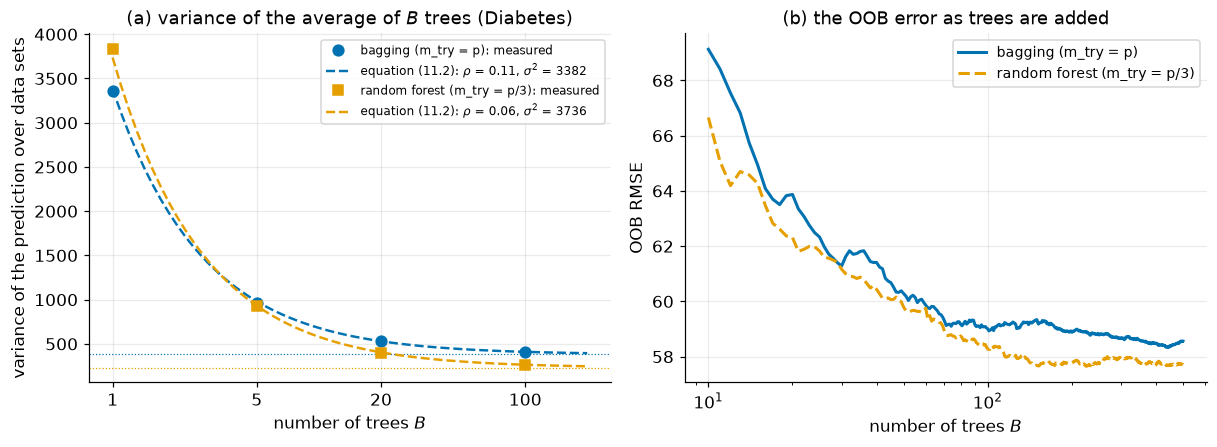

In [22]:
def figure_11_8():
    fig, axes = plt.subplots(1, 2, figsize=(11.2, 4.2))
    ax = axes[0]
    Bg = np.logspace(0, 2.3, 60)
    for (name, tab), color, marker in zip(var_tabs.items(), [BLUE, ORANGE], ["o", "s"]):
        s2, rho = var_info[name]
        ax.plot(tab["B"], tab["measured variance of the average"], marker=marker, color=color, lw=0, ms=7, label=f"{name}: measured")
        ax.plot(Bg, rho * s2 + (1 - rho) * s2 / Bg, color=color, lw=1.6, ls="--", label=rf"equation (11.2): $\rho$ = {rho:.2f}, $\sigma^2$ = {s2:.0f}")
        ax.axhline(rho * s2, color=color, lw=0.8, ls=":")
    ax.set_xscale("log")
    ax.set_xticks([1, 5, 20, 100])
    ax.set_xticklabels(["1", "5", "20", "100"])
    ax.minorticks_off()
    ax.set_xlabel("number of trees $B$")
    ax.set_ylabel("variance of the prediction over data sets")
    ax.set_title("(a) variance of the average of $B$ trees (Diabetes)")
    ax.legend(fontsize=8)

    ax = axes[1]
    for (name, c), color, ls in zip(oob_curves.items(), [BLUE, ORANGE], ["-", "--"]):
        ax.plot(np.arange(10, len(c) + 1), c[9:], color=color, lw=2, ls=ls, label=name)
    ax.set_xscale("log")
    ax.set_xlabel("number of trees $B$")
    ax.set_ylabel("OOB RMSE")
    ax.set_title("(b) the OOB error as trees are added")
    ax.legend(fontsize=9)
    fig.tight_layout()
    return fig


figure_11_8()
plt.show()

Figure 11.8 draws both measurements. In (a) the markers are the measured variances and the dashed curves are equation (11.2) with the estimated $\sigma^2$ and $\rho$, the dotted horizontal lines being the floors $\rho\sigma^2$ that no number of trees can break; the forest starts higher and ends lower. In (b) the OOB error of the forest is below that of bagging for every number of trees.

## 11.7 Which features matter? Importances

A forest of hundreds of trees is not readable, and the first question asked of it is which features it uses. Two answers are in common use, and both have well-known problems that this section measures.

### 11.7.1 Two definitions

The **impurity-based importance** (also called mean decrease in impurity, MDI) of the feature $j$ in one tree is the total decrease of the node impurity over the splits that use $j$, each weighted by the fraction $n_t/n$ of the training examples that reach the node; the forest averages over the trees, and the values are normalized to sum to $1$. It is computed during training, for free, on the *training* data. The **permutation importance** (Breiman, 2001) of the feature $j$ is the *increase of the error* of the fitted model when the column $j$ of a data set is randomly permuted, which breaks its association with the target and leaves its distribution unchanged; it is computed on data that the model has not been trained on (a validation set, or the OOB examples), averaged over several permutations, and measures what the model *loses* without the information in that feature.

We use the Breast Cancer training set, split once more into $319$ patients on which the forest is grown and $107$ patients on which the permutation importance is measured (the test set stays untouched), and we append **three constructed noise columns**, independent of the target: a continuous Gaussian column, a column of integers from $1$ to $5$, and a binary column. The forest has $300$ trees and the default $m_{\text{try}}$, and the permutation importance averages $20$ permutations.

In [23]:
rng = np.random.default_rng(SEED)
noise_cols = np.c_[rng.standard_normal(len(yb_tr)), rng.integers(1, 6, len(yb_tr)), rng.integers(0, 2, len(yb_tr))]
names_aug = bc_names + ["noise: continuous", "noise: 5 levels", "noise: binary"]
X_aug = np.hstack([Xb_tr, noise_cols])
Xf, Xv, yf, yv = train_test_split(X_aug, yb_tr, test_size=0.25, random_state=SEED, stratify=yb_tr)
rf_imp = RandomForestClassifier(300, random_state=SEED, n_jobs=2).fit(Xf, yf)
mdi = rf_imp.feature_importances_
perm = permutation_importance(rf_imp, Xv, yv, n_repeats=20, random_state=SEED, n_jobs=2, scoring="accuracy")
print(f"forest grown on {len(yf)} patients, permutation importance (accuracy) on {len(yv)} others;  accuracy on them: {rf_imp.score(Xv, yv):.3f}")
order = np.argsort(-mdi)
tab_imp = pd.DataFrame({"feature": [names_aug[i] for i in order[:8]], "MDI": mdi[order[:8]],
                        "permutation (mean)": perm.importances_mean[order[:8]], "permutation (sd)": perm.importances_std[order[:8]]})
print(tab_imp.to_string(index=False, float_format=lambda v: f"{v:.4f}"))
print("\nthe three noise columns:")
print(pd.DataFrame({"feature": names_aug[-3:], "MDI": mdi[-3:], "rank by MDI (of 33)": [int((mdi > v).sum()) + 1 for v in mdi[-3:]],
                    "permutation (mean)": perm.importances_mean[-3:], "permutation (sd)": perm.importances_std[-3:]}).to_string(index=False, float_format=lambda v: f"{v:.4f}"))
print(f"\nsum of the MDI of the three noise columns: {mdi[-3:].sum():.4f};  largest permutation importance of any feature: {perm.importances_mean.max():.4f}")

forest grown on 319 patients, permutation importance (accuracy) on 107 others;  accuracy on them: 0.963
             feature    MDI  permutation (mean)  permutation (sd)
        worst radius 0.1336              0.0145            0.0100
 mean concave points 0.1154              0.0061            0.0090
worst concave points 0.1094              0.0065            0.0094
     worst perimeter 0.1022              0.0145            0.0104
          worst area 0.0767              0.0084            0.0088
      mean perimeter 0.0575             -0.0047            0.0047
      mean concavity 0.0564             -0.0033            0.0095
         mean radius 0.0490              0.0028            0.0043

the three noise columns:
          feature    MDI  rank by MDI (of 33)  permutation (mean)  permutation (sd)
noise: continuous 0.0038                   29             -0.0005            0.0020
  noise: 5 levels 0.0011                   32              0.0000            0.0000
    noise: binary 0.0007

The two measures tell different stories. The MDI ranks the worst radius first ($0.134$), then the mean concave points ($0.115$), the worst concave points ($0.109$) and the worst perimeter ($0.102$), and gives the three noise columns $0.0038$, $0.0011$ and $0.0007$, $0.0055$ in all. Those are small but not zero, although the columns are independent of the target by construction. The reason is that MDI is computed on the *training* data, where trees grown to purity find splits on any column that look good by chance, and a column with many distinct values offers the most chances; the continuous column ranks $29$th of $33$, the five-level column $32$nd and the binary column last, consistent with this known bias of the impurity importance (Strobl et al., 2007).

The permutation importance, computed on $107$ patients that the forest has not seen, has no such bias: the noise columns have importances of $-0.0005\pm0.0020$, $0$ and $0$, centered on zero as they should be. But it is *noisy* and *small*. The largest value of any feature is $0.0182$, those of the two best features are $0.0145$ (the worst radius and the worst perimeter), and their standard deviations over the $20$ permutations are $0.010$. The resolution is also coarse: one patient out of $107$ is $0.0093$ of accuracy, so that $0.0145$ is about one and a half patients. Features that MDI ranks high, such as the mean perimeter ($0.0575$) and the mean radius ($0.049$), have a permutation importance near zero or negative ($-0.0047$ and $0.0028$). Does this mean that the size of the nucleus is unimportant? The next section shows that it does not.

### 11.7.2 Correlated features share the credit

The Breast Cancer features come in groups that measure the same thing: the radius, the perimeter and the area of a nucleus, each in a "mean" and a "worst" version, are correlated at $0.94$ or more (Section 6.2.4). When two features carry the same information a tree can use either one, and the splits are shared between them, which is the phenomenon of the twin columns of Section 10.8. We check this in two ways: we append a *copy* of the feature with the largest importance and look at both importances, and we compute the permutation importance of the whole group of six size features, permuted *together*.

In [24]:
def permutation_drop(model, X, y, cols, reps=30, seed=SEED):
    """Mean and sd of the drop of accuracy when the columns `cols` are permuted together (one permutation of the rows for all of them)."""
    rg = np.random.default_rng(seed)
    base = model.score(X, y)
    drops = []
    for _ in range(reps):
        Xp = X.copy()
        Xp[:, cols] = X[rg.permutation(len(y))][:, cols]
        drops.append(base - model.score(Xp, y))
    return float(np.mean(drops)), float(np.std(drops, ddof=1))


rf_one = RandomForestClassifier(300, random_state=SEED, n_jobs=2, max_features=None).fit(Xf, yf)
j_top = int(np.argmax(rf_one.feature_importances_[:30]))
Xf_dup, Xv_dup = np.c_[Xf, Xf[:, j_top]], np.c_[Xv, Xv[:, j_top]]
rf_dup = RandomForestClassifier(300, random_state=SEED, n_jobs=2, max_features=None).fit(Xf_dup, yf)
print(f"top feature by MDI: {names_aug[j_top]}")
print(f"  MDI without a copy (all features tried at every split): {rf_one.feature_importances_[j_top]:.3f}")
print(f"  MDI with a copy appended: original {rf_dup.feature_importances_[j_top]:.3f}, copy {rf_dup.feature_importances_[-1]:.3f}, sum {rf_dup.feature_importances_[j_top] + rf_dup.feature_importances_[-1]:.3f}")
print(f"  permutation importance without a copy: {permutation_drop(rf_one, Xv, yv, [j_top])[0]:.4f}")
print(f"  with a copy: original {permutation_drop(rf_dup, Xv_dup, yv, [j_top])[0]:.4f}, copy {permutation_drop(rf_dup, Xv_dup, yv, [Xv_dup.shape[1] - 1])[0]:.4f},"
      f" both permuted together {permutation_drop(rf_dup, Xv_dup, yv, [j_top, Xv_dup.shape[1] - 1])[0]:.4f}")

# the group of the six size features, permuted together
size_cols = [bc_names.index(n) for n in ["mean radius", "mean perimeter", "mean area", "worst radius", "worst perimeter", "worst area"]]
corr_size = np.corrcoef(Xb_tr[:, size_cols].T)
print(f"\nsmallest correlation among the six size features: {corr_size[np.triu_indices(6, 1)].min():.3f}")
group_drop, group_sd = permutation_drop(rf_imp, Xv, yv, size_cols, reps=100)
print(f"accuracy {rf_imp.score(Xv, yv):.3f}; drop when the six size features are permuted together: {group_drop:.3f} (sd {group_sd:.3f}),"
      f" against {perm.importances_mean[size_cols].max():.4f} for the best of them permuted alone")

top feature by MDI: mean concave points
  MDI without a copy (all features tried at every split): 0.303
  MDI with a copy appended: original 0.149, copy 0.154, sum 0.302


  permutation importance without a copy: 0.0262


  with a copy: original -0.0106, copy -0.0106, both permuted together 0.0271

smallest correlation among the six size features: 0.940


accuracy 0.963; drop when the six size features are permuted together: 0.148 (sd 0.024), against 0.0145 for the best of them permuted alone


Both measurements show the effect, in opposite ways. The MDI is *shared*: with all features tried at every split, the top feature (the mean concave points) has an importance of $0.303$; with a copy appended, the original gets $0.149$ and the copy $0.154$, and the two add up to $0.302$. The total is conserved and divided between twins, so each of them looks half as important as it is. The permutation importance is worse: it is $0.0262$ without the copy, but permuting *one* of the two columns leaves the other intact, and the loss disappears ($-0.0106$ for each copy, about one patient of $107$ in the favorable direction, within the resolution of the test set); permuting both together costs $0.0271$, the original value. A feature that is redundant with another one is, in the sense of the permutation, unimportant, and so are both of them.

The group of six size features shows it on the real data. They are correlated at $0.940$ or more, and each of them has a permutation importance of at most $0.0145$. Permuted together, they cost $0.148$ of accuracy (sd $0.024$ over $100$ permutations), ten times the best single value: the information they carry is essential, but redundant, so that no single column is. The rule is to **permute the groups of correlated features together** and to read the importance of a single feature in a correlated group as a statement about the model's *redundancy*, not about the feature's *value*.

### 11.7.3 Selecting features on the importances leaks the labels

Chapter 10 ended with a rule: any selection of features that uses the labels belongs *inside* the cross-validation loop. Importances are a selection tool, and the rule applies to them too, with the same consequence. We repeat the experiment of Section 10.11 with a forest: the data are *constructed noise*, $n=100$ examples with $p=200$ standard normal features and random labels, so that no method can have an expected accuracy above $0.5$. The ten features with the largest importance are selected, and a forest is evaluated on them by $5$-fold cross-validation, either with the selection done once on all the data (**outside**) or repeated on the training part of each fold (**inside**).

In [25]:
def importance_leak(reps=10, n=100, p=200, k=10, n_trees=100):
    rng = np.random.default_rng(SEED)
    res = []
    for r in range(reps):
        X, y = rng.standard_normal((n, p)), rng.integers(0, 2, n)
        cv = StratifiedKFold(5, shuffle=True, random_state=r)
        make = lambda: RandomForestClassifier(n_trees, random_state=r, n_jobs=2)
        top = np.argsort(-make().fit(X, y).feature_importances_)[:k]                          # selection with all the labels
        outside = cross_val_score(make(), X[:, top], y, cv=cv).mean()
        inside = []
        for tr, te in cv.split(X, y):
            top_f = np.argsort(-make().fit(X[tr], y[tr]).feature_importances_)[:k]            # selection with the training part only
            inside.append(make().fit(X[tr][:, top_f], y[tr]).score(X[te][:, top_f], y[te]))
        res.append((outside, np.mean(inside)))
    return np.array(res)


t0 = time.perf_counter()
leak = importance_leak()
print(f"pure noise, n = 100, p = 200, top 10 features by forest importance, {len(leak)} repetitions of 5-fold CV")
print(f"  selection OUTSIDE the loop: accuracy {leak[:, 0].mean():.3f} (SE {leak[:, 0].std(ddof=1) / np.sqrt(len(leak)):.3f})")
print(f"  selection INSIDE the loop:  accuracy {leak[:, 1].mean():.3f} (SE {leak[:, 1].std(ddof=1) / np.sqrt(len(leak)):.3f})")
print(f"[{time.perf_counter() - t0:.1f} s]")

pure noise, n = 100, p = 200, top 10 features by forest importance, 10 repetitions of 5-fold CV
  selection OUTSIDE the loop: accuracy 0.710 (SE 0.008)
  selection INSIDE the loop:  accuracy 0.518 (SE 0.021)
[15.0 s]


On pure noise, the accuracy with selection outside the loop is $0.710$ (SE $0.008$): $21$ points above the chance level $0.5$, from features that are unrelated to the target. Inside the loop the accuracy is $0.518$ (SE $0.021$), within one standard error of $0.5$, as it must be. Choosing the ten best of two hundred noise columns on all the data finds those that, by chance, correlate with the labels of these hundred patients, and a forest evaluated on them is rewarded for that. The importance of a feature is a function of the labels, and the rule of Chapter 10 applies to it without exception: *any step that looks at the labels, selection by importances included, is part of the model and belongs inside the cross-validation loop*.

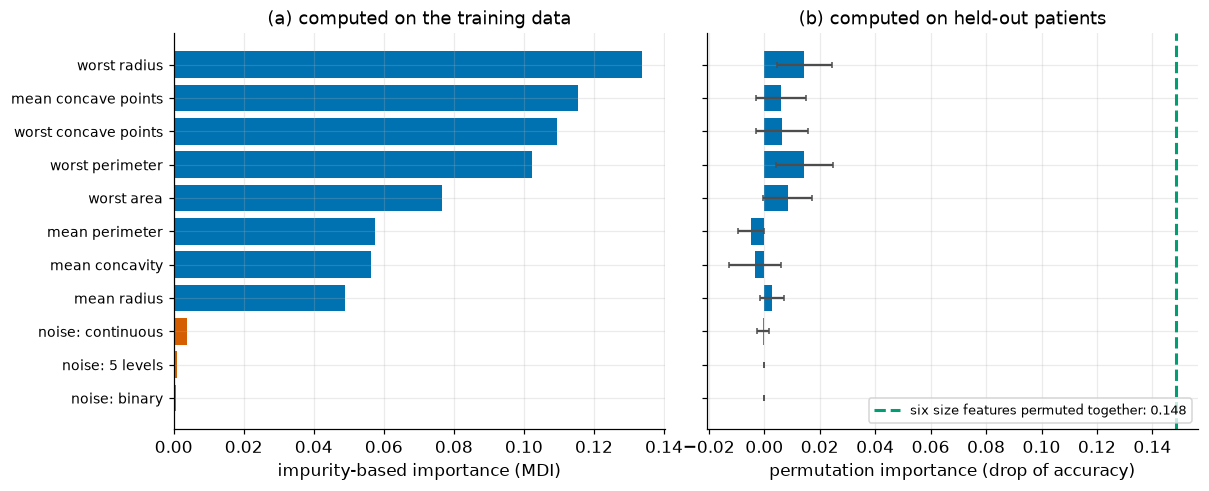

In [26]:
def figure_11_9():
    fig, axes = plt.subplots(1, 2, figsize=(11.2, 4.6))
    feats = [names_aug[i] for i in order[:8]] + names_aug[-3:]
    idx = [names_aug.index(f) for f in feats]
    colors = [VERMILION if f.startswith("noise") else BLUE for f in feats]
    ax = axes[0]
    ax.barh(range(len(feats)), mdi[idx][::-1], color=colors[::-1])
    ax.set_yticks(range(len(feats)))
    ax.set_yticklabels(feats[::-1], fontsize=9)
    ax.set_xlabel("impurity-based importance (MDI)")
    ax.set_title("(a) computed on the training data")
    ax = axes[1]
    ax.barh(range(len(feats)), perm.importances_mean[idx][::-1], xerr=perm.importances_std[idx][::-1], color=colors[::-1], ecolor="0.3", capsize=2)
    ax.axvline(group_drop, color=GREEN, lw=2, ls="--", label=f"six size features permuted together: {group_drop:.3f}")
    ax.set_yticks(range(len(feats)))
    ax.set_yticklabels([])
    ax.set_xlabel("permutation importance (drop of accuracy)")
    ax.set_title("(b) computed on held-out patients")
    ax.legend(fontsize=8.5, loc="lower right")
    fig.tight_layout()
    return fig


figure_11_9()
plt.show()

Figure 11.9 puts the two measures side by side. In (a) the importances of the training data separate the signal from the noise columns (in orange) but give half of the credit to whichever of two twins was chosen; in (b) the held-out measure is centered at zero for the noise, and small and uncertain for every single feature, while the dashed line shows the group of six size features. Practical conclusions: use the MDI for a first look, not for a decision; use the permutation importance on held-out data (or the OOB examples) for a decision, and permute correlated groups together; and remember that an importance describes the *fitted model*, not the world: a feature can be important for the model and have no causal effect, and the converse.

## 11.8 Boosting I: AdaBoost

### 11.8.1 Weak learners, weights and the algorithm

Bagging averages *independent* strong learners (deep trees) to reduce variance. **Boosting** does the opposite: it builds a *sequence* of weak learners (shallow trees, often a single split, called a **stump**), each one fitted to the mistakes of its predecessors, and adds them up. The first successful algorithm, **AdaBoost** (Freund and Schapire, 1997), is for classification with labels $y\in\{-1,+1\}$ and a base learner that accepts weights on the examples.

:::{admonition} Algorithm (AdaBoost)
:class: tip
Start with the weights $w_i^{(1)}=1/n$. For $m=1,\dots,M$:
1. fit a weak classifier $h_m(\mathbf{x})\in\{-1,+1\}$ to the weighted training set and compute its **weighted error** $\varepsilon_m=\sum_iw_i^{(m)}\mathbb{I}[h_m(\mathbf{x}_i)\ne y_i]$;
2. set $\alpha_m=\tfrac12\ln\dfrac{1-\varepsilon_m}{\varepsilon_m}$;
3. update $w_i^{(m+1)}=w_i^{(m)}e^{-\alpha_my_ih_m(\mathbf{x}_i)}/Z_m$, where $Z_m$ makes the weights sum to one.

The classifier is $\operatorname{sign}F_M(\mathbf{x})$ with $F_M(\mathbf{x})=\sum_{m=1}^M\alpha_mh_m(\mathbf{x})$.
:::

The weights of the examples that $h_m$ misclassifies are multiplied by $e^{\alpha_m}>1$ and those of the correct ones by $e^{-\alpha_m}<1$, so the next learner concentrates on the hard examples; a learner with a small error gets a large vote $\alpha_m$. The algorithm looks like a heuristic, but it is the exact solution of a stagewise optimization problem.

:::{admonition} Proposition 11.11 (AdaBoost minimizes the exponential loss stagewise)
:class: tip
Given $F_{m-1}$, consider the problem $\min_{\alpha,h}\sum_ie^{-y_i(F_{m-1}(\mathbf{x}_i)+\alpha h(\mathbf{x}_i))}$. Its solution has the following form. The weights $w_i\propto e^{-y_iF_{m-1}(\mathbf{x}_i)}$ (normalized to sum to one) are those of the algorithm; for a fixed $h$ with weighted error $\varepsilon$ the best $\alpha$ is $\frac12\ln\frac{1-\varepsilon}{\varepsilon}$, and the value of the criterion is then $\big(\sum_ie^{-y_iF_{m-1}(\mathbf{x}_i)}\big)\cdot2\sqrt{\varepsilon(1-\varepsilon)}$, which is smallest for the $h$ of least weighted error.
:::

*Proof.* With $W=\sum_ie^{-y_iF_{m-1}(\mathbf{x}_i)}$ and normalized weights $w_i$, the criterion is $W\sum_iw_ie^{-\alpha y_ih(\mathbf{x}_i)}=W\big[(1-\varepsilon)e^{-\alpha}+\varepsilon e^{\alpha}\big]$, because $y_ih(\mathbf{x}_i)=+1$ for the examples classified correctly (total weight $1-\varepsilon$) and $-1$ for the others. This is convex in $\alpha$; setting the derivative $-(1-\varepsilon)e^{-\alpha}+\varepsilon e^{\alpha}$ to zero gives $e^{2\alpha}=(1-\varepsilon)/\varepsilon$, and substituting, $(1-\varepsilon)\sqrt{\varepsilon/(1-\varepsilon)}+\varepsilon\sqrt{(1-\varepsilon)/\varepsilon}=2\sqrt{\varepsilon(1-\varepsilon)}$. The factor is increasing in $\varepsilon$ on $[0,\frac12]$, so the best $h$ minimizes the weighted error. Finally $e^{-y_i(F_{m-1}+\alpha_mh)}=e^{-y_iF_{m-1}}e^{-\alpha_my_ih}$ shows that the new weights are the old ones times $e^{-\alpha_my_ih_m(\mathbf{x}_i)}$, up to normalization. $\blacksquare$

### 11.8.2 The training error goes to zero geometrically

:::{admonition} Theorem 11.12 (training error of AdaBoost)
:class: tip
Let $\gamma_m=\frac12-\varepsilon_m$ be the edge of the $m$-th weak learner over random guessing. The training error of $\operatorname{sign}F_M$ satisfies
$$
\frac1n\sum_i\mathbb{I}[y_iF_M(\mathbf{x}_i)\le0]\ \le\ \frac1n\sum_ie^{-y_iF_M(\mathbf{x}_i)}\ =\ \prod_{m=1}^MZ_m\ =\ \prod_{m=1}^M2\sqrt{\varepsilon_m(1-\varepsilon_m)}\ \le\ \exp\Big(-2\sum_{m=1}^M\gamma_m^2\Big).
\tag{11.3}$$
In particular, if every weak learner has an edge of at least $\gamma_0>0$, the training error is at most $e^{-2\gamma_0^2M}$.
:::

*Proof.* The first inequality holds because $\mathbb{I}[t\le0]\le e^{-t}$. For the equality, unrolling the update gives $w_i^{(M+1)}=\frac1n\,e^{-y_iF_M(\mathbf{x}_i)}\big/\prod_mZ_m$ by induction on $M$; the weights sum to one, so $\frac1n\sum_ie^{-y_iF_M(\mathbf{x}_i)}=\prod_mZ_m$. By Proposition 11.11 with normalized weights ($W=1$), $Z_m=2\sqrt{\varepsilon_m(1-\varepsilon_m)}=\sqrt{1-4\gamma_m^2}$, and $1-x\le e^{-x}$ gives $\sqrt{1-4\gamma_m^2}\le e^{-2\gamma_m^2}$. $\blacksquare$

The bound does not require the weak learners to be good, only better than chance by some margin, which is where the name *boosting* (of weak learners into a strong one) comes from. It is a bound on the *training* error, and its meaning is limited by the fact that the training error of a rich enough model is zero anyway; what makes AdaBoost interesting is what happens to the *test* error after the training error has reached zero, and Section 11.8.3 looks at it.

**What does the exponential loss estimate?** In the sense of Section 8.4: the population minimizer of $\mathbb{E}[e^{-yF(\mathbf{x})}\mid\mathbf{x}]=\eta e^{-F}+(1-\eta)e^{F}$, with $\eta=\mathbb{P}(y=+1\mid\mathbf{x})$, is found by setting the derivative to zero, $F^\ast(\mathbf{x})=\frac12\ln\frac{\eta}{1-\eta}$, so that $\eta=1/(1+e^{-2F^\ast})$: **AdaBoost estimates half the log-odds**, as the logistic loss estimates the log-odds themselves, and $\operatorname{sign}F^\ast$ is the Bayes classifier. We shall return to the probabilities in Section 11.10.

### 11.8.3 AdaBoost with stumps on Breast Cancer

The cell implements AdaBoost from scratch with decision stumps (`DecisionTreeClassifier(max_depth=1)` accepts the weights through `sample_weight`), checks the identity $\frac1n\sum_ie^{-y_iF_M}=\prod_mZ_m$ of Theorem 11.12 and the bound, compares the result with `AdaBoostClassifier`, and measures the test error of the first $M$ rounds by $5$-fold cross-validation on the training set.

In [27]:
def adaboost_fit(X, y, M):
    """AdaBoost with decision stumps, labels in {-1, +1}. Returns stumps, votes alpha_m, normalizers Z_m, weighted errors."""
    n = len(y)
    w = np.full(n, 1 / n)
    stumps, alphas, Zs, epss = [], [], [], []
    for m in range(M):
        stump = DecisionTreeClassifier(max_depth=1, random_state=SEED).fit(X, y, sample_weight=w)
        h = stump.predict(X)
        eps = float(np.clip(w[h != y].sum(), 1e-12, 1 - 1e-12))
        alpha = 0.5 * np.log((1 - eps) / eps)
        w = w * np.exp(-alpha * y * h)
        Z = w.sum()
        w /= Z
        stumps.append(stump); alphas.append(alpha); Zs.append(Z); epss.append(eps)
    return stumps, np.array(alphas), np.array(Zs), np.array(epss)


def adaboost_scores(stumps, alphas, X):
    """F_m(X) for m = 1..M, as a matrix of shape (M, n)."""
    return np.cumsum([a * s.predict(X) for s, a in zip(stumps, alphas)], axis=0)


ypm_tr = 2 * yb_tr - 1                                                 # labels in {-1, +1}
M_ada = 400
stumps, alphas, Zs, epss = adaboost_fit(Xb_tr, ypm_tr, M_ada)
F_tr = adaboost_scores(stumps, alphas, Xb_tr)
train_err = np.mean(np.sign(F_tr) != ypm_tr, axis=1)
exp_loss = np.mean(np.exp(-ypm_tr * F_tr), axis=1)
bound = np.cumprod(Zs)
print(f"identity (1/n) sum exp(-y F_M) = prod Z_m:  largest relative difference over the 400 rounds {np.max(np.abs(exp_loss / bound - 1)):.1e}")
print(f"weighted errors of the stumps: first {epss[0]:.3f}, smallest {epss.min():.3f}, largest {epss.max():.3f}  (edges gamma_m = 1/2 - eps_m between {0.5 - epss.max():.3f} and {0.5 - epss.min():.3f})")
first_zero = int(np.argmax(train_err == 0)) + 1
print(f"the training error first reaches zero at round {first_zero}")
rows = [{"M": M, "training error": train_err[M - 1], "exp loss = product of Z_m": bound[M - 1],
         "bound exp(-2 sum gamma^2)": np.exp(-2 * np.sum((0.5 - epss[:M]) ** 2))} for M in [1, 10, 50, 100, 200, 400]]
print(pd.DataFrame(rows).to_string(index=False, float_format=lambda v: f"{v:.4g}"))

# scikit-learn: the same algorithm (its vote is twice ours, an equivalent form of the update)
ada_sk = AdaBoostClassifier(DecisionTreeClassifier(max_depth=1), n_estimators=50, random_state=SEED).fit(Xb_tr, yb_tr)
print(f"\nscikit-learn, 50 rounds: votes equal twice ours to {np.abs(ada_sk.estimator_weights_ - 2 * alphas[:50]).max():.1e};"
      f" predictions on the {len(yb_te)} test points identical to ours: {np.array_equal(ada_sk.predict(Xb_te), (adaboost_scores(stumps[:50], alphas[:50], Xb_te)[-1] > 0).astype(int))}")

# 5-fold cross-validated error of the first M rounds, on the training set
cv_err = np.zeros(M_ada)
cv_folds = StratifiedKFold(5, shuffle=True, random_state=SEED)
for tr, va in cv_folds.split(Xb_tr, yb_tr):
    st, al, _, _ = adaboost_fit(Xb_tr[tr], ypm_tr[tr], M_ada)
    cv_err += np.mean(np.sign(adaboost_scores(st, al, Xb_tr[va])) != ypm_tr[va], axis=1) / 5
print("\n5-fold CV error of the first M rounds:  " + "   ".join(f"M={M}: {cv_err[M - 1]:.4f}" for M in [1, 5, 10, 25, 50, 100, 200, 400]))
print(f"minimum over M: {cv_err.min():.4f} at M = {int(np.argmin(cv_err)) + 1}")

# margins y F_M / sum(alpha): the normalized margin of every training example
for M in [10, 50, 400]:
    marg = ypm_tr * F_tr[M - 1] / alphas[:M].sum()
    print(f"M = {M:3d}: smallest normalized margin {marg.min():+.3f}, median {np.median(marg):.3f}, fraction below 0.1: {np.mean(marg < 0.1):.3f}")

identity (1/n) sum exp(-y F_M) = prod Z_m:  largest relative difference over the 400 rounds 2.9e-15
weighted errors of the stumps: first 0.070, smallest 0.070, largest 0.454  (edges gamma_m = 1/2 - eps_m between 0.046 and 0.430)
the training error first reaches zero at round 32
  M  training error  exp loss = product of Z_m  bound exp(-2 sum gamma^2)
  1         0.07042                     0.5117                     0.6914
 10         0.01878                     0.1165                     0.2035
 50               0                   0.007856                    0.01676
100               0                   0.001042                   0.002447
200               0                  1.016e-05                  3.066e-05
400               0                  2.255e-09                  1.038e-08

scikit-learn, 50 rounds: votes equal twice ours to 1.1e-15; predictions on the 143 test points identical to ours: True



5-fold CV error of the first M rounds:  M=1: 0.0845   M=5: 0.0563   M=10: 0.0564   M=25: 0.0447   M=50: 0.0353   M=100: 0.0282   M=200: 0.0353   M=400: 0.0353
minimum over M: 0.0259 at M = 76
M =  10: smallest normalized margin -0.286, median 0.608, fraction below 0.1: 0.031
M =  50: smallest normalized margin +0.074, median 0.397, fraction below 0.1: 0.009
M = 400: smallest normalized margin +0.136, median 0.309, fraction below 0.1: 0.000


The numbers confirm the theory, line by line. The identity $\frac1n\sum_ie^{-y_iF_M}=\prod_mZ_m$ holds to $2\cdot10^{-15}$ over the $400$ rounds. The stumps have positive edges throughout, between $0.046$ and $0.430$: the first stump is the best one ($\varepsilon_1=0.070$), and as the weights concentrate on the hard patients the weighted error of the later stumps rises to $0.454$, barely better than guessing. The training error is zero from round $32$, and the exponential loss, which bounds it, falls by about $4\%$ per round afterwards ($0.0010$ at $M=100$, $2.3\cdot10^{-9}$ at $M=400$). The bound $\exp(-2\sum_m\gamma_m^2)$ holds and is loose by a factor of about $5$ at $M=400$; $\prod_mZ_m$ is the sharper one. Our code and scikit-learn's `AdaBoostClassifier` are the same algorithm: its votes are exactly twice ours (its form of the update for $K$ classes reduces to $\ln\frac{1-\varepsilon}{\varepsilon}$ with two classes) and the $143$ test predictions are identical.

The cross-validated error is the surprise (Figure 11.10(a)). It falls from $0.0845$ for one stump to $0.0259$ at $M=76$, and it does *not* rise when the training error reaches zero at round $32$: it is $0.0282$ at $M=100$ and $0.0353$ at $M=200$ and at $M=400$, a difference of three patients in $426$ that the data cannot tell from noise. Continuing to boost after the training error is zero did no visible harm. Part of the explanation is in the margins (Figure 11.10(b)): the smallest normalized margin $y_iF_M(\mathbf{x}_i)/\sum_m\alpha_m$ is $-0.286$ at $M=10$, when some training patients are still misclassified, and it grows to $+0.074$ at $M=50$ and $+0.136$ at $M=400$, so that the *least* confident training patient becomes more confident with every round (the fraction of patients with a margin below $0.1$ is $3.1\%$, $0.9\%$ and $0$). Schapire, Freund, Bartlett and Lee (1998) showed that the test error is bounded by a quantity that depends on the margins and not on $M$. This margin explanation is *incomplete*: it does not account for every case of the behavior, and AdaBoost does overfit when the labels are noisy (Further reading). Breast Cancer is nearly separable, and what the experiment shows is one favorable case, not a theorem about boosting.

## 11.9 Boosting II: gradient boosting

### 11.9.1 Boosting as gradient descent in function space

AdaBoost minimizes the exponential loss one weak learner at a time. **Gradient boosting** (Friedman, 2001) does the same for any differentiable loss, by recognizing the stagewise step as a step of gradient descent, the algorithm of Chapter 7. Let $\ell(y,F)$ be a loss, and let $L(\mathbf{F})=\sum_i\ell(y_i,F_i)$ be the training loss as a function of the vector $\mathbf{F}=(F(\mathbf{x}_1),\dots,F(\mathbf{x}_n))\in\mathbb{R}^n$ of the values of the model on the training set. In this $n$-dimensional space, gradient descent is $\mathbf{F}\leftarrow\mathbf{F}-\nu\nabla L(\mathbf{F})$, with $\nabla L(\mathbf{F})_i=\partial\ell(y_i,F_i)/\partial F_i$. The vector $\mathbf{r}=-\nabla L(\mathbf{F})$ is called the **pseudo-residual**: for the squared loss $\ell=\frac12(y-F)^2$ it is the residual $y_i-F_i$, for the logistic loss with $F$ the log-odds and $y\in\{0,1\}$ it is $y_i-p_i$ with $p_i=1/(1+e^{-F_i})$. But a vector of values on the training set is not a model: it says nothing at a new $\mathbf{x}$. The remedy is to *fit a tree to the pseudo-residuals* by least squares, which gives a function defined everywhere that approximates the gradient step, and to add it.

:::{admonition} Algorithm (gradient boosting)
:class: tip
Start with the constant $F_0=\arg\min_c\sum_i\ell(y_i,c)$. For $m=1,\dots,M$:
1. compute the pseudo-residuals $r_i=-\partial\ell(y_i,F)/\partial F\,\big|_{F=F_{m-1}(\mathbf{x}_i)}$;
2. fit a regression tree $f_m$ with $J$ leaves to $(\mathbf{x}_i,r_i)$ by least squares (Section 11.2);
3. update $F_m=F_{m-1}+\nu f_m$, where $\nu\in(0,1]$ is the **learning rate** (shrinkage).
:::

The step is a legitimate descent direction, for a simple reason.

:::{admonition} Proposition 11.13 (the fitted tree is a descent direction)
:class: tip
Let $f$ be the least-squares fit of a tree with a given partition to the pseudo-residuals $\mathbf{r}=-\nabla L(\mathbf{F})$ and let $\mathbf{f}=(f(\mathbf{x}_i))_i$. Then $\langle\nabla L(\mathbf{F}),\mathbf{f}\rangle=-\lVert\mathbf{f}\rVert^2\le0$, so for a small enough $\nu$ the loss decreases: $L(\mathbf{F}+\nu\mathbf{f})=L(\mathbf{F})-\nu\lVert\mathbf{f}\rVert^2+O(\nu^2)$, and the first-order decrease is zero only if $\mathbf{r}$ is orthogonal to the leaf indicators of the partition.
:::

*Proof.* For a fixed partition the fit $\mathbf{f}$ is the orthogonal projection of $\mathbf{r}$ on the span of the leaf indicators (Proposition 11.1: each leaf value is the mean of $\mathbf{r}$ in the leaf). A projection satisfies $\langle\mathbf{r},\mathbf{f}\rangle=\lVert\mathbf{f}\rVert^2$, because $\mathbf{r}-\mathbf{f}\perp\mathbf{f}$. The first-order Taylor expansion of $L$ gives the rest. $\blacksquare$

So boosting is *gradient descent in the space of fitted values, with the gradient projected on a class of trees*, and everything that Chapter 7 says about gradient descent has an analogue: the learning rate $\nu$ is the step, the number of rounds $M$ is the number of iterations, and *stopping early is a form of regularization* (Section 7.7.2). For the squared loss and a fixed linear smoother $\mathbf{S}$ in place of the tree, the algorithm gives $\mathbf{r}_m=(\mathbf{I}-\nu\mathbf{S})\mathbf{r}_{m-1}$, hence $\mathbf{F}_M=\big(\mathbf{I}-(\mathbf{I}-\nu\mathbf{S})^M\big)\mathbf{y}$ when $F_0=0$, the filter-factor picture of Section 7.7.2; with trees the smoother changes at every round, which is what makes the procedure adaptive.

### 11.9.2 Squared loss from scratch

For the squared loss the algorithm is a few lines. The cell implements it with scikit-learn's tree as the weak learner, and compares it with `GradientBoostingRegressor` on Diabetes.

In [28]:
def gb_fit(X, y, M, nu, depth):
    """Gradient boosting with the squared loss: F_0 = mean, then trees fitted to the residuals."""
    F = np.full(len(y), y.mean())
    trees = []
    for m in range(M):
        tree = DecisionTreeRegressor(max_depth=depth, random_state=SEED).fit(X, y - F)     # the pseudo-residual is the residual
        F = F + nu * tree.predict(X)
        trees.append(tree)
    return y.mean(), trees


def gb_predict(model, X, nu):
    f0, trees = model
    return f0 + nu * np.sum([t.predict(X) for t in trees], axis=0)


for M in [1, 5, 20, 100]:
    mine = gb_fit(Xd_tr, yd_tr, M, 0.1, 3)
    sk = GradientBoostingRegressor(n_estimators=M, learning_rate=0.1, max_depth=3, random_state=SEED).fit(Xd_tr, yd_tr)
    diff = np.abs(gb_predict(mine, Xd_te, 0.1) - sk.predict(Xd_te))
    print(f"M = {M:3d}: largest difference between our predictions and scikit-learn's on the test inputs: {diff.max():.1e}"
          f"   (mean |prediction| difference {diff.mean():.1e})")

M =   1: largest difference between our predictions and scikit-learn's on the test inputs: 0.0e+00   (mean |prediction| difference 0.0e+00)
M =   5: largest difference between our predictions and scikit-learn's on the test inputs: 2.8e-14   (mean |prediction| difference 1.0e-14)
M =  20: largest difference between our predictions and scikit-learn's on the test inputs: 8.5e-14   (mean |prediction| difference 2.0e-14)
M = 100: largest difference between our predictions and scikit-learn's on the test inputs: 9.5e+00   (mean |prediction| difference 3.4e-01)


The two implementations agree to rounding for the first $20$ rounds ($3\cdot10^{-14}$ to $9\cdot10^{-14}$) and then, at $M=100$, differ by $0.34$ on average over the test inputs and by $9.5$ at the worst patient (the standard deviation of the target is about $77$). The difference is not an error. Comparing the trees one by one shows that they are identical up to round $14$, and that at round $15$ they differ at a node reached by only three training patients, where two different features (`bp` in our tree, `age` in scikit-learn's) give *exactly the same partition*, hence exactly the same gain. A tie is broken by the order in which the features are examined, which is random: our trees all use the same seed and scikit-learn's boosting draws a new seed for every tree. Both trees have the same predictions on the training set, but different thresholds, and a test patient that falls between the two thresholds is treated differently, which accumulates over the rounds. These are the near-ties of Section 11.3.2 and the instability of Section 11.5.5 again, at the smallest scale: two correct implementations of the algorithm give two different, equally good models.

### 11.9.3 Newton boosting: leaf values and the regularized gain

Fitting the tree to the *gradient* and then choosing the leaf values by the mean of the residuals is a first-order method. Modern implementations (XGBoost, LightGBM, scikit-learn's histogram-based boosting) use a **second-order** step in each leaf, with a penalty on the leaf values, which for the logistic loss, for example, corrects the fact that the gradient $y-p$ is a poor guide where $p$ is near $0$ or $1$. Write $g_i=\partial\ell/\partial F\big|_{F_{m-1}(\mathbf{x}_i)}$ for the gradient and $q_i=\partial^2\ell/\partial F^2\big|_{F_{m-1}(\mathbf{x}_i)}$ for the curvature of the loss at the current model.

:::{admonition} Proposition 11.14 (Newton leaf values and split gain)
:class: tip
Approximate the loss after adding a tree $f$ by its second-order expansion and add a penalty on the leaf values and on the number of leaves:
$$
\sum_i\Big[g_if(\mathbf{x}_i)+\tfrac12q_if(\mathbf{x}_i)^2\Big]+\tfrac12\lambda\sum_jw_j^2+\gamma\lvert T\rvert,\qquad f(\mathbf{x})=w_j\ \text{ for }\mathbf{x}\in R_j.
$$
For a fixed partition with leaves $j$, let $G_j=\sum_{i\in R_j}g_i$ and $Q_j=\sum_{i\in R_j}q_i$. Then the best leaf values and the value of the criterion are
$$
w_j^\ast=-\frac{G_j}{Q_j+\lambda},\qquad
\text{criterion}=-\frac12\sum_j\frac{G_j^2}{Q_j+\lambda}+\gamma\lvert T\rvert,
\tag{11.4}$$
and the split of a node with sums $(G,Q)$ into children with $(G_L,Q_L)$ and $(G_R,Q_R)$ has the **gain**
$$
\frac12\left[\frac{G_L^2}{Q_L+\lambda}+\frac{G_R^2}{Q_R+\lambda}-\frac{(G_L+G_R)^2}{Q_L+Q_R+\lambda}\right]-\gamma .
\tag{11.5}$$
:::

*Proof.* The criterion is a sum over the leaves of $G_jw_j+\frac12(Q_j+\lambda)w_j^2$, a parabola in $w_j$ minimized at $-G_j/(Q_j+\lambda)$ with minimum $-\frac12G_j^2/(Q_j+\lambda)$. The gain is the decrease of $-\frac12\sum_jG_j^2/(Q_j+\lambda)+\gamma\lvert T\rvert$ when a leaf is replaced by two, which adds one leaf and so one $\gamma$. $\blacksquare$

Three remarks connect (11.4) and (11.5) to what we know. **(i)** For the squared loss $g_i=F_i-y_i$ and $q_i=1$, so that $w_j^\ast=\frac{n_j}{n_j+\lambda}\bar r_j$, the mean residual shrunk toward zero as in ridge regression (the factor is $1$ for $\lambda=0$), and for $\lambda=\gamma=0$ the gain (11.5) is *half the gain of Proposition 11.2*: the regression tree of Section 11.2 is the special case. **(ii)** For the logistic loss $g_i=p_i-y_i$ and $q_i=p_i(1-p_i)$, so $w_j^\ast=\sum(y_i-p_i)/\sum p_i(1-p_i)$ (one Newton step per leaf, Section 7.3). **(iii)** $\gamma$ is the price per leaf of the cost-complexity pruning of Section 11.4: a split is worth making only if its gain exceeds $\gamma$.

We check the proposition against scikit-learn's `HistGradientBoostingRegressor`, which grows the tree with the gain (11.5) (squared loss, $q_i=1$) after binning the features into at most $255$ bins; the Diabetes features have fewer distinct values than that, so that the binning loses nothing. With one round, a learning rate of $1$ and two leaves, the model is the mean plus one stump, and we compute the best split with (11.5) ourselves and compare.

In [29]:
def newton_best_split(x, g, q, lam):
    """Best threshold of one feature by the gain (11.5) with gamma = 0. Returns (gain, threshold)."""
    order = np.argsort(x, kind="stable")
    xs, gs, qs = x[order], g[order], q[order]
    GL, QL = np.cumsum(gs)[:-1], np.cumsum(qs)[:-1]
    G, Q = gs.sum(), qs.sum()
    gain = 0.5 * (GL ** 2 / (QL + lam) + (G - GL) ** 2 / (Q - QL + lam) - G ** 2 / (Q + lam))
    gain = np.where(xs[:-1] < xs[1:], gain, -np.inf)
    k = int(np.argmax(gain))
    return float(gain[k]), 0.5 * (xs[k] + xs[k + 1])


Xd32 = as_f32(Xd_tr)
base = yd_tr.mean()
g_i, q_i = base - yd_tr, np.ones_like(yd_tr)                             # squared loss at F_0 = the mean: g = F - y, q = 1
rows = []
for lam in [0.0, 10.0, 100.0]:
    best = max(((*newton_best_split(Xd32[:, j], g_i, q_i, lam), j) for j in range(10)), key=lambda t: t[0])
    gain, thr, j = best
    left = Xd32[:, j] <= thr
    w_left = -g_i[left].sum() / (q_i[left].sum() + lam)                  # equation (11.4)
    w_right = -g_i[~left].sum() / (q_i[~left].sum() + lam)
    hgb = HistGradientBoostingRegressor(max_iter=1, learning_rate=1.0, max_leaf_nodes=2, min_samples_leaf=1, l2_regularization=lam,
                                        early_stopping=False, random_state=SEED).fit(Xd_tr, yd_tr)
    pred = hgb.predict(Xd_tr)
    vals = np.unique(np.round(pred, 8))
    rows.append({"lambda": lam, "our split": f"{diab_names[j]} <= {thr:.4f}", "n_left": int(left.sum()),
                 "our leaf values": f"{base + w_left:.4f}, {base + w_right:.4f}",
                 "HistGB leaf values": ", ".join(f"{v:.4f}" for v in sorted(vals)),
                 "same partition": bool(np.array_equal(left, pred == pred[left][0]))})
print(pd.DataFrame(rows).to_string(index=False))

 lambda     our split  n_left    our leaf values HistGB leaf values  same partition
    0.0 bmi <= 0.0051     197 119.7868, 205.1493 119.7868, 205.1493            True
   10.0 bmi <= 0.0051     197 121.4563, 201.6211 121.4563, 201.6211            True
  100.0 bmi <= 0.0051     197 131.4224, 183.4378 131.4224, 183.4378            True


The split chosen by (11.5) is the one of the library in all three cases, the same `bmi` threshold with $197$ patients to the left, and the leaf values agree to four decimals: the values are those of the leaf means ($119.79$ and $205.15$) for $\lambda=0$ and move toward the overall mean as $\lambda$ grows, to $121.46$ and $201.62$ for $\lambda=10$ and to $131.42$ and $183.44$ for $\lambda=100$, the shrinkage factor $n_j/(n_j+\lambda)$ of remark (i) being weaker on the larger leaf ($197$ patients) than on the smaller one ($134$). The regularization changes the values and, here, not the partition; with a smaller leaf or a larger $\lambda$ it would change the partition too, since $\lambda$ penalizes small leaves more. The binning of the library did not matter: its thresholds are different from our midpoints but produce the same partition.

### 11.9.4 The learning rate and the number of rounds

Gradient boosting has more hyperparameters than a forest, and unlike the number of trees of a forest the number of rounds *is* a regularization parameter: Proposition 11.13 says that every round decreases the training loss, and a model with enough rounds fits the training set perfectly. Friedman's recommendation is a *small learning rate* and many rounds: a small step follows the gradient flow more closely, as in Chapter 7, and smooth steps generalize better than large ones. The next cell measures this on Diabetes with $5$-fold cross-validation of the RMSE after each round, for depth-$2$ trees and $\nu=1$, $0.1$ and $0.01$.

In [30]:
cv5 = KFold(5, shuffle=True, random_state=SEED)


def staged_cv_rmse(make_model, X, y, cv):
    """5-fold CV RMSE after each boosting round (the models must be fitted with the maximal number of rounds)."""
    mse = None
    for tr, va in cv.split(X):
        m = make_model().fit(X[tr], y[tr])
        e = np.array([np.mean((p - y[va]) ** 2) * len(va) for p in m.staged_predict(X[va])])
        mse = e if mse is None else mse + e
    return np.sqrt(mse / len(y))


t0 = time.perf_counter()
nu_curves = {}
for nu, M in [(1.0, 400), (0.1, 1000), (0.01, 3000)]:
    nu_curves[nu] = staged_cv_rmse(lambda: GradientBoostingRegressor(n_estimators=M, learning_rate=nu, max_depth=2, random_state=SEED), Xd_tr, yd_tr, cv5)
rows = [{"learning rate": nu, "rounds": len(c), "best CV RMSE": c.min(), "at round": int(np.argmin(c)) + 1, "CV RMSE after all rounds": c[-1]} for nu, c in nu_curves.items()]
print("Diabetes, depth-2 trees, 5-fold CV")
print(pd.DataFrame(rows).to_string(index=False, float_format=lambda v: f"{v:.2f}"))

# depth of the trees = order of the interactions
depth_curves = {}
for depth in [1, 2, 3, 6]:
    depth_curves[depth] = staged_cv_rmse(lambda: GradientBoostingRegressor(n_estimators=800, learning_rate=0.05, max_depth=depth, random_state=SEED), Xd_tr, yd_tr, cv5)
rows = [{"depth": d, "best CV RMSE": c.min(), "at round": int(np.argmin(c)) + 1, "CV RMSE after 800 rounds": c[-1]} for d, c in depth_curves.items()]
print("\nDiabetes, learning rate 0.05, 5-fold CV")
print(pd.DataFrame(rows).to_string(index=False, float_format=lambda v: f"{v:.2f}"))

# subsampling the examples at each round (stochastic gradient boosting) and bagging versus boosting, stumps versus deep trees
stoch = staged_cv_rmse(lambda: GradientBoostingRegressor(n_estimators=800, learning_rate=0.05, max_depth=2, subsample=0.5, random_state=SEED), Xd_tr, yd_tr, cv5)
print(f"\nsubsample = 0.5 (depth 2, learning rate 0.05): best CV RMSE {stoch.min():.2f} at round {int(np.argmin(stoch)) + 1}"
      f"  (without subsampling: {depth_curves[2].min():.2f})")
rows = [{"base learner": "stumps (depth 1)", "bagging, 300 trees": cv_rmse(BaggingRegressor(DecisionTreeRegressor(max_depth=1), n_estimators=300, random_state=SEED), Xd_tr, yd_tr, cv5),
         "boosting, best round": depth_curves[1].min()},
        {"base learner": "deep trees", "bagging, 300 trees": cv_rmse(BaggingRegressor(DecisionTreeRegressor(), n_estimators=300, random_state=SEED, n_jobs=2), Xd_tr, yd_tr, cv5),
         "boosting, best round": depth_curves[6].min()}]
print("\nbagging against boosting (5-fold CV RMSE on Diabetes; depth 6 for the deep boosted trees)")
print(pd.DataFrame(rows).to_string(index=False, float_format=lambda v: f"{v:.2f}"))
print(f"[{time.perf_counter() - t0:.1f} s]")

Diabetes, depth-2 trees, 5-fold CV
 learning rate  rounds  best CV RMSE  at round  CV RMSE after all rounds
          1.00     400         65.34         2                     79.87
          0.10    1000         60.32        75                     69.91
          0.01    3000         60.46       592                     63.49



Diabetes, learning rate 0.05, 5-fold CV
 depth  best CV RMSE  at round  CV RMSE after 800 rounds
     1         58.66       360                     59.11
     2         60.06       177                     64.94
     3         61.83        81                     67.00
     6         63.77        26                     65.53



subsample = 0.5 (depth 2, learning rate 0.05): best CV RMSE 58.76 at round 132  (without subsampling: 60.06)



bagging against boosting (5-fold CV RMSE on Diabetes; depth 6 for the deep boosted trees)
    base learner  bagging, 300 trees  boosting, best round
stumps (depth 1)               64.45                 58.66
      deep trees               60.41                 63.77
[18.7 s]


The learning rate behaves as the theory of Chapter 7 suggests (Figure 11.11(b)). With $\nu=1$ the best CV RMSE is $65.34$, reached at round $2$, and it rises to $79.87$ after $400$ rounds: each step is a full fit of the residuals, and the model follows the noise at once. With $\nu=0.1$ and $\nu=0.01$ the minima are almost the same ($60.32$ at round $75$ and $60.46$ at round $592$, a difference that the folds cannot resolve), and what changes is the *flatness* of the minimum: after $3000$ rounds the CV RMSE of $\nu=0.01$ is $63.49$, while that of $\nu=0.1$ is $69.91$ after $1000$. A small learning rate does not find a better model, it makes the number of rounds a less delicate parameter, at the price of more rounds. The rule of thumb is to set $\nu$ as small as the budget allows ($0.1$ or less) and to choose $M$ by cross-validation or early stopping.

The depth of the trees fixes the order of the interactions that the model can represent, since a sum of stumps is an *additive* model $\sum_jf_j(x_j)$, and trees of depth $d$ allow interactions between up to $d$ features. On Diabetes the shallowest trees win (Figure 11.12(a)): the best CV RMSE is $58.66$ for stumps (at round $360$), $60.06$ for depth $2$, $61.83$ for depth $3$ and $63.77$ for depth $6$, and the deeper the trees, the fewer rounds are needed and the faster the error rises afterwards ($64.94$, $67.00$ and $65.53$ after $800$ rounds, against $59.11$ for stumps). The minima are minima over the rounds of one set of folds, so they are optimistic, but the order is clear and consistent with Section 11.6.6, where the linear model and the forest were close. Drawing a random half of the patients for each round (**stochastic gradient boosting**, Friedman, 2002) lowers the best RMSE of the depth-$2$ model from $60.06$ to $58.76$: a bit of bagging inside boosting.

The last table compares the two ways of combining trees on the same folds. With **stumps**, bagging gives $64.45$ and boosting $58.66$; with **deep trees**, bagging gives $60.41$ and boosting (depth $6$) $63.77$. Averaging stumps cannot make a stump flexible: bagging reduces the variance of the base learner and leaves its bias, which for a stump is large. Boosting *adds* capacity round after round and reduces the bias. Conversely, deep trees have a low bias and a high variance, which is what averaging cures, and boosting them only adds variance. Bagging wants low-bias base learners, and boosting wants high-bias ones.

### 11.9.5 Boosting with the logistic loss: the loss and the error rate

For classification the loss is the logistic loss, and the pattern of Chapter 6 reappears: the training loss falls monotonically with the number of rounds, the validation *loss* has a minimum and then rises (the model becomes overconfident), while the error rate hardly moves. The cell shows it on Breast Cancer, with $5$-fold cross-validation on the training set (depth-$2$ trees, $\nu=0.1$).

In [31]:
def staged_logistic_cv(make_model, X, y, cv, M):
    tr_ll, va_ll, va_err = np.zeros(M), np.zeros(M), np.zeros(M)
    for tr, va in cv.split(X, y):
        m = make_model().fit(X[tr], y[tr])
        for k, (p_tr, p_va) in enumerate(zip(m.staged_predict_proba(X[tr]), m.staged_predict_proba(X[va]))):
            tr_ll[k] += log_loss(y[tr], np.clip(p_tr[:, 1], 1e-12, 1 - 1e-12)) / cv.get_n_splits()
            va_ll[k] += log_loss(y[va], np.clip(p_va[:, 1], 1e-12, 1 - 1e-12)) / cv.get_n_splits()
            va_err[k] += np.mean((p_va[:, 1] > 0.5) != y[va]) / cv.get_n_splits()
    return tr_ll, va_ll, va_err


M_gb = 400
gb_tr_ll, gb_va_ll, gb_va_err = staged_logistic_cv(lambda: GradientBoostingClassifier(n_estimators=M_gb, learning_rate=0.1, max_depth=2, random_state=SEED), Xb_tr, yb_tr, StratifiedKFold(5, shuffle=True, random_state=SEED), M_gb)
rows = [{"rounds": M, "training log loss": gb_tr_ll[M - 1], "CV log loss": gb_va_ll[M - 1], "CV error rate": gb_va_err[M - 1]} for M in [1, 10, 25, 50, 100, 200, 400]]
print(pd.DataFrame(rows).to_string(index=False, float_format=lambda v: f"{v:.4f}"))
print(f"minimum CV log loss {gb_va_ll.min():.4f} at round {int(np.argmin(gb_va_ll)) + 1};  minimum CV error {gb_va_err.min():.4f} at round {int(np.argmin(gb_va_err)) + 1}")

 rounds  training log loss  CV log loss  CV error rate
      1             0.5815       0.5865         0.3732
     10             0.2466       0.2857         0.0729
     25             0.1013       0.1719         0.0517
     50             0.0381       0.1339         0.0540
    100             0.0112       0.1248         0.0517
    200             0.0018       0.1365         0.0446
    400             0.0001       0.1845         0.0446
minimum CV log loss 0.1248 at round 100;  minimum CV error 0.0399 at round 186


The training log loss decreases monotonically to $10^{-4}$, as Proposition 11.13 says it must. The cross-validated log loss has a minimum of $0.1251$ at round $100$ and then rises to $0.1844$ at round $400$, $47\%$ above its minimum, while the cross-validated *error rate* does not rise at all: it is $0.0517$ at round $100$ and $0.0446$ at rounds $200$ and $400$, with a minimum of $0.0399$ at round $186$. The probabilities become overconfident, the model assigns values close to $0$ or $1$ to patients that it misclassifies and pays for each of them with a large loss, but the classes, which depend only on the sign, are not affected. Section 5.6.4 made the same distinction between a probability and a class. The number of rounds should therefore be chosen on the log loss if the probabilities matter and on the error if only the class does; the two criteria disagree here on the best value ($100$ against $186$, with the error curve flat from $25$ rounds on).

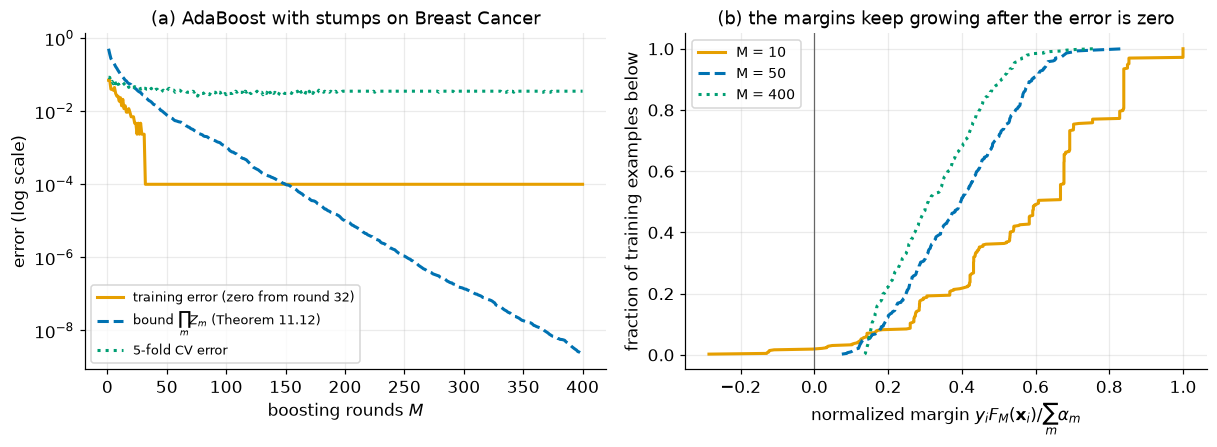

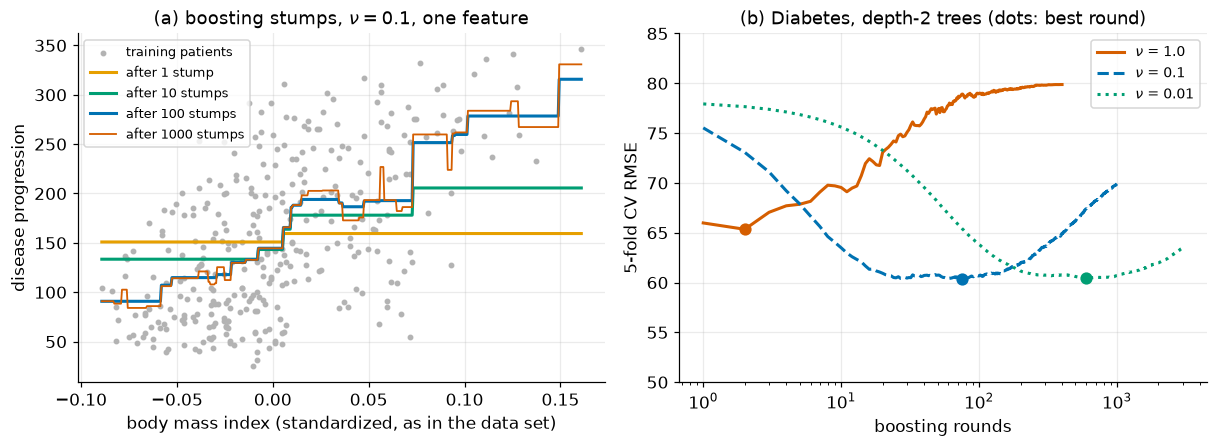

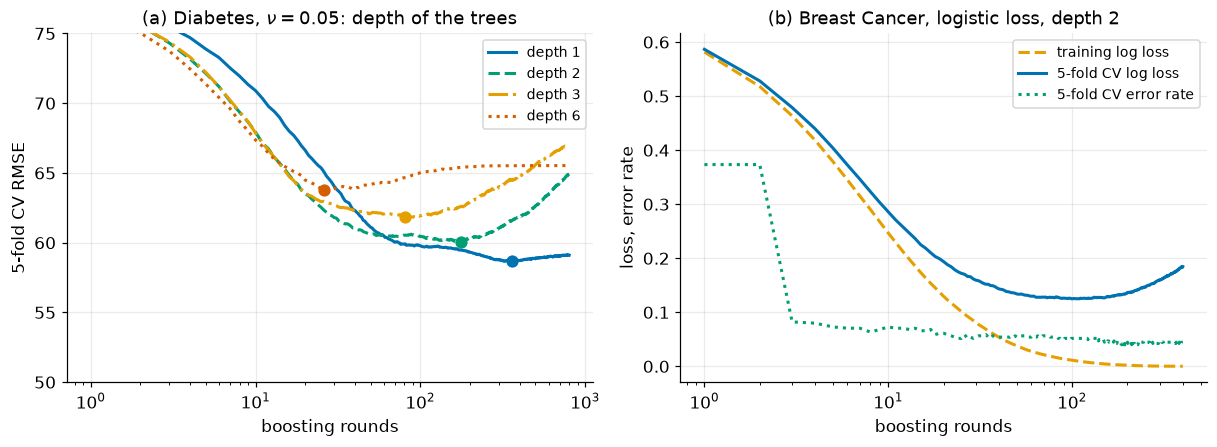

In [32]:
def figure_11_10():
    fig, axes = plt.subplots(1, 2, figsize=(11.2, 4.2))
    ax = axes[0]
    rounds = np.arange(1, M_ada + 1)
    ax.semilogy(rounds, np.maximum(train_err, 1e-4), color=ORANGE, lw=2, label="training error (zero from round " + str(first_zero) + ")")
    ax.semilogy(rounds, bound, color=BLUE, lw=2, ls="--", label=r"bound $\prod_m Z_m$ (Theorem 11.12)")
    ax.semilogy(rounds, cv_err, color=GREEN, lw=2, ls=":", label="5-fold CV error")
    ax.set_xlabel("boosting rounds $M$")
    ax.set_ylabel("error (log scale)")
    ax.set_title("(a) AdaBoost with stumps on Breast Cancer")
    ax.legend(fontsize=8.5, loc="lower left")
    ax = axes[1]
    for M, color, ls in [(10, ORANGE, "-"), (50, BLUE, "--"), (400, GREEN, ":")]:
        marg = np.sort(ypm_tr * F_tr[M - 1] / alphas[:M].sum())
        ax.plot(marg, np.arange(1, len(marg) + 1) / len(marg), color=color, lw=2, ls=ls, label=f"M = {M}")
    ax.axvline(0, color="0.4", lw=0.8)
    ax.set_xlabel(r"normalized margin $y_iF_M(\mathbf{x}_i)/\sum_m\alpha_m$")
    ax.set_ylabel("fraction of training examples below")
    ax.set_title("(b) the margins keep growing after the error is zero")
    ax.legend(fontsize=9)
    fig.tight_layout()
    return fig


figure_11_10()
plt.show()


def figure_11_11():
    fig, axes = plt.subplots(1, 2, figsize=(11.2, 4.2))
    ax = axes[0]
    j = diab_names.index("bmi")
    xg = np.linspace(Xd_tr[:, j].min(), Xd_tr[:, j].max(), 500)
    ax.scatter(Xd_tr[:, j], yd_tr, s=8, color="0.7", label="training patients")
    F = np.full(len(yd_tr), yd_tr.mean())
    Fg = np.full(len(xg), yd_tr.mean())
    show = {1: ORANGE, 10: GREEN, 100: BLUE, 1000: VERMILION}
    for m in range(1, 1001):
        tree = DecisionTreeRegressor(max_depth=1, random_state=SEED).fit(Xd_tr[:, [j]], yd_tr - F)
        F = F + 0.1 * tree.predict(Xd_tr[:, [j]])
        Fg = Fg + 0.1 * tree.predict(xg[:, None])
        if m in show:
            ax.plot(xg, Fg, color=show[m], lw=2 if m < 1000 else 1.2, label=f"after {m} stump{'s' if m > 1 else ''}")
    ax.set_xlabel("body mass index (standardized, as in the data set)")
    ax.set_ylabel("disease progression")
    ax.set_title(r"(a) boosting stumps, $\nu=0.1$, one feature")
    ax.legend(fontsize=8.5, loc="upper left")
    ax = axes[1]
    for nu, color, ls in [(1.0, VERMILION, "-"), (0.1, BLUE, "--"), (0.01, GREEN, ":")]:
        c = nu_curves[nu]
        ax.plot(np.arange(1, len(c) + 1), c, color=color, lw=2, ls=ls, label=rf"$\nu$ = {nu}")
        ax.plot(np.argmin(c) + 1, c.min(), marker="o", color=color, ms=7)
    ax.set_xscale("log")
    ax.set_ylim(50, 85)
    ax.set_xlabel("boosting rounds")
    ax.set_ylabel("5-fold CV RMSE")
    ax.set_title("(b) Diabetes, depth-2 trees (dots: best round)")
    ax.legend(fontsize=9)
    fig.tight_layout()
    return fig


figure_11_11()
plt.show()


def figure_11_12():
    fig, axes = plt.subplots(1, 2, figsize=(11.2, 4.2))
    ax = axes[0]
    for (d, c), color, ls in zip(depth_curves.items(), [BLUE, GREEN, ORANGE, VERMILION], ["-", "--", "-.", ":"]):
        ax.plot(np.arange(1, len(c) + 1), c, color=color, lw=2, ls=ls, label=f"depth {d}")
        ax.plot(np.argmin(c) + 1, c.min(), marker="o", color=color, ms=7)
    ax.set_xscale("log")
    ax.set_ylim(50, 75)
    ax.set_xlabel("boosting rounds")
    ax.set_ylabel("5-fold CV RMSE")
    ax.set_title(r"(a) Diabetes, $\nu=0.05$: depth of the trees")
    ax.legend(fontsize=9)
    ax = axes[1]
    r = np.arange(1, M_gb + 1)
    ax.plot(r, gb_tr_ll, color=ORANGE, lw=2, ls="--", label="training log loss")
    ax.plot(r, gb_va_ll, color=BLUE, lw=2, label="5-fold CV log loss")
    ax.plot(r, gb_va_err, color=GREEN, lw=2, ls=":", label="5-fold CV error rate")
    ax.set_xscale("log")
    ax.set_xlabel("boosting rounds")
    ax.set_ylabel("loss, error rate")
    ax.set_title("(b) Breast Cancer, logistic loss, depth 2")
    ax.legend(fontsize=9)
    fig.tight_layout()
    return fig


figure_11_12()
plt.show()

Figure 11.10 shows the two aspects of AdaBoost on Breast Cancer: in (a) the training error (drawn at $10^{-4}$ when it is zero, since the axis is logarithmic), the bound of Theorem 11.12 and the cross-validated error, which stays flat after round $32$; in (b) the distributions of the normalized margins at three numbers of rounds, which move to the right in their left tail. Figure 11.11(a) boosts stumps on the single feature `bmi`, so that the model is a step function that gains steps as rounds are added: after $1$ stump two levels, after $10$ a rough staircase, after $100$ a finer one, and after $1000$ stumps spikes appear in the sparse region on the right, where a few patients are fitted individually; (b) shows the CV curves for the three learning rates, with dots at the best rounds. Figure 11.12 shows in (a) the CV curves for four depths of trees at $\nu=0.05$ and in (b) the logistic loss and error rate of Section 11.9.5.

## 11.10 Probabilities: what do the ensembles estimate?

A classifier built from trees produces a score, and most applications need a *probability* (Sections 5.6.4 and 8.7.3). The three ensembles of this chapter produce their scores in different ways, and the way fixes how far they can be trusted as probabilities.

- A **random forest** averages the class proportions of its trees. Deep trees have nearly pure leaves, so each tree votes almost $0$ or $1$, and the average is a fraction of votes. A fraction of votes is not a probability: a patient on whom $97\%$ of the trees agree is "very likely", but nothing ties the number $0.97$ to a frequency of $97\%$. The average of many noisy votes tends to stay away from $0$ and $1$, because a few trees always dissent.
- **AdaBoost** estimates *half the log-odds* (Section 11.8.2), so that $\hat p=1/(1+e^{-2F_M(\mathbf{x})})$. The training margins keep growing with the number of rounds (Figure 11.10(b)), and with them $\lvert F_M\rvert$: the probabilities are pushed toward $0$ and $1$, whatever the evidence.
- **Gradient boosting with the logistic loss** targets the log-odds directly (Proposition 8.5), and is well calibrated near the best number of rounds; past it, the overconfidence of Section 11.9.5 sets in.

The experiment uses Breast Cancer, with $10$-fold cross-validated probabilities on the $426$ training patients (the test set stays untouched), and compares a standardized logistic regression, the tree pruned with the one-SE rule, a forest of $500$ trees, AdaBoost with $100$ stumps ($\hat p$ as above) and gradient boosting with $100$ rounds. All probabilities are clipped to $[10^{-4},1-10^{-4}]$ before the log loss is computed, so that one certain mistake does not make it infinite. To correct a miscalibration we fit **Platt scaling** (Section 8.7.3) to the cross-validated scores: a logistic regression of the label on the logit of the probability, two parameters, evaluated by another round of cross-validation; its numbers are slightly optimistic because the scores were already produced by cross-validation, but with two parameters the effect is small.

In [33]:
def clip_p(p, eps=1e-4):
    return np.clip(p, eps, 1 - eps)


def logit(p):
    return np.log(p / (1 - p))


def adaboost_cv_prob(X, y01, M, cv):
    """Cross-validated probabilities of AdaBoost with M stumps: p = 1 / (1 + exp(-2 F_M))."""
    ypm = 2 * y01 - 1
    p = np.zeros(len(y01))
    for tr, va in cv.split(X, y01):
        st, al, _, _ = adaboost_fit(X[tr], ypm[tr], M)
        p[va] = 1 / (1 + np.exp(-2 * adaboost_scores(st, al, X[va])[-1]))
    return p


cal_models = {
    "logistic regression": make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=5000)),
    "pruned tree (one-SE)": DecisionTreeClassifier(ccp_alpha=a_b[i_1se_b], random_state=SEED),
    "random forest (500)": RandomForestClassifier(500, random_state=SEED, n_jobs=2),
    "gradient boosting (100)": GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, max_depth=2, random_state=SEED),
}
t0 = time.perf_counter()
p_raw = {name: cross_val_predict(m, Xb_tr, yb_tr, cv=skf10, method="predict_proba")[:, 1] for name, m in cal_models.items()}
p_raw["AdaBoost, stumps (100)"] = adaboost_cv_prob(Xb_tr, yb_tr, 100, skf10)
cal_order = ["logistic regression", "pruned tree (one-SE)", "random forest (500)", "AdaBoost, stumps (100)", "gradient boosting (100)"]
p_raw = {name: p_raw[name] for name in cal_order}

skf_cal = StratifiedKFold(10, shuffle=True, random_state=SEED + 1)


def platt_cv(p, y):
    s = logit(clip_p(p))[:, None]
    return cross_val_predict(LogisticRegression(C=1e6, max_iter=1000), s, y, cv=skf_cal, method="predict_proba")[:, 1]


p_platt = {name: platt_cv(p, yb_tr) for name, p in p_raw.items()}
rows = []
for name, p in p_raw.items():
    pc, qc = clip_p(p), clip_p(p_platt[name])
    wrong = (pc > 0.5) != yb_tr
    extreme = (pc < 0.01) | (pc > 0.99)
    rows.append({"model": name, "CV accuracy": np.mean(~wrong), "log loss": log_loss(yb_tr, pc), "Brier": brier_score_loss(yb_tr, pc),
                 "log loss, Platt": log_loss(yb_tr, qc), "Brier, Platt": brier_score_loss(yb_tr, qc),
                 "share beyond [0.01, 0.99]": extreme.mean(), "errors among them": int((extreme & wrong).sum())})
cal_tab = pd.DataFrame(rows)
print(cal_tab.to_string(index=False, float_format=lambda v: f"{v:.4f}"))

bins = np.array([0, 0.05, 0.2, 0.4, 0.6, 0.8, 0.95, 1.0])


def reliability(p, y):
    idx = np.digitize(p, bins[1:-1])
    return np.array([(p[idx == b].mean(), y[idx == b].mean(), int((idx == b).sum())) if (idx == b).any() else (np.nan, np.nan, 0) for b in range(len(bins) - 1)])


rel = {name: reliability(clip_p(p), yb_tr) for name, p in p_raw.items()}
print("\nreliability: mean predicted probability / observed frequency of malignant (number of patients) in the bins " + str(bins.tolist()))
for name, r in rel.items():
    print(f"{name:26s}" + "  ".join(f"{a:.2f}/{b:.2f}({int(n)})" if n else "   -   " for a, b, n in r))
print(f"[{time.perf_counter() - t0:.1f} s]")

                  model  CV accuracy  log loss  Brier  log loss, Platt  Brier, Platt  share beyond [0.01, 0.99]  errors among them
    logistic regression       0.9765    0.0836 0.0215           0.0958        0.0218                     0.6925                  1
   pruned tree (one-SE)       0.9249    0.2829 0.0682           0.2679        0.0679                     0.0845                  2
    random forest (500)       0.9554    0.1435 0.0356           0.1397        0.0347                     0.4319                  1
 AdaBoost, stumps (100)       0.9742    0.1453 0.0237           0.0947        0.0232                     0.9624                  6
gradient boosting (100)       0.9577    0.1183 0.0319           0.1219        0.0324                     0.7136                  2

reliability: mean predicted probability / observed frequency of malignant (number of patients) in the bins [0.0, 0.05, 0.2, 0.4, 0.6, 0.8, 0.95, 1.0]
logistic regression       0.01/0.01(224)  0.09/0.06(32)  0.29/0

The logistic regression is the best calibrated of the five: it has the lowest log loss ($0.0836$) and Brier score ($0.0215$), and Platt scaling does not help it ($0.0958$), since a second layer fitted on its own cross-validated scores can only add noise to what is already a model of the log-odds. **AdaBoost** has the accuracy of the logistic regression ($0.9742$, $11$ errors in $426$) but not its probabilities: $96\%$ of its predictions are beyond $[0.01,0.99]$ and *six of those are mistakes*, six patients misclassified with more than $99\%$ confidence, so its log loss is $0.1453$. Platt scaling brings it down to $0.0947$, a reduction of $35\%$, close to the logistic regression's value; its Brier score hardly moves ($0.0237$ to $0.0232$), because the Brier score is bounded and punishes a confident mistake far less than the log loss does. The **forest** is accurate to $0.9554$ ($19$ errors) and its probabilities are not extreme ($43\%$ beyond $[0.01,0.99]$), but its log loss is $0.1435$ and Platt scaling changes it very little ($0.1397$). **Gradient boosting** with $100$ rounds, a number chosen near the minimum of the cross-validated log loss in Section 11.9.5, is calibrated as produced: $0.1183$, and $0.1219$ after the correction. The pruned tree has a few leaves and therefore few distinct probabilities; its log loss $0.2829$ is the worst of the five.

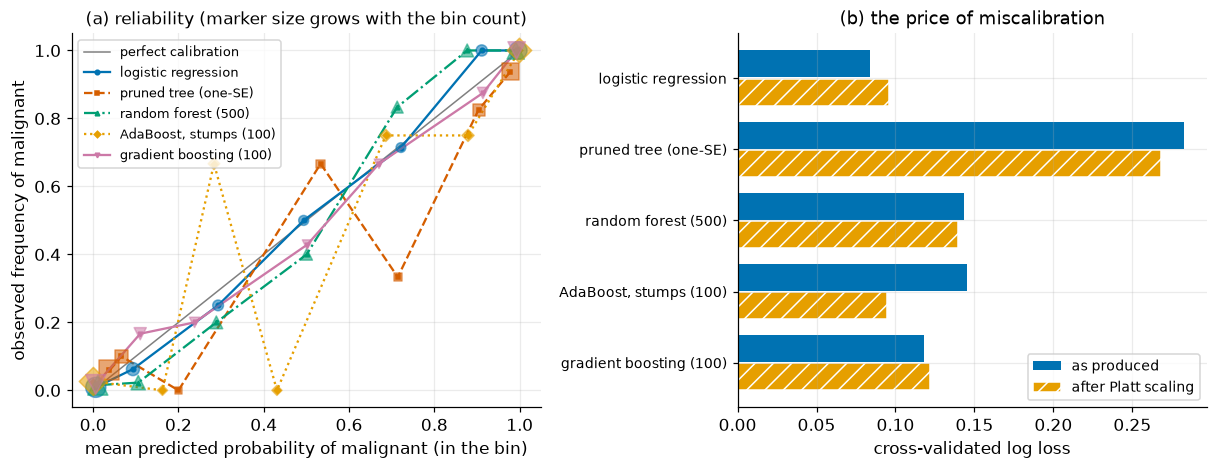

In [34]:
def figure_11_13():
    fig, axes = plt.subplots(1, 2, figsize=(11.2, 4.4))
    ax = axes[0]
    ax.plot([0, 1], [0, 1], color="0.5", lw=1, ls="-", label="perfect calibration")
    style = {"logistic regression": (BLUE, "o", "-"), "pruned tree (one-SE)": (VERMILION, "s", "--"), "random forest (500)": (GREEN, "^", "-."),
             "AdaBoost, stumps (100)": (ORANGE, "D", ":"), "gradient boosting (100)": (PURPLE, "v", "-")}
    for name, r in rel.items():
        color, marker, ls = style[name]
        ok = r[:, 2] > 0
        ax.plot(r[ok, 0], r[ok, 1], color=color, marker=marker, ls=ls, lw=1.5, ms=3, label=name)
        ax.scatter(r[ok, 0], r[ok, 1], s=12 + 160 * np.sqrt(r[ok, 2] / r[:, 2].max()), color=color, marker=marker, alpha=0.55, zorder=3)
    ax.set_xlabel("mean predicted probability of malignant (in the bin)")
    ax.set_ylabel("observed frequency of malignant")
    ax.set_title("(a) reliability (marker size grows with the bin count)", fontsize=11)
    ax.legend(fontsize=8.5, loc="upper left")
    ax = axes[1]
    ypos = np.arange(len(cal_tab))
    ax.barh(ypos - 0.2, cal_tab["log loss"], height=0.38, color=BLUE, label="as produced")
    ax.barh(ypos + 0.2, cal_tab["log loss, Platt"], height=0.38, color=ORANGE, hatch="//", edgecolor="white", label="after Platt scaling")
    ax.set_yticks(ypos)
    ax.set_yticklabels(cal_tab["model"], fontsize=9)
    ax.invert_yaxis()
    ax.set_xlabel("cross-validated log loss")
    ax.set_title("(b) the price of miscalibration")
    ax.legend(fontsize=9, loc="lower right")
    fig.tight_layout()
    return fig


figure_11_13()
plt.show()

In the reliability curves (Figure 11.13(a)) most patients sit in the two end bins, where all the curves agree ($269$ of the $426$ patients get a probability below $0.05$ from AdaBoost), and the bins in the middle contain between $1$ and $25$ patients: the zigzag of the AdaBoost and tree curves is mostly noise from bins of one to four patients, which is why the marker areas grow with the counts. With $426$ patients a reliability diagram can show a gross miscalibration and cannot resolve a small one. What it does show is consistent with the table: the forest lies *under* the diagonal in the low bins (a mean prediction of $0.11$ for an observed frequency of $0.02$) and *above* it in the high bins ($0.88$ against $1.00$), the shrinkage toward $0.5$ of an average of votes, and AdaBoost puts $269$ patients at $0.00$ on average, among which $3\%$ are malignant.

Three practical rules follow. If the probabilities are used, they are judged by the log loss or the Brier score on held-out data, not by the accuracy, since models with the same accuracy differ in the log loss by almost a factor of two. The scores of AdaBoost and of a forest should be recalibrated before they are interpreted as probabilities, by a sigmoid (Platt, with few data) or an isotonic regression (with more data), for example with `CalibratedClassifierCV`, which does the cross-validation internally. Gradient boosting with the logistic loss and early stopping on the log loss gives usable probabilities directly, and a model that must be trusted in its probabilities, rather than in its class, is better served by that criterion than by the error rate.

## 11.11 Putting the families side by side

Chapters 6 to 11 have produced five kinds of model for the same three problems: linear models, kernel machines, nearest neighbors, single trees and ensembles of trees. The last experiment of the chapter brings them together on the three data sets with the splits used throughout (Diabetes $331/111$, Breast Cancer $426/143$, Digits $1347/450$). Every hyperparameter is chosen by cross-validation, or by the internal validation of the method, on the *training* set only, with the choices made in Sections 11.4, 11.8 and 11.9 (the pruning level, the number of rounds), and the test set is used **once**, to produce the numbers below. With so few test patients the standard errors are large (a binomial standard error for the error rates, a bootstrap over the test patients for the RMSE), and the point of the experiment is the pattern, not the order of two neighbors.

In [35]:
def boot_rmse_se(err, reps=2000):
    rg = np.random.default_rng(SEED)
    return float(np.std([np.sqrt(np.mean(err[rg.integers(0, len(err), len(err))] ** 2)) for _ in range(reps)], ddof=1))


t0 = time.perf_counter()
# ---- Diabetes (RMSE on the 111 test patients)
ridge_d = RidgeCV(alphas=np.logspace(-3, 2, 60), cv=kf10).fit(Xd_tr, yd_tr)
models_d = [
    ("least squares", "linear", LinearRegression()),
    ("ridge", "linear", ridge_d),
    ("pruned tree", "tree", DecisionTreeRegressor(ccp_alpha=a_grid[i_min_d], random_state=SEED)),
    ("random forest (500)", "forest", RandomForestRegressor(500, max_features=1 / 3, min_samples_leaf=5, random_state=SEED, n_jobs=2)),
    ("boosting, stumps", "boosting", GradientBoostingRegressor(n_estimators=int(np.argmin(depth_curves[1])) + 1, learning_rate=0.05, max_depth=1, random_state=SEED)),
    ("boosting, depth 2", "boosting", GradientBoostingRegressor(n_estimators=int(np.argmin(depth_curves[2])) + 1, learning_rate=0.05, max_depth=2, random_state=SEED)),
]
res_d = []
for name, fam, m in models_d:
    m = m if name == "ridge" else m.fit(Xd_tr, yd_tr)
    e = m.predict(Xd_te) - yd_te
    res_d.append({"model": name, "family": fam, "test RMSE": float(np.sqrt(np.mean(e ** 2))), "SE": boot_rmse_se(e)})
res_d = pd.DataFrame(res_d)
print(f"Diabetes, test RMSE ({len(yd_te)} patients); ridge penalty {ridge_d.alpha_:.3g}; boosting rounds {int(np.argmin(depth_curves[1])) + 1} (stumps) and {int(np.argmin(depth_curves[2])) + 1} (depth 2)")
print(res_d.drop(columns="family").to_string(index=False, float_format=lambda v: f"{v:.2f}"))

# ---- Breast Cancer (accuracy on the 143 test patients)
M_ab = int(np.argmin(cv_err)) + 1
M_gb_best = int(np.argmin(gb_va_ll)) + 1
logit_b = GridSearchCV(make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)), {"logisticregression__C": np.logspace(-3, 2, 20)}, cv=skf10, scoring="neg_log_loss").fit(Xb_tr, yb_tr)
svm_b = GridSearchCV(make_pipeline(StandardScaler(), SVC()), {"svc__C": 10.0 ** np.arange(-1, 4), "svc__gamma": 10.0 ** np.arange(-4, 0)}, cv=skf10, scoring="accuracy").fit(Xb_tr, yb_tr)
stumps_b, alphas_b, _, _ = adaboost_fit(Xb_tr, 2 * yb_tr - 1, M_ab)
F_te = adaboost_scores(stumps_b, alphas_b, Xb_te)[-1]
cls_b = [
    ("logistic regression", "linear", logit_b.predict(Xb_te), logit_b.predict_proba(Xb_te)[:, 1]),
    ("Gaussian SVM", "kernel", svm_b.predict(Xb_te), None),
]
for name, fam, m in [("pruned tree (one-SE)", "tree", DecisionTreeClassifier(ccp_alpha=a_b[i_1se_b], random_state=SEED)),
                     ("random forest (500)", "forest", RandomForestClassifier(500, random_state=SEED, n_jobs=2)),
                     (f"gradient boosting ({M_gb_best})", "boosting", GradientBoostingClassifier(n_estimators=M_gb_best, learning_rate=0.1, max_depth=2, random_state=SEED))]:
    m.fit(Xb_tr, yb_tr)
    cls_b.append((name, fam, m.predict(Xb_te), m.predict_proba(Xb_te)[:, 1]))
cls_b.append((f"AdaBoost, stumps ({M_ab})", "boosting", (F_te > 0).astype(int), 1 / (1 + np.exp(-2 * F_te))))
res_b = pd.DataFrame([{"model": n, "family": f, "errors": int((p != yb_te).sum()), "test error rate": float(np.mean(p != yb_te)),
                       "SE": float(np.sqrt(np.mean(p != yb_te) * (1 - np.mean(p != yb_te)) / len(yb_te))),
                       "test log loss": log_loss(yb_te, clip_p(q)) if q is not None else np.nan} for n, f, p, q in cls_b])
print(f"\nBreast Cancer, test set ({len(yb_te)} patients); SVM: C = {svm_b.best_params_['svc__C']:g}, gamma = {svm_b.best_params_['svc__gamma']:g}; logistic C = {logit_b.best_params_['logisticregression__C']:.3g}")
print(res_b.drop(columns="family").to_string(index=False, float_format=lambda v: f"{v:.4f}"))

# ---- Digits (accuracy on the 450 test images)
A_tr, A_te = Xg_tr / 16, Xg_te / 16
cv5s = StratifiedKFold(5, shuffle=True, random_state=SEED)
svm_g = GridSearchCV(SVC(), {"C": 10.0 ** np.arange(-1, 4), "gamma": 10.0 ** np.arange(-4, 0)}, cv=cv5s, scoring="accuracy").fit(A_tr, yg_tr)
knn_g = GridSearchCV(KNeighborsClassifier(), {"n_neighbors": [1, 3, 5, 7, 9]}, cv=cv5s, scoring="accuracy").fit(A_tr, yg_tr)
tree_g = GridSearchCV(DecisionTreeClassifier(random_state=SEED), {"ccp_alpha": [0, 0.001, 0.002, 0.004, 0.008, 0.016]}, cv=cv5s, scoring="accuracy").fit(Xg_tr, yg_tr)
logit_g = make_pipeline(StandardScaler(), LogisticRegression(C=3.16, max_iter=5000)).fit(Xg_tr, yg_tr)
forest_g = RandomForestClassifier(500, random_state=SEED, n_jobs=2).fit(Xg_tr, yg_tr)
hgb_g = HistGradientBoostingClassifier(learning_rate=0.1, max_iter=300, early_stopping=True, validation_fraction=0.15, n_iter_no_change=15, random_state=SEED).fit(Xg_tr, yg_tr)
cls_g = [("logistic regression", "linear", logit_g.predict(Xg_te)), ("Gaussian SVM", "kernel", svm_g.predict(A_te)),
         ("k-NN", "kernel", knn_g.predict(A_te)), ("pruned tree", "tree", tree_g.predict(Xg_te)),
         ("random forest (500)", "forest", forest_g.predict(Xg_te)), ("histogram boosting", "boosting", hgb_g.predict(Xg_te))]
res_g = pd.DataFrame([{"model": n, "family": f, "errors": int((p != yg_te).sum()), "test error rate": float(np.mean(p != yg_te)),
                       "SE": float(np.sqrt(np.mean(p != yg_te) * (1 - np.mean(p != yg_te)) / len(yg_te)))} for n, f, p in cls_g])
print(f"\nDigits, test set ({len(yg_te)} images); SVM: C = {svm_g.best_params_['C']:g}, gamma = {svm_g.best_params_['gamma']:g}; k = {knn_g.best_params_['n_neighbors']}; "
      f"tree alpha = {tree_g.best_params_['ccp_alpha']:g} ({tree_g.best_estimator_.get_n_leaves()} leaves); boosting stopped after {hgb_g.n_iter_} rounds")
print(res_g.drop(columns="family").to_string(index=False, float_format=lambda v: f"{v:.4f}"))
print(f"[{time.perf_counter() - t0:.1f} s]")

Diabetes, test RMSE (111 patients); ridge penalty 0.0602; boosting rounds 360 (stumps) and 177 (depth 2)
              model  test RMSE   SE
      least squares      53.37 3.65
              ridge      53.08 3.52
        pruned tree      59.55 3.66
random forest (500)      52.61 3.35
   boosting, stumps      52.86 3.52
  boosting, depth 2      55.37 3.88



Breast Cancer, test set (143 patients); SVM: C = 10, gamma = 0.01; logistic C = 0.785
                  model  errors  test error rate     SE  test log loss
    logistic regression       5           0.0350 0.0154         0.0748
           Gaussian SVM       3           0.0210 0.0120            NaN
   pruned tree (one-SE)      14           0.0979 0.0249         0.3458
    random forest (500)       5           0.0350 0.0154         0.1089
gradient boosting (100)       5           0.0350 0.0154         0.0972
  AdaBoost, stumps (76)       3           0.0210 0.0120         0.1432



Digits, test set (450 images); SVM: C = 10, gamma = 0.1; k = 3; tree alpha = 0.001 (105 leaves); boosting stopped after 96 rounds
              model  errors  test error rate     SE
logistic regression      12           0.0267 0.0076
       Gaussian SVM       4           0.0089 0.0044
               k-NN       7           0.0156 0.0058
        pruned tree      80           0.1778 0.0180
random forest (500)      13           0.0289 0.0079
 histogram boosting      17           0.0378 0.0090
[8.6 s]


**Diabetes.** All the methods except the single tree are within one standard error of each other: ridge $53.08$, least squares $53.37$, the forest $52.61$, boosted stumps $52.86$ and boosted depth-$2$ trees $55.37$, with standard errors of about $3.5$ on only $111$ test patients. The order of the first four is noise. The pruned tree ($59.55$) is the exception, and the depth-$2$ boosting is behind the stumps by $2.5$, in the direction of the cross-validation of Section 11.9.4.

**Breast Cancer.** The Gaussian SVM and AdaBoost make $3$ errors on the $143$ test patients, the logistic regression, the forest and gradient boosting $5$, the pruned tree $14$ ($0.098$, with a standard error of $0.025$). The difference between $3$ and $5$ errors is a difference of two patients, with standard errors of $0.012$ to $0.015$ on the error rates, and it cannot be read as an order. The tree is the one method that is clearly behind, by about $2.5$ standard errors. The test log loss (logistic regression $0.0748$, gradient boosting $0.0972$, forest $0.1089$, AdaBoost $0.1432$, tree $0.3458$) repeats the lesson of Section 11.10: AdaBoost has the error rate of the best method and the log loss of the fourth.

**Digits.** The order is clearer here. The Gaussian SVM makes $4$ errors in $450$ ($0.0089$), $k$-NN $7$, the logistic regression $12$, the forest $13$, histogram boosting $17$ and the pruned tree $80$ ($0.178$). The SVM is ahead of the two ensembles by $9$ and $13$ images, about two standard errors, while $k$-NN, the logistic regression and the forest cannot be told apart. (The finer grid of Chapter 9 gave $5$ errors for the Gaussian SVM; the grid here is coarser and picks a different $\gamma$, and the difference of one image is not meaningful.) A plausible reading is the inductive bias of Section 11.5: a kernel or a neighbor compares whole images, and a tree splits one pixel at a time, an awkward way to describe a shape; this is a hypothesis consistent with the numbers, not something the experiment isolates.

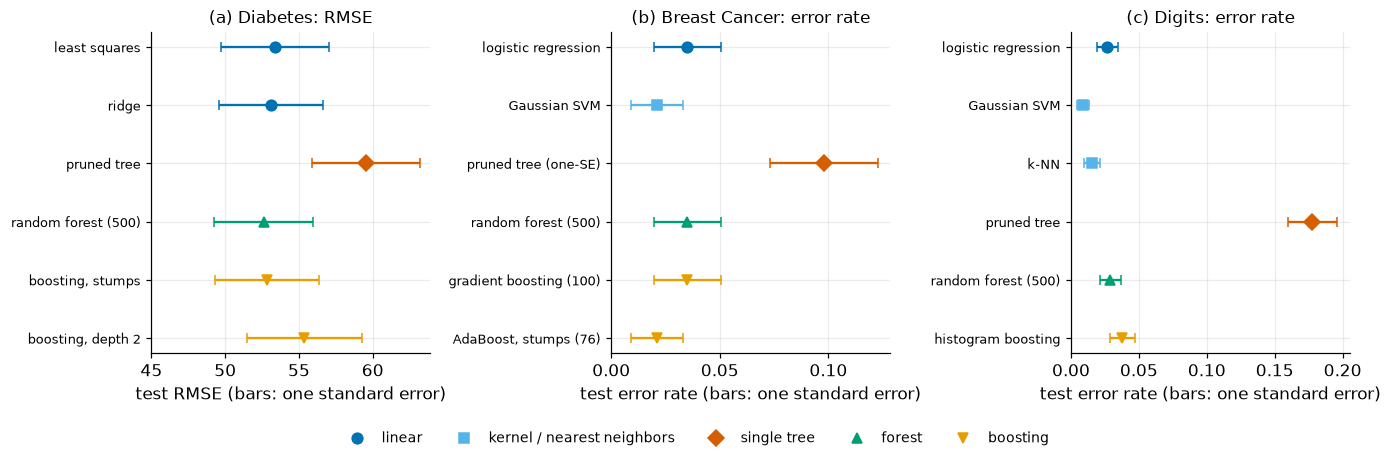

In [36]:
def figure_11_14():
    fam_style = {"linear": (BLUE, "o", "linear"), "kernel": (SKY, "s", "kernel / nearest neighbors"), "tree": (VERMILION, "D", "single tree"),
                 "forest": (GREEN, "^", "forest"), "boosting": (ORANGE, "v", "boosting")}
    fig, axes = plt.subplots(1, 3, figsize=(12.6, 4.2))
    panels = [(res_d, "test RMSE", "(a) Diabetes: RMSE"), (res_b, "test error rate", "(b) Breast Cancer: error rate"), (res_g, "test error rate", "(c) Digits: error rate")]
    for ax, (df, col, title) in zip(axes, panels):
        for i, row in df.reset_index(drop=True).iterrows():
            color, marker, _ = fam_style[row["family"]]
            ax.errorbar(row[col], i, xerr=row["SE"], fmt=marker, color=color, ms=7, capsize=3, lw=1.5)
        ax.set_yticks(range(len(df)))
        ax.set_yticklabels(df["model"], fontsize=8.5)
        ax.invert_yaxis()
        ax.set_xlabel(col + " (bars: one standard error)")
        ax.set_title(title, fontsize=11)
        ax.set_xlim(left=45 if col == "test RMSE" else 0)
    handles = [plt.Line2D([], [], color=c, marker=m, ls="", ms=7, label=l) for c, m, l in fam_style.values()]
    fig.legend(handles=handles, loc="lower center", ncol=5, fontsize=9, frameon=False)
    fig.tight_layout(rect=(0, 0.07, 1, 1))
    return fig


figure_11_14()
plt.show()

Figure 11.14 shows the test results with one standard error (the axis of panel (a) starts at $45$ to make the differences visible). Three conclusions, with the caveat that the three data sets are small and the standard errors large. **A single tree is rarely the final model**: it is behind every other family on all three problems, by $2.5$ standard errors or more on the classification problems, and what makes it useful is that it is the building block of the others. **Ensembles of trees close the gap to the linear and kernel models without passing them** on these data: on Diabetes and Breast Cancer, where the signal is close to linear (Chapters 4 and 6), a forest or boosted stumps match ridge and the logistic regression, and on Digits the kernel methods are ahead. There is no free lunch, and a forest is a strong default for an unknown relationship, not a replacement for a linear model that already fits. **The conditions that favor trees are not in these data sets**: mixed numerical and categorical features, features on arbitrary scales, missing values, strong interactions and a large number of examples. Benchmarks on larger tabular data (Grinsztajn, Oyallon and Varoquaux, 2022, in the further reading) report tree ensembles ahead of neural networks on medium-sized problems of this kind, which is a reason to try them first on such data, and a reason to measure rather than assume on yours.

## 11.12 Summary

- **Regression trees (Section 11.2).** A tree is a partition of the feature space into boxes with one constant per box. The best constant in a box is the mean (Proposition 11.1), and the gain of a split is $\frac{n_Ln_R}{n}(\bar y_L-\bar y_R)^2$ (Proposition 11.2); after sorting, all thresholds of a feature are scored in $O(n)$ and a tree of depth $D$ costs $O(Dpn\log n)$ (Proposition 11.3). In the worked example the threshold $3.5$ gains $66.67$ of the root's $69.33$. On Diabetes the training error falls to zero for a tree with $324$ leaves for $331$ patients, and its test RMSE of $77.1$ is **worse than the constant $74.88$**; the best shallow tree reaches $59.3$ against $53.37$ for least squares.
- **Classification trees (Section 11.3).** Concave impurities never increase at a split (Proposition 11.4), and the Gini index is the squared error of the one-hot targets (Proposition 11.5), so that a Gini tree is a regression tree for one-hot targets. The root of the Breast Cancer tree is the worst perimeter at $112.8$ (gain $0.3369$), and $n$ times this gain equals the sum of the squared-error gains to all printed digits. The runners-up, the worst radius ($0.3330$) and the worst area ($0.3254$), are nearly as good: the choice is fragile.
- **Pruning (Section 11.4).** The weakest-link criterion $g(t)=(R(t)-R(T_t))/(\lvert T_t\rvert-1)$ generates a nested sequence of optimal subtrees (Proposition 11.6), computed in one pass and checked against scikit-learn; $\alpha$ is chosen by cross-validation, with the one-SE rule as an option. On Diabetes pruning takes the cross-validated RMSE from $80.58$ for the full tree to $65.31$. The pruned Breast Cancer tree has $9$ splits on $7$ of the $30$ features and can be read as a list of rules, which is the main reason trees are used alone.
- **Inductive bias (Section 11.5).** A tree is invariant to monotone transformations of each feature (Proposition 11.7); it is a $k$-NN rule with adaptive neighborhoods (mean squared error $0.0101$ against $0.0226$ for $k$-NN on a step, $0.0408$ against $0.0175$ on a sine); it handles irrelevant features better than $k$-NN (with $1000$ noise columns it loses $0.019$ of accuracy, the logistic regression $0.059$ and $5$-NN $0.142$) but is not the best of the three at any noise level; its boundaries are axis-aligned (on a diagonal boundary $0.881$ against $0.933$ for the logistic regression, with no effect of rotation on the real data); and it is unstable: the root is the worst perimeter in $115$ of $200$ bootstrap samples, and the test accuracy of $40$ trees ranges from $0.874$ to $0.965$.
- **Bagging and random forests (Section 11.6).** The variance of an average of $B$ predictors with variance $\sigma^2$ and correlation $\rho$ is $\rho\sigma^2+(1-\rho)\sigma^2/B$ (Proposition 11.8), which the experiment confirms to within $2.5\%$: bagging has $\rho=0.112$, the forest ($m_{\text{try}}=p/3$) $\rho=0.061$ with a larger $\sigma^2$, and the variance of the average of $100$ trees is $405$ against $258$. A bootstrap sample holds $63.2\%$ of the distinct examples (Proposition 11.9), and the OOB examples give a free validation estimate; more trees can only help in expectation (Proposition 11.10), and the other hyperparameters matter little (a range of $0.85$ RMSE units in the OOB grid). Bagging helps in proportion to the instability of its base predictor (full tree $80.58\to59.32$, forest $58.08$; least squares $56.07\to56.16$), and the forest is the most robust method to noise columns, losing $0.013$ of accuracy at $m=1000$.
- **Importances (Section 11.7).** The impurity importance is computed on the training data and favors columns with many distinct values (three noise columns receive $0.0055$ in all); the permutation importance on held-out data is centered on zero for noise, but is noisy, with a resolution of one patient in $107$. Correlated features share the credit: with a copy of the top feature the MDI of $0.303$ splits into $0.149$ and $0.154$, the permutation importance of $0.0262$ becomes $-0.0106$ for each copy, and the six correlated size features permuted together cost $0.148$ of accuracy against $0.0145$ for the best of them alone. Selecting features on importances outside the cross-validation loop gives an accuracy of $0.710$ on pure noise, and $0.518$ inside it.
- **AdaBoost (Section 11.8).** The algorithm is the stagewise minimization of the exponential loss (Proposition 11.11), and its training error is at most $\prod_mZ_m\le\exp(-2\sum_m\gamma_m^2)$ (Theorem 11.12), checked on $400$ rounds of stumps on Breast Cancer (identity to $2\cdot10^{-15}$). The training error is zero from round $32$, the cross-validated error has its minimum, $0.0259$, at round $76$ and does not rise afterwards, and the smallest normalized margin grows from $-0.286$ to $+0.136$. AdaBoost estimates half the log-odds, so that its probabilities are $1/(1+e^{-2F})$.
- **Gradient boosting (Section 11.9).** Boosting is gradient descent in the space of fitted values with the gradient projected on trees (Proposition 11.13); the learning rate and the number of rounds regularize it, as in Chapter 7. Our code reproduces scikit-learn's to $10^{-13}$ for $20$ rounds and then diverges at an exact tie between two features at a node of three patients (Section 11.3.2 again). The Newton leaf $-G_j/(Q_j+\lambda)$ and the gain (11.5) (Proposition 11.14) match `HistGradientBoostingRegressor` to four decimals. On Diabetes a small $\nu$ makes the number of rounds a less delicate choice ($60.32$ at $\nu=0.1$ and $60.46$ at $0.01$, against $65.34$ at $\nu=1$), stumps are the best base learner ($58.66$ against $63.77$ for depth $6$), and boosting beats bagging for stumps ($58.66$ against $64.45$) while bagging beats boosting for deep trees ($60.41$ against $63.77$). With the logistic loss the cross-validated log loss has its minimum, $0.1251$, at round $100$ and rises to $0.1844$ at round $400$ while the error rate stays flat.
- **Probabilities (Section 11.10).** The logistic regression has the best log loss ($0.0836$). AdaBoost has an accuracy of $0.9742$ and a log loss of $0.1453$, with six errors made at more than $99\%$ confidence, and Platt scaling brings it to $0.0947$; the forest shrinks toward $0.5$ and gains little from recalibration; gradient boosting stopped at the best log loss is calibrated as produced.
- **The families side by side (Section 11.11).** On the test sets, all methods but the single tree are within one standard error on Diabetes ($52.61$ to $55.37$ against $59.55$ for the pruned tree); on Breast Cancer the SVM and AdaBoost make $3$ errors, the logistic regression, the forest and boosting $5$, and the pruned tree $14$; on Digits the SVM makes $4$ errors, $k$-NN $7$, the logistic regression $12$, the forest $13$, boosting $17$ and the pruned tree $80$. Ensembles close the gap to linear and kernel models without passing them on these data.

:::{admonition} Which tool for which situation
:class: tip
| situation | start with | reason |
|---|---|---|
| tabular data, unknown relationship, little time to tune | random forest with the defaults | few sensitive hyperparameters, free OOB error, robust to noise columns (Section 11.6) |
| tabular data, best accuracy, time to tune | histogram-based gradient boosting, small learning rate, rounds by early stopping | boosting reduces the bias that forests keep (Section 11.9.4) |
| a short, readable rule set is required | one tree pruned by cross-validation (one-SE rule) | readable, but expect an error well above that of an ensemble (Sections 11.4 and 11.11) |
| the relationship is close to linear | a regularized linear model first | trees approximate a slope by steps (Sections 11.5.2 and 11.11) |
| probabilities are used | boosting with the logistic loss, rounds chosen on the log loss; recalibrate the scores of a forest or of AdaBoost | Section 11.10 |
| which features matter | permutation importance on held-out data, correlated groups permuted together | Sections 11.7.1 and 11.7.2 |
| selecting features with importances | inside the cross-validation loop, in the pipeline | Section 11.7.3 |
:::

### Data sources

- *Diabetes*: B. Efron, T. Hastie, I. Johnstone and R. Tibshirani, "Least Angle Regression", *Annals of Statistics* 32(2), 407–499 (2004). Bundled with scikit-learn. The 331/111 split of Chapters 6, 7, 9 and 10.
- *Breast Cancer Wisconsin (Diagnostic)*: W. N. Street, W. H. Wolberg and O. L. Mangasarian, "Nuclear feature extraction for breast tumor diagnosis", *IS&T/SPIE 1993 International Symposium on Electronic Imaging: Science and Technology*, volume 1905, 861–870 (1993). Bundled with scikit-learn. Malignant $=1$; the stratified 426/143 split of Chapters 6 to 10.
- *Digits*: E. Alpaydin and C. Kaynak, "Optical Recognition of Handwritten Digits", UCI Machine Learning Repository (1998). Bundled with scikit-learn; all ten classes, the stratified $1347/450$ split of Chapters 6 and 9 (Section 11.11).
- *Wine*: M. Forina *et al.*, "PARVUS: An Extendible Package for Data Exploration, Classification and Correlation", Institute of Pharmaceutical and Food Analysis and Technologies, Genoa (1991), UCI Machine Learning Repository. Bundled with scikit-learn (Exercise 11.6).
- *Constructed and simulated data* (flagged in the text): the six-point worked example of Section 11.2.3; the step and sine functions with Gaussian noise of Section 11.5.2; the noise columns appended to real features (Sections 11.5.3, 11.6.7, 11.7 and Exercises 11.10); the diagonal boundary with flipped labels of Section 11.5.4; the resampling experiment of Section 11.6.4, which draws training sets from the real Diabetes patients; the shuffled-label noise problem of Section 11.7.3; and the small numerical examples of Exercises 11.1 to 11.5.

### Further reading

- L. Breiman, J. H. Friedman, R. A. Olshen and C. J. Stone, *Classification and Regression Trees*, Wadsworth, 1984. The origin of trees as used here: greedy splitting, impurities, cost-complexity pruning (Section 11.4) and cross-validated choice of the subtree.
- J. R. Quinlan, "Induction of decision trees", *Machine Learning* 1(1), 81–106 (1986), and *C4.5: Programs for Machine Learning*, Morgan Kaufmann, 1993. The entropy-based line of algorithms, developed in parallel in machine learning.
- L. Breiman, "Bagging predictors", *Machine Learning* 24(2), 123–140 (1996), and "Random forests", *Machine Learning* 45(1), 5–32 (2001). Bagging, random forests, the out-of-bag error and the permutation importance (Sections 11.6 and 11.7).
- T. G. Dietterich, "An experimental comparison of three methods for constructing ensembles of decision trees: bagging, boosting, and randomization", *Machine Learning* 40(2), 139–157 (2000), and P. Geurts, D. Ernst and L. Wehenkel, "Extremely randomized trees", *Machine Learning* 63(1), 3–42 (2006) (Exercise 11.8).
- Y. Freund and R. E. Schapire, "A decision-theoretic generalization of on-line learning and an application to boosting", *Journal of Computer and System Sciences* 55(1), 119–139 (1997). AdaBoost and the bound of Theorem 11.12.
- R. E. Schapire, Y. Freund, P. Bartlett and W. S. Lee, "Boosting the margin: a new explanation for the effectiveness of voting methods", *Annals of Statistics* 26(5), 1651–1686 (1998), and L. Breiman, "Prediction games and arcing algorithms", *Neural Computation* 11(7), 1493–1517 (1999). The margin explanation and the objections to it, with the behavior seen in Section 11.8.3. R. E. Schapire and Y. Freund, *Boosting: Foundations and Algorithms*, MIT Press, 2012, for the whole theory.
- J. Friedman, T. Hastie and R. Tibshirani, "Additive logistic regression: a statistical view of boosting", *Annals of Statistics* 28(2), 337–407 (2000). AdaBoost as stagewise minimization of the exponential loss, the log-odds it estimates and the Gentle AdaBoost of Exercise 11.5.
- J. H. Friedman, "Greedy function approximation: a gradient boosting machine", *Annals of Statistics* 29(5), 1189–1232 (2001), and "Stochastic gradient boosting", *Computational Statistics & Data Analysis* 38(4), 367–378 (2002). Sections 11.9.1 and 11.9.4.
- T. Chen and C. Guestrin, "XGBoost: a scalable tree boosting system", *Proceedings of KDD 2016*, 785–794, and G. Ke *et al.*, "LightGBM: a highly efficient gradient boosting decision tree", *Advances in Neural Information Processing Systems* 30 (2017). The regularized second-order objective of Proposition 11.14 and the histogram algorithms.
- A. Niculescu-Mizil and R. Caruana, "Predicting good probabilities with supervised learning", *Proceedings of ICML 2005*, 625–632. The calibration of forests, boosting and other classifiers (Section 11.10).
- C. Strobl, A.-L. Boulesteix, A. Zeileis and T. Hothorn, "Bias in random forest variable importance measures: illustrations, sources and a solution", *BMC Bioinformatics* 8, 25 (2007). The bias of the impurity importance toward columns with many distinct values (Section 11.7.1).
- L. Grinsztajn, E. Oyallon and G. Varoquaux, "Why do tree-based models still outperform deep learning on typical tabular data?", *Advances in Neural Information Processing Systems* 35, Datasets and Benchmarks Track (2022). A benchmark on tabular data (Section 11.11).
- T. Hastie, R. Tibshirani and J. Friedman, *The Elements of Statistical Learning*, 2nd edition, Springer, 2009 (free online), Chapters 9, 10, 15 and 16. The standard reference for the whole chapter.

## 11.13 Exercises

Difficulty: ★ warm-up, ★★ core, ★★★ challenge. Try each exercise before reading the hint; solutions and detailed outlines are in [Appendix C](../appendices/appendix_c_solutions.ipynb).

### Manual (analytical) exercises

**Exercise 11.1 ★ — A tree and its pruning by hand.** (Constructed numbers.) One feature and eight points: $x=(1,2,3,4,5,6,7,8)$ and $y=(3,1,2,9,11,10,4,5)$. (a) Find the first split of a regression tree and its gain by Proposition 11.2, and check it against the residual sums of squares. (b) Grow the tree greedily to depth $2$ (a split in each child of the root, with the best threshold in each) and write its four leaf values and its training RSS. (c) For this tree compute $g(t)$ for each internal node, prune the weakest link, recompute the values of $g$ for the pruned tree and continue until only the root is left: list the nested subtrees and the values of $\alpha$ at which they change.

*Hint.* The gain of a threshold is $\frac{n_Ln_R}{n}(\bar y_L-\bar y_R)^2$. The criterion is $g(t)=\big(R(t)-R(T_t)\big)/(\lvert T_t\rvert-1)$, with $R(t)$ the RSS of the node taken as a leaf and $R(T_t)$ the total RSS of the leaves of its subtree. The values of $g$ change after a pruning, because the subtrees change.

**Exercise 11.2 ★★ — The Gini gain in closed form.** For two classes with proportion $p$ of class $1$ in a node, the Gini index is $2p(1-p)$. (a) Show that a split of a node of $n$ examples into children of sizes $n_L,n_R$ and proportions $p_L,p_R$ has Gini gain $2\,\frac{n_Ln_R}{n^2}(p_L-p_R)^2$. (b) Compute it for a node with $50$ examples of class $0$ and $10$ of class $1$ that is split into $(25,0)$ and $(25,10)$. (c) For the same split compute the gain in misclassification rate; why does a tree grown with the misclassification rate have trouble choosing it, and what does Proposition 11.4 say about the Gini index here?

*Hint.* (a) The weighted average of $p_L$ and $p_R$ is $p$, so $p(1-p)=p-p^2$ and the gain is $2\big[\frac{n_L}{n}p_L^2+\frac{n_R}{n}p_R^2-p^2\big]$, a variance. (c) Compare the errors of the parent and of the children when the majority class does not change.

**Exercise 11.3 ★★ — How many trees?** Use Proposition 11.8. (a) For $\rho=0.3$, how many trees $B$ make the variance of the average at most $5\%$ above its floor $\rho\sigma^2$? Give the general formula as a function of $\rho$. (b) With the values of Section 11.6.4 (bagging: $\rho\sigma^2=380$ and $\sigma^2=3382$; forest: $\rho\sigma^2=229$ and $\sigma^2=3736$), find the number of trees from which the forest has the smaller variance, and explain why it has the larger variance for $B=1$. (c) Show that the variance of the average of $B$ trees is a decreasing function of $B$ and that no choice of $B$ can compensate for a large $\rho$.

*Hint.* (a) The excess over the floor is $(1-\rho)\sigma^2/B$; require it to be at most $0.05\,\rho\sigma^2$. (b) Set the two expressions of (11.2) equal and solve for $B$.

**Exercise 11.4 ★★ — The weak learner is useless in the next round.** (a) Show that, under the updated weights $w_i^{(m+1)}$ of AdaBoost, the weighted error of $h_m$ is exactly $\frac12$. (b) Check it on five points with initial weights $0.2$ where $h_m$ errs on one of them: compute $\varepsilon_m$, $\alpha_m$, $Z_m$ and the new weights. (c) Explain in a sentence what (a) implies for the choice of the next learner.

*Hint.* (a) The misclassified examples have total weight $\varepsilon_me^{\alpha_m}/Z_m$ after the update, with $e^{\alpha_m}=\sqrt{(1-\varepsilon_m)/\varepsilon_m}$ and $Z_m=2\sqrt{\varepsilon_m(1-\varepsilon_m)}$ (Proposition 11.11).

**Exercise 11.5 ★★★ — AdaBoost is gradient boosting for the exponential loss.** Let $\ell(y,F)=e^{-yF}$ with $y\in\{-1,+1\}$ and let $w_i$ be the normalized AdaBoost weights $w_i\propto e^{-y_iF_{m-1}(\mathbf{x}_i)}$, with $W=\sum_ie^{-y_iF_{m-1}(\mathbf{x}_i)}$. (a) Show that the pseudo-residuals are $r_i=Wy_iw_i$. (b) Show that for a classifier $h$ with values in $\{-1,+1\}$ and weighted error $\varepsilon$, $\sum_ir_ih(\mathbf{x}_i)=W(1-2\varepsilon)$, so that the classifier most correlated with the pseudo-residuals is the one of least weighted error. (c) Show that the line search $\min_\alpha\sum_i\ell(y_i,F_{m-1}(\mathbf{x}_i)+\alpha h(\mathbf{x}_i))$ gives the $\alpha_m$ of AdaBoost. (d) Show that for a tree with real leaf values the Newton leaf values (11.4) with $\lambda=0$ are $w_j^\ast=\sum_{i\in R_j}y_iw_i\big/\sum_{i\in R_j}w_i$, the weighted mean of the labels in the leaf (Gentle AdaBoost).

*Hint.* (a) $-\partial\ell/\partial F=ye^{-yF}$. (b) $y_ih(\mathbf{x}_i)=\pm1$ according to whether $h$ is right or wrong on $i$. (c) is Proposition 11.11. (d) $g_i=-y_iWw_i$ and $q_i=y_i^2Ww_i=Ww_i$, since $y_i^2=1$.

### Python (computational) exercises

**Exercise 11.6 ★ — Pruning on Wine.** Use the Wine data (`load_wine`, three classes, $13$ features), a stratified $75\%/25\%$ split (`random_state=SEED`). (a) Grow the full tree and compute its cost-complexity path (`cost_complexity_pruning_path`); plot the number of leaves against $\alpha$. (b) Choose $\alpha$ by $10$-fold stratified cross-validation at the minimum of the error and by the one-SE rule, and report the number of leaves of each. (c) On the test set compare the full tree, the two pruned trees, a random forest of $300$ trees, AdaBoost with stumps (use `AdaBoostClassifier(DecisionTreeClassifier(max_depth=1))` with the number of rounds chosen by cross-validation) and a standardized logistic regression: errors and binomial standard errors. What can and cannot be concluded?

*Hint.* The path's `ccp_alphas` have a last value that leaves only the root; evaluate cross-validation at the distinct values, as in Section 11.4.3. The standard error of an error rate $\hat e$ on $n$ test examples is $\sqrt{\hat e(1-\hat e)/n}$.

**Exercise 11.7 ★★ — A forest from scratch and its OOB error.** On the Diabetes training set, implement a random forest regressor with $B=300$ trees: a bootstrap sample for each tree and `DecisionTreeRegressor(max_features=1/3, min_samples_leaf=5)`; keep for each patient the list of trees for which it is out of the bag. (a) Compute the OOB prediction of every patient and the OOB RMSE, and compare with `RandomForestRegressor(..., oob_score=True)` with the same parameters, and the test RMSE of both. (b) For $B=10$ trees, how many training patients are in the bootstrap sample of every tree, and hence have no OOB prediction? Compare with the expected number $n\,(1-e^{-1})^B$ (approximately) and with a simulation.

*Hint.* `rng.integers(0, n, n)` draws a bootstrap sample; a patient is out of the bag for tree $b$ if it does not appear in it. The probability that a patient appears in a given bootstrap sample is about $0.632$.

**Exercise 11.8 ★★ — Extremely randomized trees.** Repeat the resampling experiment of Section 11.6.4 (training sets of $n=100$ patients drawn without replacement from the $331$ Diabetes training patients, predictions at the $111$ test points) with $R=40$ training sets and $B=50$ trees, for `RandomForestRegressor` and for `ExtraTreesRegressor` (random thresholds, no bootstrap), both with `max_features=1/3` and `min_samples_leaf=5`. Estimate $\sigma^2$, $\rho$ and the variance of the average of the $50$ trees for each; also compute the test RMSE of both forests grown on the whole training set. Where does the extra randomization of the extremely randomized trees act, on $\sigma^2$ or on $\rho$, and what does it cost?

*Hint.* For each data set, collect the predictions of the $B$ trees (`[t.predict(X_test) for t in forest.estimators_]`); $\sigma^2$ is the variance over data sets of one tree's prediction, averaged over trees and test points, and $\rho\sigma^2$ is the covariance of two different trees, estimated on disjoint pairs.

**Exercise 11.9 ★★★ — Newton boosting for the logistic loss.** On Breast Cancer implement gradient boosting with the logistic loss and $F_0=\ln\frac{\bar y}{1-\bar y}$: at each round fit a `DecisionTreeRegressor(max_depth=2)` to the pseudo-residuals $y_i-p_i$, then replace each leaf value by the Newton value $\sum_{i\in R_j}(y_i-p_i)\big/\sum_{i\in R_j}p_i(1-p_i)$ (equation (11.4) with $\lambda=0$), and update $F\leftarrow F+\nu f$ with $\nu=0.1$. (a) Compare the decision function after $20$ and $100$ rounds with that of `GradientBoostingClassifier` with the same parameters on the test inputs. (b) Plot the $5$-fold cross-validated log loss against the number of rounds up to $300$ for your implementation, and report its minimum. (c) Repeat with the leaf value $\sum(y_i-p_i)/\big(\sum p_i(1-p_i)+\lambda\big)$ for $\lambda=1,10$: what changes?

*Hint.* The leaf of a training point is `tree.apply(X)`; accumulate the sums with `np.bincount(leaf, weights=...)` and give the new value to the tree through `tree.tree_.value`, or keep the leaf values in a separate array indexed by leaf. Expect an agreement to rounding for the first rounds, and a possible divergence later at exact ties (Section 11.9.2).

**Exercise 11.10 ★★★ — Importances of correlated features on Diabetes.** Fit a random forest of $300$ trees (`max_features=1/3`, `min_samples_leaf=5`) on $75\%$ of the Diabetes training patients and use the remaining $25\%$ for the permutation importance. (a) Compute the MDI and the permutation importance (the increase of the RMSE, $30$ permutations) of each of the $10$ features, with a bootstrap over the validation patients ($500$ resamples) for a confidence interval of each permutation importance. (b) Permute together the group `s1`, `s2` (correlation about $0.9$, Section 6.2.4) and compare the increase of the RMSE with those of the two features permuted separately. (c) Append $20$ Gaussian noise columns (constructed) and report the largest MDI and the largest permutation importance among them. (d) Which features does the lasso of Chapter 10 keep at the one-SE value of $\lambda$? Compare the lists.

*Hint.* `permutation_importance(..., scoring="neg_root_mean_squared_error")` returns decreases of the score; for the group, copy the columns of a permuted row index as in Section 11.7.2. Store, for every feature and every permutation, the predictions on the validation patients; the bootstrap resamples the patients and recomputes the increase of the RMSE from the stored predictions.

## What comes next

Everything in Chapters 4 to 11 had the same ingredients: examples $\mathbf{x}_i$ with labels $y_i$, a loss that measures the disagreement between a prediction and a label, and a model class searched for a small loss. A tree divides the space into boxes and puts the mean of the labels in each box (Proposition 11.1); the model selection of Chapter 5 chooses its size; the ensembles of this chapter average or add many trees to cure the variance or the bias that a single tree has. **Chapter 12** takes the labels away. With only the examples $\mathbf{x}_1,\dots,\mathbf{x}_n$, the question becomes whether they fall into groups, and what a good partition means when no label can say. The answer of **clustering** has a familiar form: $k$-means chooses the partition and the centers that minimize the within-cluster sum of squares, and for a fixed partition the best center of a cluster is, again, its mean, the statement of Proposition 11.1 with no target. The tree is a *supervised* partition into boxes, found greedily by the labels; $k$-means is an *unsupervised* partition into cells around centers, found by alternating two steps that each decrease the same objective. We shall see where the objective is hard (it is NP-hard in general), what the alternation guarantees and does not, how to choose the number of groups when there is no validation error, and why the same data can legitimately be clustered in different ways. We close with the difference between the unsupervised and the semi-supervised settings promised in Chapter 1. Gradient descent, which Section 11.9.1 used in the space of functions, returns in Chapters 14 and 15 in the space of the parameters of a neural network, where the gradients are computed by backpropagation.